# FASE 2. EXPLORACIÓN, PREPROCESAMIENTO Y VALIDACIÓN DE DATOS

**Proyecto:** Análisis del impacto operacional documentado de las fallas del Sistema Eléctrico Nacional sobre comunas prioritarias de Chile mediante ciencia de datos.

**Asignatura:** Programación para la Ciencia de Datos (MCDI500)
**Programa:** Magíster en Ciencia de Datos e Inteligencia Artificial
**Institución:** Universidad Andrés Bello
**Grupo:** 7

---

## 1. Introducción y objetivos de la Fase 2

### 1.1. Introducción

La Fase 2 desarrolla el procesamiento inicial de los registros históricos de fallas del Sistema Eléctrico Nacional (SEN), con el propósito de establecer una base de datos consistente, reproducible y técnicamente adecuada para el análisis territorial.

El conjunto de información proviene de las publicaciones del Coordinador Eléctrico Nacional (CEN), correspondientes al período enero de 2024 a septiembre de 2026. Durante la Fase 1 se implementó un procedimiento de consolidación que permitió integrar 33 publicaciones mensuales, obteniendo un conjunto preliminar de 18.019 registros y 40 variables.

Sin embargo, la disponibilidad de los registros consolidados no garantiza directamente su utilización analítica. Es necesario examinar la integridad de las variables, identificar inconsistencias, evaluar los valores faltantes y establecer reglas de transformación coherentes con las características de los eventos documentados.

El nuevo enfoque territorial requiere especial atención a las variables `Comuna`, `Zona Afectada`, `Consumo` y `Distribuidoras Afectadas`, así como a la identificación de informes, sus estados administrativos y fechas relevantes.

Adicionalmente, se contempla incorporar información territorial oficial del Instituto Nacional de Estadísticas (INE), utilizando los códigos comunales y la población censada en 2024 como antecedentes para identificar las 15 comunas prioritarias del estudio.

Esta integración permitirá preparar una estructura de datos que relacione los informes de fallas con las comunas mencionadas, conservando la trazabilidad de los registros originales.

### 1.2. Objetivo general

**Preparar y validar un conjunto de datos integrado de fallas del Sistema Eléctrico Nacional y antecedentes territoriales oficiales, mediante técnicas de exploración, limpieza y transformación en Python, para sustentar el análisis comparativo de exposición operacional documentada de comunas prioritarias de Chile.**

### 1.3. Objetivos específicos

1. **Caracterizar** la estructura, composición y cobertura temporal de los registros consolidados del CEN mediante herramientas de exploración de datos.

2. **Diagnosticar** la calidad de la información, identificando valores faltantes, duplicados, inconsistencias y restricciones de las variables territoriales y operacionales.

3. **Normalizar** las variables relevantes para el análisis comunal, considerando la separación de nombres territoriales, las categorías de consumo y los tipos de datos.

4. **Integrar** los registros de fallas con información territorial oficial del INE, estableciendo correspondencias verificables entre comunas y códigos territoriales.

5. **Validar** la integridad, consistencia y trazabilidad del conjunto transformado mediante pruebas funcionales y controles de calidad.

### 1.4. Alcance metodológico

La Fase 2 comprende la obtención y lectura de los datos, su exploración inicial, el diagnóstico de calidad, la implementación de transformaciones justificadas y la validación del conjunto resultante.

Se conservará la información original y se documentarán las modificaciones realizadas durante el procesamiento.

La unidad documental será el informe de falla identificado mediante `id_falla`. Para el análisis territorial se construirá una segunda estructura que represente las asociaciones entre informes y comunas, sin interpretar cada asociación como un evento físico independiente.

Los indicadores de afectación operacional se construirán posteriormente sobre registros depurados, distinguiendo los eventos con afectación de consumo reportada de aquellos que no presentan dicha condición.

La información disponible no permite atribuir automáticamente interrupciones efectivas a todos los habitantes de una comuna ni calcular indicadores regulatorios como SAIDI y SAIFI sin antecedentes complementarios de clientes afectados y duración de sus interrupciones.

### 1.5. Criterios de reproducibilidad

El procesamiento se desarrollará mediante Python y las bibliotecas Pandas y NumPy, utilizando Jupyter Notebook como entorno de documentación y ejecución.

Las operaciones estarán organizadas en bloques funcionales, incorporando controles de entrada, validaciones de resultados y explicaciones técnicas de las transformaciones.

Los conjuntos de datos originales no serán sobrescritos. Los productos intermedios y finales se almacenarán en directorios diferenciados, manteniendo la posibilidad de reconstruir el procesamiento a partir de las fuentes documentadas.


In [1]:
# ==========================================================
# FASE 2 - OBTENCIÓN Y CARGA DEL DATASET
# PROYECTO MCDI500 - GRUPO 7
# ANÁLISIS TERRITORIAL DE FALLAS DEL SEN
# ==========================================================

from pathlib import Path

import pandas as pd
import numpy as np

from IPython.display import display


# ==========================================================
# 1. LOCALIZAR LA CARPETA PRINCIPAL DEL PROYECTO
# ==========================================================

def localizar_proyecto(ruta_inicial):

    """
    Busca la carpeta principal del proyecto
    a partir del directorio de ejecución.
    """

    inicio = Path(ruta_inicial).resolve()

    for carpeta in [inicio, *inicio.parents]:

        if (
            (carpeta / "F1").is_dir()
            and (carpeta / "src").is_dir()
            and (carpeta / "data").is_dir()
        ):

            return carpeta

    raise FileNotFoundError(
        "No se encontró la carpeta principal "
        "del proyecto MCDI500."
    )


RAIZ = localizar_proyecto(Path.cwd())


# ==========================================================
# 2. DEFINIR LA FUENTE DE DATOS
# ==========================================================

ARCHIVO_DATOS = (
    RAIZ
    / "data"
    / "processed"
    / "cen_fallas_2024_2026_eventos.csv"
)


# ==========================================================
# 3. VERIFICAR LA EXISTENCIA DEL ARCHIVO
# ==========================================================

if not ARCHIVO_DATOS.is_file():

    raise FileNotFoundError(
        f"No se encontró el dataset: {ARCHIVO_DATOS}"
    )


# ==========================================================
# 4. CARGAR LOS DATOS SIN TRANSFORMACIONES
# ==========================================================

df_cen = pd.read_csv(
    ARCHIVO_DATOS,
    encoding="utf-8-sig",
    dtype="string",
    low_memory=False
)


# ==========================================================
# 5. VERIFICAR LA ESTRUCTURA MÍNIMA
# ==========================================================

COLUMNAS_REQUERIDAS = [
    "Número",
    "id_falla",
    "Fecha Perturbación",
    "Estado",
    "Comuna",
    "Zona Afectada",
    "Consumo",
    "anio_publicacion",
    "mes_publicacion"
]

columnas_faltantes = sorted(
    set(COLUMNAS_REQUERIDAS) - set(df_cen.columns)
)

if columnas_faltantes:

    raise ValueError(
        "Faltan columnas necesarias para F2: "
        f"{columnas_faltantes}"
    )

if df_cen.empty:

    raise ValueError(
        "El conjunto de datos está vacío."
    )


# ==========================================================
# 6. MOSTRAR RESULTADOS DE CARGA
# ==========================================================

print("=" * 60)
print("FASE 2 - CARGA DEL CONJUNTO DE DATOS")
print("=" * 60)

print("\nCarpeta del proyecto:")
print(RAIZ)

print("\nArchivo utilizado:")
print(ARCHIVO_DATOS.name)

print("\nDimensiones del dataset:")
print("Registros:", df_cen.shape[0])
print("Variables:", df_cen.shape[1])

print("\nColumnas requeridas:")
print("[OK] Todas están presentes")

print("\nPrimeras observaciones:")

columnas_vista = [
    "Número",
    "Fecha Perturbación",
    "Estado",
    "Comuna",
    "Consumo",
    "Zona Afectada"
]

display(
    df_cen[columnas_vista].head(5)
)

print("\n[OK] Dataset cargado sin modificar los datos")

FASE 2 - CARGA DEL CONJUNTO DE DATOS

Carpeta del proyecto:
/home/girosmedia/Magister/MCDI500_Programacion/Proyecto_MCDI500

Archivo utilizado:
cen_fallas_2024_2026_eventos.csv

Dimensiones del dataset:
Registros: 18019
Variables: 40

Columnas requeridas:
[OK] Todas están presentes

Primeras observaciones:


,Número,Fecha Perturbación,Estado,Comuna,Consumo,Zona Afectada
0,2024000001.0,2024-01-01 10:15:00,finalizado,San Clemente,consumo_no_afectado,Maule
1,2024000002.0,2024-01-01 08:20:00,finalizado,Huara,consumo_no_afectado,Tarapacá
2,2024000004.0,2024-01-01 08:20:00,finalizado,Camarones,consumo_no_afectado,Arica y Parinacota
3,2024000003.0,2024-01-01 08:20:00,finalizado,Camarones,consumo_no_afectado,Arica y Parinacota
4,2024000087.0,2024-01-09 23:30:00,finalizado,Los Andes,consumo_no_afectado,Valparaíso



[OK] Dataset cargado sin modificar los datos


In [2]:
# ==========================================================
# FASE 2 - EXPLORACIÓN INICIAL
# CARACTERIZACIÓN TERRITORIAL Y OPERACIONAL
# ==========================================================


# ==========================================================
# 1. DEFINIR VARIABLES DE INTERÉS
# ==========================================================

variables_interes = [
    "Número",
    "id_falla",
    "Comuna",
    "Zona Afectada",
    "Consumo",
    "Distribuidoras Afectadas",
    "Fecha Perturbación",
    "Fecha Efectiva Fin",
    "Estado",
    "Tipo",
    "Causa"
]

variables_disponibles = [
    columna
    for columna in variables_interes
    if columna in df_cen.columns
]


# ==========================================================
# 2. CALCULAR COMPLETITUD DE VARIABLES
# ==========================================================

diagnostico = pd.DataFrame({

    "Variable": variables_disponibles,

    "Registros completos": [
        int(df_cen[columna].notna().sum())
        for columna in variables_disponibles
    ],

    "Valores faltantes": [
        int(df_cen[columna].isna().sum())
        for columna in variables_disponibles
    ]

})

diagnostico["% faltantes"] = (
    diagnostico["Valores faltantes"]
    / len(df_cen)
    * 100
).round(2)


# ==========================================================
# 3. MOSTRAR COMPLETITUD
# ==========================================================

print("=" * 60)
print("DIAGNÓSTICO INICIAL DE VARIABLES")
print("=" * 60)

display(
    diagnostico.sort_values(
        "% faltantes",
        ascending=False
    )
)


# ==========================================================
# 4. DISTRIBUCIÓN DE CATEGORÍAS DE CONSUMO
# ==========================================================

print("\nDISTRIBUCIÓN DE LA VARIABLE CONSUMO")

display(
    df_cen["Consumo"]
    .value_counts(dropna=False)
    .rename_axis("Categoría")
    .reset_index(name="Registros")
)


# ==========================================================
# 5. IDENTIFICAR REGISTROS MULTICOMUNA
# ==========================================================

comunas_multiples = (
    df_cen["Comuna"]
    .fillna("")
    .str.contains("|", regex=False)
)

print("\nDIAGNÓSTICO TERRITORIAL")

print(
    "Registros con comuna informada:",
    int(df_cen["Comuna"].notna().sum())
)

print(
    "Registros con varias comunas:",
    int(comunas_multiples.sum())
)


# ==========================================================
# 6. VERIFICAR IDENTIFICADORES
# ==========================================================

print("\nCONTROL INICIAL DE IDENTIFICADORES")

print(
    "Identificadores faltantes:",
    int(df_cen["id_falla"].isna().sum())
)

print(
    "Identificadores repetidos:",
    int(
        df_cen["id_falla"].duplicated(keep=False).sum()
    )
)


# ==========================================================
# 7. RESULTADO DE EXPLORACIÓN
# ==========================================================

print("\n[OK] Exploración inicial finalizada")
print("[PENDIENTE] Diagnóstico exhaustivo y limpieza")

DIAGNÓSTICO INICIAL DE VARIABLES


,Variable,Registros completos,Valores faltantes,% faltantes
5,Distribuidoras Afectadas,6809,11210,62.21
7,Fecha Efectiva Fin,10805,7214,40.04
2,Comuna,16874,1145,6.35
3,Zona Afectada,16927,1092,6.06
4,Consumo,17732,287,1.59
1,id_falla,18019,0,0.00
0,Número,18019,0,0.00
6,Fecha Perturbación,18019,0,0.00
8,Estado,18019,0,0.00
9,Tipo,18019,0,0.00



DISTRIBUCIÓN DE LA VARIABLE CONSUMO


,Categoría,Registros
0,consumo_no_afectado,10901
1,consumo_regulado,3932
2,consumo_libre_regulado,1878
3,consumo_libre,1021
4,<NA>,287



DIAGNÓSTICO TERRITORIAL
Registros con comuna informada: 16874
Registros con varias comunas: 2623

CONTROL INICIAL DE IDENTIFICADORES
Identificadores faltantes: 0
Identificadores repetidos: 0

[OK] Exploración inicial finalizada
[PENDIENTE] Diagnóstico exhaustivo y limpieza


## 4. Diagnóstico de calidad de datos

### 4.1. Fundamentación técnica

La calidad de los datos constituye una condición fundamental para desarrollar análisis territoriales consistentes. La existencia de registros históricos consolidados no garantiza que todas sus variables presenten niveles adecuados de completitud, integridad y consistencia.

En esta etapa se realiza un diagnóstico sistemático del conjunto de datos del Coordinador Eléctrico Nacional, considerando las siguientes dimensiones:

**Completitud:** identificación de valores ausentes y campos vacíos, especialmente en las variables asociadas a comunas, afectación del consumo, fechas y estados administrativos.

**Unicidad:** verificación de identificadores y registros repetidos, considerando que el conjunto consolidado debe conservar una unidad documental claramente definida.

**Consistencia:** identificación de diferencias en la representación de categorías, espacios innecesarios y posibles valores no estandarizados.

**Integridad territorial:** evaluación de la disponibilidad de información comunal y reconocimiento de registros que mencionan varias comunas dentro de un mismo campo.

**Integridad temporal:** identificación de información de fechas incompleta, como antecedente para las verificaciones cronológicas posteriores.

### 4.2. Criterios de evaluación

El diagnóstico se desarrollará sobre el conjunto original cargado en memoria, sin eliminar registros ni modificar los valores existentes.

Se calcularán indicadores de completitud y se identificarán posibles inconsistencias que requieran tratamiento durante la preparación de los datos.

Los resultados permitirán establecer reglas diferenciadas de limpieza y transformación, considerando el significado técnico de cada variable.

En particular, la ausencia de información comunal no se interpretará automáticamente como inexistencia de afectación territorial. Del mismo modo, la falta de una fecha de término no permitirá asumir que el evento permanece activo ni asignar arbitrariamente una duración.

La identificación de problemas de calidad permitirá fundamentar las decisiones de preprocesamiento y conservar la trazabilidad entre los registros originales y los conjuntos transformados.


In [3]:
# ==========================================================
# FASE 2 - APARTADO 4
# DIAGNÓSTICO DE CALIDAD DE DATOS
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
from IPython.display import display


# ==========================================================
# 1. FUNCIÓN PARA EVALUAR LA CALIDAD DEL DATASET
# ==========================================================

def diagnosticar_calidad(df):
    """
    Evalúa la completitud y unicidad del dataset.

    No modifica los registros originales.
    """

    if df.empty:
        raise ValueError("El dataset está vacío.")

    resultados = []

    for columna in df.columns:

        serie = df[columna].astype("string")

        # Valores ausentes reconocidos por Pandas
        nulos = int(serie.isna().sum())

        # Cadenas vacías o compuestas solamente por espacios
        vacios = int(
            serie.str.strip()
            .eq("")
            .fillna(False)
            .sum()
        )

        faltantes_totales = nulos + vacios

        resultados.append({
            "Variable": columna,
            "Valores nulos": nulos,
            "Campos vacíos": vacios,
            "Total faltantes": faltantes_totales,
            "% faltantes": round(
                faltantes_totales / len(df) * 100, 2
            )
        })

    return pd.DataFrame(resultados)


# ==========================================================
# 2. EJECUTAR DIAGNÓSTICO
# ==========================================================

calidad_df = diagnosticar_calidad(df_cen)

print("=" * 65)
print("DIAGNÓSTICO GENERAL DE CALIDAD")
print("=" * 65)

print(f"\nRegistros analizados: {len(df_cen):,}")
print(f"Variables analizadas: {len(df_cen.columns)}")

print("\nVARIABLES CON MAYOR PORCENTAJE DE DATOS FALTANTES")

display(
    calidad_df.sort_values(
        "% faltantes",
        ascending=False
    ).head(15)
)


# ==========================================================
# 3. VERIFICAR IDENTIFICADORES
# ==========================================================

print("\n" + "=" * 65)
print("CONTROL DE IDENTIFICADORES")
print("=" * 65)

identificadores = df_cen["id_falla"].astype("string").str.strip()

id_validos = identificadores.notna() & identificadores.ne("").fillna(False)

duplicados_id = identificadores[
    id_validos
].duplicated(keep=False)

print(
    "\nIdentificadores ausentes o vacíos:",
    int((~id_validos).sum())
)

print(
    "Registros con identificadores repetidos:",
    int(duplicados_id.sum())
)

print(
    "Filas completamente duplicadas:",
    int(df_cen.duplicated().sum())
)


# ==========================================================
# 4. REVISAR ESTADOS ADMINISTRATIVOS
# ==========================================================

print("\n" + "=" * 65)
print("ESTADOS ADMINISTRATIVOS")
print("=" * 65)

estados = (
    df_cen["Estado"]
    .astype("string")
    .str.strip()
    .str.upper()
)

distribucion_estados = (
    estados
    .value_counts(dropna=False)
    .rename_axis("Estado")
    .reset_index(name="Registros")
)

display(distribucion_estados)


# ==========================================================
# 5. EVALUAR COMPLETITUD TERRITORIAL
# ==========================================================

print("\n" + "=" * 65)
print("CALIDAD DE LA INFORMACIÓN TERRITORIAL")
print("=" * 65)

variables_territoriales = [
    "Comuna",
    "Zona Afectada",
    "Consumo",
    "Distribuidoras Afectadas"
]

display(
    calidad_df[
        calidad_df["Variable"].isin(
            variables_territoriales
        )
    ].sort_values(
        "% faltantes",
        ascending=False
    )
)


# ==========================================================
# 6. EVALUAR COMPLETITUD TEMPORAL
# ==========================================================

print("\n" + "=" * 65)
print("CALIDAD DE LAS VARIABLES TEMPORALES")
print("=" * 65)

variables_temporales = [
    "Fecha Perturbación",
    "Fecha Efectiva Fin"
]

display(
    calidad_df[
        calidad_df["Variable"].isin(
            variables_temporales
        )
    ]
)


# ==========================================================
# 7. FINALIZAR DIAGNÓSTICO
# ==========================================================

print("\n" + "=" * 65)
print("DIAGNÓSTICO FINALIZADO CORRECTAMENTE")
print("=" * 65)

print(
    "\nLos datos originales permanecen sin modificaciones."
)

print(
    "Las decisiones de limpieza se definirán "
    "a partir de los resultados observados."
)

DIAGNÓSTICO GENERAL DE CALIDAD

Registros analizados: 18,019
Variables analizadas: 40

VARIABLES CON MAYOR PORCENTAJE DE DATOS FALTANTES


,Variable,Valores nulos,Campos vacíos,Total faltantes,% faltantes
7,Elemento(s),11460,0,11460,63.60
23,Distribuidoras Afectadas,11210,0,11210,62.21
6,SubEstación,9148,0,9148,50.77
26,Fecha Efectiva Fin,7214,0,7214,40.04
37,duracion_horas,7214,0,7214,40.04
12,Causa Definitiva,2153,0,2153,11.95
15,Causa Fenomeno Eléctrico,1462,361,1823,10.12
14,Causa Elementos,1312,359,1671,9.27
13,Causa Fenomeno Físico,1306,335,1641,9.11
9,Comuna,1145,0,1145,6.35



CONTROL DE IDENTIFICADORES

Identificadores ausentes o vacíos: 0
Registros con identificadores repetidos: 0


Filas completamente duplicadas: 0

ESTADOS ADMINISTRATIVOS


,Estado,Registros
0,FINALIZADO,10802
1,PENDIENTE,6138
2,ANULADO,1079



CALIDAD DE LA INFORMACIÓN TERRITORIAL


,Variable,Valores nulos,Campos vacíos,Total faltantes,% faltantes
23,Distribuidoras Afectadas,11210,0,11210,62.21
9,Comuna,1145,0,1145,6.35
8,Zona Afectada,1092,0,1092,6.06
22,Consumo,287,0,287,1.59



CALIDAD DE LAS VARIABLES TEMPORALES


,Variable,Valores nulos,Campos vacíos,Total faltantes,% faltantes
24,Fecha Perturbación,0,0,0,0.00
26,Fecha Efectiva Fin,7214,0,7214,40.04



DIAGNÓSTICO FINALIZADO CORRECTAMENTE

Los datos originales permanecen sin modificaciones.
Las decisiones de limpieza se definirán a partir de los resultados observados.


### 4.3. Resultados del diagnóstico de calidad

El diagnóstico se realizó sobre **18.019 registros y 40 variables** correspondientes al conjunto consolidado de informes de fallas del Sistema Eléctrico Nacional, provenientes de 33 publicaciones mensuales del Coordinador Eléctrico Nacional.

La evaluación permitió caracterizar la completitud, unicidad y disponibilidad de información técnica, territorial y temporal, identificando restricciones relevantes para las etapas posteriores de procesamiento.

#### 4.3.1. Completitud de la información

Los resultados evidencian diferencias importantes en la disponibilidad de información entre las variables analizadas.

| Variable                 | Registros sin información | Porcentaje de valores faltantes |
| ------------------------ | ------------------------: | ------------------------------: |
| Elemento(s)              |                    11.460 |                         63,60 % |
| Distribuidoras Afectadas |                    11.210 |                         62,21 % |
| SubEstación              |                     9.148 |                         50,77 % |
| Fecha Efectiva Fin       |                     7.214 |                         40,04 % |
| Causa Definitiva         |                     2.153 |                         11,95 % |
| Comuna                   |                     1.145 |                          6,35 % |
| Zona Afectada            |                     1.092 |                          6,06 % |
| Consumo                  |                       287 |                          1,59 % |
| Fecha Perturbación       |                         0 |                          0,00 % |

*Fuente: Elaboración propia a partir del diagnóstico de calidad del conjunto consolidado del CEN.*

La mayor proporción de información faltante se concentra en las variables de identificación de elementos, distribuidoras afectadas y subestaciones, con porcentajes superiores al 50 %.

Estas condiciones limitan la posibilidad de caracterizar exhaustivamente las instalaciones involucradas y establecer relaciones entre determinados elementos del sistema y los territorios registrados.

En particular, la variable `Distribuidoras Afectadas` presenta un 62,21 % de datos faltantes, por lo que su utilización como criterio único para determinar afectación territorial introduciría restricciones importantes de cobertura.

Por otra parte, la variable `Comuna` presenta un 6,35 % de valores faltantes. Esto significa que **16.874 informes disponen de información comunal**, equivalente al 93,65 % del conjunto documental.

Este resultado proporciona una base para desarrollar el análisis territorial, aunque la disponibilidad de un nombre comunal no garantiza por sí sola su correspondencia con una comuna oficial ni confirma interrupciones efectivas del suministro en ese territorio.

#### 4.3.2. Integridad y unicidad documental

La evaluación de identificadores presentó los siguientes resultados:

| Control de integridad                   | Resultado |
| --------------------------------------- | --------: |
| Informes analizados                     |    18.019 |
| Identificadores ausentes o vacíos       |         0 |
| Registros con identificadores repetidos |         0 |
| Filas completamente duplicadas          |         0 |

*Fuente: Elaboración propia mediante funciones de validación implementadas en Python.*

Los resultados confirman que, bajo los criterios de comparación aplicados, el conjunto consolidado mantiene la unicidad de los identificadores `id_falla` y no presenta filas completamente duplicadas.

Esta condición es relevante porque permite conservar una identificación documental individual para establecer posteriormente las relaciones entre informes y comunas.

Sin embargo, la ausencia de identificadores duplicados no demuestra necesariamente que cada informe corresponda a una falla física independiente. Esta distinción deberá mantenerse al construir e interpretar los indicadores territoriales.

#### 4.3.3. Estados administrativos

Los informes presentan tres estados administrativos:

| Estado     | Cantidad de informes |
| ---------- | -------------------: |
| Finalizado |               10.802 |
| Pendiente  |                6.138 |
| Anulado    |                1.079 |
| **Total**  |           **18.019** |

*Fuente: Elaboración propia a partir de la variable `Estado` del conjunto CEN.*

La distribución evidencia que los registros poseen diferentes condiciones administrativas, las cuales deben considerarse antes de construir indicadores de frecuencia, recurrencia y afectación operacional.

Los informes pendientes podrían contener antecedentes sujetos a actualización, mientras que los anulados requieren un tratamiento diferenciado para evitar interpretaciones incorrectas.

En consecuencia, durante el preprocesamiento se conservarán las categorías administrativas originales y se establecerán criterios explícitos para determinar qué registros participarán en cada análisis.

#### 4.3.4. Integridad temporal

La variable `Fecha Perturbación` presenta información en la totalidad de los registros, mientras que `Fecha Efectiva Fin` registra 7.214 valores faltantes, equivalentes al 40,04 %.

La disponibilidad de la fecha de perturbación permite estudiar inicialmente la distribución temporal de los informes.

No obstante, la ausencia de fechas efectivas de término restringe la posibilidad de calcular duraciones documentales para todos los registros.

Adicionalmente, la completitud de los campos no demuestra que las fechas sean cronológicamente correctas ni que sus zonas horarias hayan sido interpretadas adecuadamente. Estas condiciones deberán verificarse antes de efectuar cálculos de duración.

### 4.4. Implicancias del diagnóstico para el procesamiento

Los resultados obtenidos permiten establecer cuatro decisiones metodológicas:

1. **Conservar los 18.019 informes originales**, evitando eliminar registros únicamente por presentar información incompleta.
2. **Priorizar las variables comunales y de consumo**, considerando su importancia para el objetivo territorial del proyecto.
3. **Diferenciar los estados administrativos**, evitando contabilizar automáticamente informes pendientes o anulados como eventos confirmados de afectación.
4. **Validar las variables temporales**, antes de calcular duraciones o construir indicadores asociados a indisponibilidad operacional.

En consecuencia, el diagnóstico proporciona los antecedentes necesarios para implementar transformaciones controladas y documentadas, manteniendo la trazabilidad entre el conjunto original y los datos preparados.

Los resultados corresponden a una evaluación inicial de calidad y no constituyen todavía una validación definitiva de la afectación operacional sobre las comunas de Chile.


## 5. Limpieza y normalización de variables territoriales

### 5.1. Fundamentación técnica

El diagnóstico de calidad permitió identificar que el conjunto consolidado contiene 18.019 informes de fallas, de los cuales 16.874 presentan información en la variable `Comuna`, equivalente al 93,65 % de los registros.

Los 1.145 informes restantes no disponen de identificación comunal. Esta condición representa una restricción para el análisis territorial, pero no constituye evidencia suficiente para descartar su relevancia operacional.

Adicionalmente, se identificó que la variable `Distribuidoras Afectadas` presenta un 62,21 % de valores faltantes, mientras que `Consumo` registra un 1,59 %. Estas diferencias justifican mantener ambas variables como antecedentes complementarios, sin asumir que su ausencia representa inexistencia de afectación.

A partir de estos resultados se establece un procedimiento de normalización destinado a estandarizar la representación de las variables territoriales y facilitar su posterior integración con los registros oficiales del Instituto Nacional de Estadísticas (INE).

### 5.2. Criterios de transformación

El procesamiento considera las siguientes decisiones:

**Conservación de la información original.** Se mantendrán las 18.019 observaciones iniciales, sin eliminar informes por ausencia de comuna, estado administrativo o información de consumo.

**Normalización de texto.** Se eliminarán espacios innecesarios y se estandarizará la representación de determinadas categorías, conservando los valores originales para garantizar trazabilidad.

**Tratamiento de múltiples comunas.** Los campos que contengan varias comunas separadas por el carácter `|` se descompondrán en registros individuales de asociación territorial.

**Identificación territorial.** Se generará una clave de comparación textual para cada comuna, utilizando un criterio uniforme de mayúsculas, espacios y caracteres acentuados. Esta clave no sustituirá al código comunal oficial.

**Control de duplicidad territorial.** Se evitará que una misma comuna aparezca repetida dentro de las asociaciones de un mismo informe.

**Separación de unidades de análisis.** Se distinguirá entre la unidad documental, correspondiente al informe de falla, y la unidad de asociación territorial, correspondiente a cada combinación entre informe y comuna.

### 5.3. Estructura de datos resultante

La transformación generará dos estructuras complementarias:

**Base documental:** conservará los informes originales y agregará variables normalizadas para el procesamiento posterior.

**Base de asociaciones territoriales:** contendrá las relaciones identificadas entre informes y comunas, manteniendo el identificador documental y el nombre territorial reportado.

Esta estructura permitirá examinar la recurrencia territorial sin multiplicar artificialmente el número de informes de fallas.

La normalización textual no garantiza todavía que todos los nombres correspondan a comunas oficiales de Chile. La homologación territorial se realizará posteriormente mediante el maestro de comunas del INE.

Asimismo, la presencia de una comuna en un informe no permitirá concluir que todos sus habitantes o clientes experimentaron una interrupción del suministro eléctrico.


In [4]:
# ==========================================================
# FASE 2 - APARTADO 5
# LIMPIEZA Y NORMALIZACIÓN TERRITORIAL
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
import re
import unicodedata

from IPython.display import display


# ==========================================================
# 1. FUNCIÓN PARA LIMPIAR TEXTO
# ==========================================================

def limpiar_texto(valor):
    """
    Elimina espacios innecesarios.

    Conserva los valores ausentes como NA.
    No modifica el significado del contenido.
    """

    if pd.isna(valor):
        return pd.NA

    texto = str(valor)

    texto = re.sub(r"\s+", " ", texto).strip()

    if texto == "":
        return pd.NA

    return texto


# ==========================================================
# 2. FUNCIÓN PARA NORMALIZAR CATEGORÍAS
# ==========================================================

def normalizar_categoria(valor):
    """
    Limpia una categoría y la convierte a mayúsculas.
    """

    texto = limpiar_texto(valor)

    if pd.isna(texto):
        return pd.NA

    return texto.upper()


# ==========================================================
# 3. FUNCIÓN PARA CREAR CLAVES COMUNALES
# ==========================================================

def normalizar_comuna(valor):
    """
    Genera una clave textual de comparación.

    - Elimina diferencias entre mayúsculas y minúsculas.
    - Elimina diferencias de acentuación.
    - Normaliza espacios.

    No asigna códigos oficiales de comuna.
    """

    texto = limpiar_texto(valor)

    if pd.isna(texto):
        return pd.NA

    texto = unicodedata.normalize("NFKD", texto)

    texto = "".join(
        caracter
        for caracter in texto
        if not unicodedata.combining(caracter)
    )

    return texto.upper()


# ==========================================================
# 4. CREAR COPIA DEL DATASET ORIGINAL
# ==========================================================

df_f2 = df_cen.copy(deep=True)

registros_originales = len(df_cen)


# ==========================================================
# 5. NORMALIZAR VARIABLES
# ==========================================================

df_f2["comuna_limpia"] = (
    df_f2["Comuna"]
    .map(limpiar_texto)
    .astype("string")
)

df_f2["estado_normalizado"] = (
    df_f2["Estado"]
    .map(normalizar_categoria)
    .astype("string")
)

df_f2["consumo_normalizado"] = (
    df_f2["Consumo"]
    .map(normalizar_categoria)
    .astype("string")
)

df_f2["zona_afectada_limpia"] = (
    df_f2["Zona Afectada"]
    .map(limpiar_texto)
    .astype("string")
)


# ==========================================================
# 6. IDENTIFICAR Y SEPARAR COMUNAS
# ==========================================================

asociaciones = []

for id_falla, comunas, zona in df_f2[
    ["id_falla", "comuna_limpia", "zona_afectada_limpia"]
].itertuples(index=False, name=None):

    if pd.isna(comunas):
        continue

    # El delimitador identificado en los datos es "|".
    lista_comunas = str(comunas).split("|")

    for comuna in lista_comunas:

        comuna_limpia = limpiar_texto(comuna)

        if pd.isna(comuna_limpia):
            continue

        asociaciones.append({
            "id_falla": id_falla,
            "comuna_reportada": comuna_limpia,
            "comuna_clave": normalizar_comuna(
                comuna_limpia
            ),
            "zona_afectada": zona
        })


# ==========================================================
# 7. CREAR BASE DE ASOCIACIONES TERRITORIALES
# ==========================================================

df_comunas = pd.DataFrame(
    asociaciones,
    columns=[
        "id_falla",
        "comuna_reportada",
        "comuna_clave",
        "zona_afectada"
    ]
)

asociaciones_iniciales = len(df_comunas)


# ==========================================================
# 8. EVITAR ASOCIACIONES REPETIDAS
# ==========================================================

df_comunas = df_comunas.drop_duplicates(
    subset=["id_falla", "comuna_clave"]
).reset_index(drop=True)

asociaciones_duplicadas = (
    asociaciones_iniciales - len(df_comunas)
)


# ==========================================================
# 9. VALIDACIONES DE INTEGRIDAD
# ==========================================================

# Verificar que no se eliminaron informes originales.
assert len(df_f2) == registros_originales, (
    "Se modificó la cantidad de informes originales."
)

# Verificar que todas las columnas originales se conservaron.
pd.testing.assert_frame_equal(
    df_f2[df_cen.columns],
    df_cen
)

# Verificar que las asociaciones territoriales sean únicas.
assert not df_comunas.duplicated(
    subset=["id_falla", "comuna_clave"]
).any(), (
    "Existen asociaciones territoriales duplicadas."
)

# Verificar que no se generaron claves vacías.
assert df_comunas["comuna_clave"].notna().all(), (
    "Se generaron claves comunales nulas."
)


# ==========================================================
# 10. RESULTADOS DEL PROCESAMIENTO
# ==========================================================

print("=" * 65)
print("NORMALIZACIÓN TERRITORIAL - FASE 2")
print("=" * 65)

print("\nBASE DOCUMENTAL")

print("Informes originales:", registros_originales)
print("Informes conservados:", len(df_f2))

print(
    "Informes sin comuna informada:",
    int(df_f2["comuna_limpia"].isna().sum())
)

print(
    "Informes con comuna informada:",
    int(df_f2["comuna_limpia"].notna().sum())
)


print("\nASOCIACIONES TERRITORIALES")

print(
    "Asociaciones generadas:",
    len(df_comunas)
)

print(
    "Informes asociados a alguna comuna:",
    df_comunas["id_falla"].nunique()
)

print(
    "Asociaciones repetidas detectadas:",
    asociaciones_duplicadas
)

print(
    "Claves comunales distintas:",
    df_comunas["comuna_clave"].nunique()
)


# ==========================================================
# 11. IDENTIFICAR INFORMES MULTICOMUNA
# ==========================================================

informes_multicomuna = (
    df_f2["comuna_limpia"]
    .fillna("")
    .str.contains("|", regex=False)
    .sum()
)

print(
    "\nInformes con delimitador multicomuna:",
    int(informes_multicomuna)
)


# ==========================================================
# 12. MOSTRAR EJEMPLOS DE LA TRANSFORMACIÓN
# ==========================================================

print("\nEJEMPLOS DE ASOCIACIONES TERRITORIALES")

display(
    df_comunas.head(10)
)


# ==========================================================
# 13. VERIFICAR NORMALIZACIÓN DE ESTADOS
# ==========================================================

print("\nESTADOS ADMINISTRATIVOS NORMALIZADOS")

display(
    df_f2["estado_normalizado"]
    .value_counts(dropna=False)
    .rename_axis("Estado")
    .reset_index(name="Registros")
)


# ==========================================================
# 14. VERIFICAR NORMALIZACIÓN DE CONSUMO
# ==========================================================

print("\nCATEGORÍAS DE CONSUMO NORMALIZADAS")

display(
    df_f2["consumo_normalizado"]
    .value_counts(dropna=False)
    .rename_axis("Consumo")
    .reset_index(name="Registros")
)


# ==========================================================
# 15. FINALIZAR
# ==========================================================

print("\n" + "=" * 65)

print("NORMALIZACIÓN FINALIZADA CORRECTAMENTE")

print("[OK] Se conservaron todos los informes originales.")
print("[OK] Se construyó la relación informe-comuna.")
print("[OK] No existen asociaciones territoriales duplicadas.")

print(
    "[PENDIENTE] Homologar comunas con códigos oficiales INE."
)

print("=" * 65)

NORMALIZACIÓN TERRITORIAL - FASE 2

BASE DOCUMENTAL
Informes originales: 18019
Informes conservados: 18019
Informes sin comuna informada: 1145
Informes con comuna informada: 16874

ASOCIACIONES TERRITORIALES
Asociaciones generadas: 23284
Informes asociados a alguna comuna: 16874
Asociaciones repetidas detectadas: 0
Claves comunales distintas: 320

Informes con delimitador multicomuna: 2623

EJEMPLOS DE ASOCIACIONES TERRITORIALES


,id_falla,comuna_reportada,comuna_clave,zona_afectada
0,2024000001,San Clemente,SAN CLEMENTE,Maule
1,2024000002,Huara,HUARA,Tarapacá
2,2024000004,Camarones,CAMARONES,Arica y Parinacota
3,2024000003,Camarones,CAMARONES,Arica y Parinacota
4,2024000087,Los Andes,LOS ANDES,Valparaíso
5,2024000088,Sierra Gorda,SIERRA GORDA,Antofagasta
6,2024000089,Calama,CALAMA,Antofagasta
7,2024000090,Calama,CALAMA,Antofagasta
8,2024000091,Calama,CALAMA,Antofagasta
9,2024000092,Copiapó,COPIAPO,Atacama



ESTADOS ADMINISTRATIVOS NORMALIZADOS


,Estado,Registros
0,FINALIZADO,10802
1,PENDIENTE,6138
2,ANULADO,1079



CATEGORÍAS DE CONSUMO NORMALIZADAS


,Consumo,Registros
0,CONSUMO_NO_AFECTADO,10901
1,CONSUMO_REGULADO,3932
2,CONSUMO_LIBRE_REGULADO,1878
3,CONSUMO_LIBRE,1021
4,<NA>,287



NORMALIZACIÓN FINALIZADA CORRECTAMENTE
[OK] Se conservaron todos los informes originales.
[OK] Se construyó la relación informe-comuna.
[OK] No existen asociaciones territoriales duplicadas.
[PENDIENTE] Homologar comunas con códigos oficiales INE.


### 5.4. Resultados de la normalización territorial

El procedimiento de limpieza y normalización se ejecutó sobre los 18.019 registros consolidados del Coordinador Eléctrico Nacional, generando variables estandarizadas y una estructura de asociaciones territoriales entre informes de fallas y comunas mencionadas.

La transformación se desarrolló conservando las columnas originales, sin eliminar observaciones y manteniendo la identificación documental de cada informe.

#### 5.4.1. Conservación e integridad de los registros

Los resultados de las verificaciones fueron los siguientes:

| Indicador                                         | Resultado |
| ------------------------------------------------- | --------: |
| Informes originales                               |    18.019 |
| Informes conservados después de la transformación |    18.019 |
| Informes con comuna informada                     |    16.874 |
| Informes sin comuna informada                     |     1.145 |
| Asociaciones territoriales generadas              |    23.284 |
| Informes asociados a una o más comunas            |    16.874 |
| Informes con delimitador multicomuna              |     2.623 |
| Asociaciones repetidas detectadas                 |         0 |
| Claves comunales distintas                        |       320 |

*Fuente: Elaboración propia mediante el procedimiento de normalización territorial implementado en Python.*

Los resultados confirman que el procesamiento conservó la totalidad de los informes originales y permitió construir una segunda estructura de datos orientada al análisis territorial.

La base resultante contiene **23.284 asociaciones informe–comuna**, correspondientes a 16.874 informes que presentan información comunal.

La diferencia entre ambas cantidades se explica porque un mismo informe puede mencionar más de una comuna.

#### 5.4.2. Caracterización de informes multicomuna

Se identificaron **2.623 informes que contienen el delimitador `|`**, utilizado para representar varias comunas dentro de un mismo campo.

El procedimiento permitió separar estas denominaciones y generar asociaciones territoriales individuales, conservando el identificador `id_falla` como vínculo con el informe de origen.

Por ejemplo, un registro que mencione las comunas de Concepción, Chiguayante, Talcahuano y Hualpén se representa mediante cuatro asociaciones territoriales vinculadas a un mismo informe.

Esta transformación modifica la estructura de representación territorial, pero no incrementa el número de informes originales.

La distinción resulta fundamental para evitar interpretaciones incorrectas de frecuencia, puesto que **23.284 asociaciones territoriales no equivalen a 23.284 fallas independientes del Sistema Eléctrico Nacional**.

Asimismo, la prueba de unicidad no detectó asociaciones repetidas para una misma combinación de `id_falla` y `comuna_clave`.

#### 5.4.3. Normalización de denominaciones comunales

El procedimiento incorporó una clave textual estandarizada mediante normalización de espacios, mayúsculas y caracteres acentuados.

Por ejemplo:

| Comuna reportada | Clave de comparación |
| ---------------- | -------------------- |
| San Clemente     | SAN CLEMENTE         |
| Huara            | HUARA                |
| Los Andes        | LOS ANDES            |
| Sierra Gorda     | SIERRA GORDA         |
| Calama           | CALAMA               |
| Copiapó          | COPIAPO              |

*Fuente: Elaboración propia a partir de las transformaciones realizadas sobre los registros del CEN.*

Como resultado, se identificaron **320 claves comunales distintas**.

Este valor representa las denominaciones normalizadas presentes en los registros analizados y no debe interpretarse todavía como una cantidad de comunas oficialmente homologadas.

La validación definitiva requerirá comparar estas claves con el catálogo territorial oficial del Instituto Nacional de Estadísticas, verificando nombres, códigos comunales y posibles diferencias de denominación.

#### 5.4.4. Caracterización de las categorías de consumo

La normalización de la variable `Consumo` permitió identificar cinco condiciones:

| Categoría              |   Informes |
| ---------------------- | ---------: |
| CONSUMO_NO_AFECTADO    |     10.901 |
| CONSUMO_REGULADO       |      3.932 |
| CONSUMO_LIBRE_REGULADO |      1.878 |
| CONSUMO_LIBRE          |      1.021 |
| Sin información        |        287 |
| **Total**              | **18.019** |

*Fuente: Elaboración propia a partir de la variable `Consumo` del conjunto CEN.*

Los resultados muestran que **6.831 informes presentan categorías de consumo distintas de `CONSUMO_NO_AFECTADO`**, mientras que 10.901 se encuentran clasificados explícitamente como consumo no afectado.

Otros 287 informes no disponen de información en esta variable.

Esta clasificación permite identificar antecedentes documentales potencialmente relevantes para estudiar afectación del consumo eléctrico.

Sin embargo, **la categoría de consumo no constituye por sí sola una medida cuantitativa de indisponibilidad operacional, duración de interrupciones ni cantidad de clientes afectados**.

Por esta razón, las categorías normalizadas se conservarán como variables descriptivas y de clasificación, sujetas a validación adicional antes de utilizarlas en indicadores de impacto territorial.

### 5.5. Evaluación de la transformación y continuidad del análisis

La ejecución del procedimiento permitió verificar los siguientes aspectos:

* Se conservaron los 18.019 informes originales y sus columnas iniciales.
* Se generaron 23.284 asociaciones territoriales sin modificar la cantidad de informes.
* Se identificaron 2.623 informes con delimitador multicomuna.
* Se obtuvieron 320 claves territoriales normalizadas.
* No se detectaron asociaciones repetidas bajo la combinación de identificador documental y clave comunal.
* Se estandarizaron las categorías administrativas y de consumo, conservando la información de origen.

Estos resultados permiten considerar finalizada la etapa de **normalización textual y separación inicial de asociaciones territoriales**.

No obstante, la preparación de los datos aún requiere validar la correspondencia geográfica de las comunas, revisar posibles denominaciones no reconocidas oficialmente y vincular los registros con información demográfica territorial.

En la siguiente etapa se utilizará información oficial del Instituto Nacional de Estadísticas para construir un maestro de comunas que permita establecer correspondencias verificables y seleccionar las 15 comunas prioritarias según la población censada en 2024.

La integración se desarrollará manteniendo la distinción entre informes documentales, asociaciones territoriales y afectación efectiva del suministro eléctrico, evitando atribuir impactos operacionales que no estén respaldados por los antecedentes disponibles.


## 6. Integración y homologación territorial con el Instituto Nacional de Estadísticas

### 6.1. Fundamentación técnica

El procesamiento inicial permitió conservar los 18.019 informes originales y construir una estructura de 23.284 asociaciones territoriales, correspondientes a 16.874 informes con información comunal disponible.

La normalización identificó 320 claves comunales distintas. Sin embargo, estas claves representan denominaciones extraídas de los informes del Coordinador Eléctrico Nacional y todavía no constituyen identificadores territoriales oficialmente validados.

Para garantizar la consistencia geográfica del análisis, se incorporará información del Censo de Población y Vivienda 2024, publicado por el Instituto Nacional de Estadísticas (INE).

Esta fuente permitirá establecer un marco territorial de referencia para verificar las comunas mencionadas en los informes y seleccionar aquellas que presentan mayor población censada.

### 6.2. Criterios de integración

La integración territorial considerará los siguientes criterios:

**Identificación oficial:** utilizar los nombres y códigos comunales oficiales disponibles en la información territorial de referencia.

**Homologación:** comparar las denominaciones reportadas por el CEN con los nombres oficiales, identificando coincidencias, diferencias y registros que requieren revisión.

**Consistencia geográfica:** utilizar antecedentes regionales para resolver posibles ambigüedades, cuando la información disponible lo permita.

**Priorización territorial:** seleccionar las 15 comunas de mayor población censada según el Censo 2024, mediante un procedimiento reproducible.

**Trazabilidad:** conservar los nombres originales del CEN y registrar las reglas utilizadas para establecer cada correspondencia territorial.

### 6.3. Restricciones metodológicas

La población censada se utilizará como criterio de priorización y caracterización territorial.

No se interpretará como número de clientes eléctricos ni como cantidad de habitantes efectivamente afectados por una interrupción.

La homologación comunal tampoco permitirá afirmar, por sí sola, que todos los sectores de una comuna mencionada en un informe experimentaron indisponibilidad de suministro.

Los registros que no puedan asociarse de manera verificable con una comuna oficial permanecerán identificados como pendientes de homologación, evitando asignaciones arbitrarias.

### 6.4. Procedimiento

El proceso comenzará con la obtención y revisión de los tabulados oficiales del INE.

Posteriormente, se identificarán las variables necesarias para construir el maestro territorial y se establecerán las correspondencias con las claves comunales normalizadas del CEN.

Finalmente, se verificará la integridad de la integración y se seleccionarán las comunas prioritarias del estudio.


In [5]:
# ==========================================================
# FASE 2 - APARTADO 6
# RECONOCIMIENTO DE LA INFORMACIÓN TERRITORIAL DEL INE
# ==========================================================

import pandas as pd
from IPython.display import display

# 1. Identificar el archivo oficial del INE

ARCHIVO_INE = (
    RAIZ
    / "data"
    / "external"
    / "ine_censo2024_poblacion_comunal.xlsx"
)

# 2. Verificar que el archivo exista

if not ARCHIVO_INE.is_file():
    raise FileNotFoundError(
        f"No se encontró el archivo del INE: {ARCHIVO_INE}"
    )

# 3. Abrir el archivo Excel

libro_ine = pd.ExcelFile(ARCHIVO_INE)

# 4. Identificar las hojas disponibles

print("=" * 60)
print("EXPLORACIÓN DEL ARCHIVO OFICIAL DEL INE")
print("=" * 60)

print("\nArchivo:", ARCHIVO_INE.name)

print("\nHOJAS DISPONIBLES:")

for numero, hoja in enumerate(libro_ine.sheet_names, start=1):
    print(f"{numero}. {hoja}")

# 5. Mostrar las primeras filas de las hojas

for hoja in libro_ine.sheet_names[:3]:

    print("\n" + "=" * 60)
    print("HOJA:", hoja)
    print("=" * 60)

    muestra = pd.read_excel(
        libro_ine,
        sheet_name=hoja,
        header=None,
        nrows=12
    )

    display(muestra)

print("\n[OK] Reconocimiento del archivo INE finalizado.")

EXPLORACIÓN DEL ARCHIVO OFICIAL DEL INE

Archivo: ine_censo2024_poblacion_comunal.xlsx

HOJAS DISPONIBLES:
1. Nota
2. 1
3. 2
4. 3
5. 4

HOJA: Nota


,0,1,2,3,4
0,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,Nota de presentación
2,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN
4,NaN,"Fecha de publicación: 27 de marzo, 2025.",NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN
6,NaN,1. Introducción,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN
8,NaN,\nEn el contexto de la primera publicación de ...,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN



HOJA: 1


,0,1,2,3,4,5
0,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN
2,1. Población censada por sexo y razón hombre-m...,NaN,NaN,NaN,NaN,NaN
3,Código región,Región,Población censada,Hombres,Mujeres,Razón hombre-mujer
4,0,País,18480432,8967033,9513399,94.3
5,15,Arica y Parinacota,244569,120381,124188,96.9
6,1,Tarapacá,369806,183343,186463,98.3
7,2,Antofagasta,635416,313995,321421,97.7
8,3,Atacama,299180,148263,150917,98.2
9,4,Coquimbo,832864,404397,428467,94.4



HOJA: 2


,0,1,2,3,4,5,6,7,8,9
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2. Población censada por sexo y razón hombre-m...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Código región,Región,Código provincia,Provincia,Código comuna,Comuna,Población censada,Hombres,Mujeres,Razón hombre-mujer
4,0,País,0,País,0,País,18480432,8967033,9513399,94.3
5,15,Arica y Parinacota,151,Arica,15101,Arica,241653,118844,122809,96.8
6,15,Arica y Parinacota,151,Arica,15102,Camarones,861,430,431,99.8
7,15,Arica y Parinacota,152,Parinacota,15201,Putre,1547,846,701,120.7
8,15,Arica y Parinacota,152,Parinacota,15202,General Lagos,508,261,247,105.7
9,1,Tarapacá,11,Iquique,1101,Iquique,199587,98413,101174,97.3



[OK] Reconocimiento del archivo INE finalizado.


### 6.5. Construcción del maestro territorial de comunas

La revisión del archivo oficial del Censo de Población y Vivienda 2024 permitió identificar la estructura de la información necesaria para construir el maestro territorial del proyecto.

El tabulado presenta información de población censada desagregada por comuna, incluyendo los códigos territoriales oficiales y su correspondiente identificación regional.

Para desarrollar la integración con los informes del Coordinador Eléctrico Nacional, se construirá un conjunto de referencia que considere las siguientes variables:

| Variable         | Descripción                                         | Aplicación                                  |
| ---------------- | --------------------------------------------------- | ------------------------------------------- |
| `codigo_comuna`  | Identificador territorial oficial de cinco dígitos. | Identificación única de comunas.            |
| `comuna_oficial` | Denominación oficial de la comuna.                  | Comparación con las denominaciones del CEN. |
| `comuna_clave`   | Denominación normalizada.                           | Homologación textual entre fuentes.         |
| `region_oficial` | Región administrativa correspondiente.              | Verificación de consistencia geográfica.    |
| `poblacion_2024` | Población censada en 2024.                          | Selección de comunas prioritarias.          |

El procesamiento excluirá el registro agregado correspondiente al total nacional y conservará únicamente las observaciones asociadas a comunas.

Los códigos territoriales se representarán mediante cadenas de cinco caracteres, conservando los ceros iniciales cuando corresponda.

Posteriormente, los nombres comunales se normalizarán utilizando el mismo procedimiento aplicado a los informes del CEN, garantizando consistencia en las claves utilizadas para establecer correspondencias.

La integridad del maestro se verificará mediante controles de unicidad de códigos, completitud de variables y consistencia de población.

Finalmente, se identificarán las 15 comunas con mayor población censada, conforme al criterio de priorización territorial establecido en la Fase 1.

La selección demográfica constituye un criterio de delimitación del estudio y no representa una medición de afectación del suministro eléctrico.


In [6]:
# ==========================================================
# FASE 2 - APARTADO 6.5
# CONSTRUCCIÓN DEL MAESTRO TERRITORIAL
# CENSO DE POBLACIÓN Y VIVIENDA 2024
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
from IPython.display import display


# ==========================================================
# 1. CARGAR INFORMACIÓN COMUNAL OFICIAL
# ==========================================================

df_ine_original = pd.read_excel(
    ARCHIVO_INE,
    sheet_name="2",
    header=3
)

df_ine_original.columns = (
    df_ine_original.columns.astype(str).str.strip()
)


# ==========================================================
# 2. VERIFICAR COLUMNAS NECESARIAS
# ==========================================================

columnas_necesarias = [
    "Código comuna",
    "Comuna",
    "Región",
    "Población censada"
]

faltantes = [
    columna
    for columna in columnas_necesarias
    if columna not in df_ine_original.columns
]

if faltantes:
    raise ValueError(
        f"Faltan columnas del INE: {faltantes}"
    )


# ==========================================================
# 3. CONSERVAR SOLAMENTE REGISTROS COMUNALES
# ==========================================================

# La fila País utiliza el código 0.
# También se excluyen filas sin códigos válidos.

codigos = pd.to_numeric(
    df_ine_original["Código comuna"],
    errors="coerce"
)

df_ine = df_ine_original.loc[
    codigos.gt(0)
].copy()


# ==========================================================
# 4. NORMALIZAR CÓDIGOS OFICIALES
# ==========================================================

df_ine["codigo_comuna"] = (
    pd.to_numeric(
        df_ine["Código comuna"],
        errors="raise"
    )
    .astype("Int64")
    .astype("string")
    .str.zfill(5)
)


# ==========================================================
# 5. NORMALIZAR DENOMINACIONES COMUNALES
# ==========================================================

df_ine["comuna_oficial"] = (
    df_ine["Comuna"]
    .astype("string")
    .str.strip()
)

df_ine["comuna_clave"] = (
    df_ine["comuna_oficial"]
    .map(normalizar_comuna)
    .astype("string")
)

df_ine["region_oficial"] = (
    df_ine["Región"]
    .astype("string")
    .str.strip()
)


# ==========================================================
# 6. PREPARAR INFORMACIÓN DE POBLACIÓN
# ==========================================================

df_ine["poblacion_2024"] = pd.to_numeric(
    df_ine["Población censada"],
    errors="coerce"
)


# ==========================================================
# 7. CONSTRUIR MAESTRO TERRITORIAL
# ==========================================================

df_ine_comunas = df_ine[
    [
        "codigo_comuna",
        "comuna_oficial",
        "comuna_clave",
        "region_oficial",
        "poblacion_2024"
    ]
].copy()

df_ine_comunas = (
    df_ine_comunas
    .reset_index(drop=True)
)


# ==========================================================
# 8. VALIDAR INTEGRIDAD DEL MAESTRO
# ==========================================================

assert not df_ine_comunas.empty, (
    "El maestro territorial está vacío."
)

assert df_ine_comunas["codigo_comuna"].is_unique, (
    "Existen códigos comunales duplicados."
)

assert df_ine_comunas[
    ["codigo_comuna", "comuna_clave", "region_oficial"]
].notna().all().all(), (
    "Existen identificadores territoriales incompletos."
)

assert df_ine_comunas["poblacion_2024"].notna().all(), (
    "Existen comunas sin población censada."
)

assert (df_ine_comunas["poblacion_2024"] >= 0).all(), (
    "Se encontraron valores negativos de población."
)


# ==========================================================
# 9. IDENTIFICAR COMUNAS PRIORITARIAS
# ==========================================================

comunas_prioritarias = (
    df_ine_comunas
    .sort_values(
        "poblacion_2024",
        ascending=False
    )
    .head(15)
    .reset_index(drop=True)
)

comunas_prioritarias.index = (
    comunas_prioritarias.index + 1
)


# ==========================================================
# 10. PRESENTAR RESULTADOS
# ==========================================================

print("=" * 65)
print("MAESTRO TERRITORIAL - CENSO 2024")
print("=" * 65)

print(
    "\nComunas oficiales:",
    len(df_ine_comunas)
)

print(
    "Códigos comunales únicos:",
    df_ine_comunas["codigo_comuna"].nunique()
)

print(
    "Población nacional censada:",
    f"{int(df_ine_comunas['poblacion_2024'].sum()):,}"
)

print("\nPRIMEROS REGISTROS DEL MAESTRO")

display(df_ine_comunas.head(10))


# ==========================================================
# 11. MOSTRAR LAS 15 COMUNAS PRIORITARIAS
# ==========================================================

print("\n" + "=" * 65)
print("15 COMUNAS CON MAYOR POBLACIÓN CENSADA")
print("=" * 65)

display(comunas_prioritarias)


# ==========================================================
# 12. FINALIZAR
# ==========================================================

print("\n[OK] Maestro territorial construido.")
print("[OK] Códigos comunales validados.")
print("[OK] Población censada incorporada.")
print("[OK] Comunas prioritarias identificadas.")

print(
    "[PENDIENTE] Homologación territorial CEN-INE."
)

MAESTRO TERRITORIAL - CENSO 2024

Comunas oficiales: 346
Códigos comunales únicos: 346
Población nacional censada: 18,480,432

PRIMEROS REGISTROS DEL MAESTRO


,codigo_comuna,comuna_oficial,comuna_clave,region_oficial,poblacion_2024
0,15101,Arica,ARICA,Arica y Parinacota,241653.0
1,15102,Camarones,CAMARONES,Arica y Parinacota,861.0
2,15201,Putre,PUTRE,Arica y Parinacota,1547.0
3,15202,General Lagos,GENERAL LAGOS,Arica y Parinacota,508.0
4,01101,Iquique,IQUIQUE,Tarapacá,199587.0
5,01107,Alto Hospicio,ALTO HOSPICIO,Tarapacá,142086.0
6,01401,Pozo Almonte,POZO ALMONTE,Tarapacá,16878.0
7,01402,Camiña,CAMINA,Tarapacá,1335.0
8,01403,Colchane,COLCHANE,Tarapacá,790.0
9,01404,Huara,HUARA,Tarapacá,2858.0



15 COMUNAS CON MAYOR POBLACIÓN CENSADA


,codigo_comuna,comuna_oficial,comuna_clave,region_oficial,poblacion_2024
1,13201,Puente Alto,PUENTE ALTO,Metropolitana de Santiago,568086.0
2,13119,Maipú,MAIPU,Metropolitana de Santiago,503635.0
3,13101,Santiago,SANTIAGO,Metropolitana de Santiago,438856.0
4,02101,Antofagasta,ANTOFAGASTA,Antofagasta,401096.0
5,13110,La Florida,LA FLORIDA,Metropolitana de Santiago,374836.0
6,05109,Viña del Mar,VINA DEL MAR,Valparaíso,334871.0
7,13401,San Bernardo,SAN BERNARDO,Metropolitana de Santiago,306371.0
8,13114,Las Condes,LAS CONDES,Metropolitana de Santiago,296134.0
9,09101,Temuco,TEMUCO,La Araucanía,292518.0
10,05101,Valparaíso,VALPARAISO,Valparaíso,284938.0



[OK] Maestro territorial construido.
[OK] Códigos comunales validados.
[OK] Población censada incorporada.
[OK] Comunas prioritarias identificadas.
[PENDIENTE] Homologación territorial CEN-INE.


### 6.5.1. Resultados de la construcción del maestro territorial

El procesamiento del tabulado oficial del Censo de Población y Vivienda 2024 permitió construir un maestro territorial que contiene la identificación administrativa y demográfica de las comunas de Chile.

La información fue obtenida de la hoja 2 del archivo *Población censada por sexo y edad en grupos quinquenales*, publicado por el Instituto Nacional de Estadísticas (INE) el 27 de marzo de 2025.

El procedimiento permitió identificar los siguientes resultados:

| Indicador                          |                       Resultado |
| ---------------------------------- | ------------------------------: |
| Comunas oficiales identificadas    |                             346 |
| Códigos comunales únicos           |                             346 |
| Población nacional censada         |           18.480.432 habitantes |
| Comunas prioritarias seleccionadas |                              15 |
| Criterio de priorización           | Mayor población censada en 2024 |

*Fuente: Elaboración propia a partir de los resultados oficiales del Censo 2024 del INE.*

La validación confirmó la unicidad de los códigos comunales y la disponibilidad de los antecedentes necesarios para realizar la integración territorial.

La estructura construida contiene cinco variables: `codigo_comuna`, `comuna_oficial`, `comuna_clave`, `region_oficial` y `poblacion_2024`.

La utilización de códigos comunales oficiales permitirá establecer una identificación territorial consistente, evitando que las diferencias de escritura de los nombres comunales generen registros separados para una misma comuna.

### 6.5.2. Identificación de comunas prioritarias

Aplicando el criterio de mayor población censada, se identificaron las siguientes 15 comunas:

| Posición | Comuna       | Región             | Población censada 2024 |
| -------: | ------------ | ------------------ | ---------------------: |
|        1 | Puente Alto  | Metropolitana      |                568.086 |
|        2 | Maipú        | Metropolitana      |                503.635 |
|        3 | Santiago     | Metropolitana      |                438.856 |
|        4 | Antofagasta  | Antofagasta        |                401.096 |
|        5 | La Florida   | Metropolitana      |                374.836 |
|        6 | Viña del Mar | Valparaíso         |                334.871 |
|        7 | San Bernardo | Metropolitana      |                306.371 |
|        8 | Las Condes   | Metropolitana      |                296.134 |
|        9 | Temuco       | La Araucanía       |                292.518 |
|       10 | Valparaíso   | Valparaíso         |                284.938 |
|       11 | Puerto Montt | Los Lagos          |                277.040 |
|       12 | Coquimbo     | Coquimbo           |                263.719 |
|       13 | Rancagua     | O'Higgins          |                257.744 |
|       14 | La Serena    | Coquimbo           |                250.141 |
|       15 | Arica        | Arica y Parinacota |                241.653 |

*Fuente: Elaboración propia a partir de los resultados comunales del Censo 2024 del INE.*

La selección permite delimitar territorialmente el estudio utilizando un criterio objetivo y verificable, incorporando comunas de distintas regiones del país.

Sin embargo, la magnitud de la población no constituye una medida de exposición a fallas eléctricas ni representa la cantidad de personas afectadas por interrupciones de suministro.

Su utilización se restringe a la selección de los territorios de estudio y a su caracterización demográfica.

### 6.5.3. Implicancias para el análisis territorial

La construcción del maestro territorial constituye un avance relevante para la integración de las fuentes documentales del proyecto.

Actualmente se dispone de dos estructuras complementarias:

**Base CEN:** contiene 23.284 asociaciones entre informes de falla y denominaciones comunales, con 320 claves territoriales distintas.

**Base INE:** contiene 346 comunas oficialmente identificadas mediante códigos territoriales, denominaciones y población censada en 2024.

La diferencia entre la cantidad de claves del CEN y el número de comunas oficiales no permite establecer todavía el nivel de cobertura territorial, debido a que las denominaciones deben ser contrastadas individualmente.

Por lo tanto, la siguiente etapa consistirá en establecer correspondencias verificables entre ambas fuentes, conservando las asociaciones originales e identificando aquellas que no puedan homologarse automáticamente.

Esta integración permitirá desarrollar posteriormente comparaciones entre las comunas prioritarias y los eventos de falla documentados, manteniendo las restricciones metodológicas asociadas a la interpretación de afectación operacional.


### 6.6. Homologación territorial entre registros CEN e INE

La homologación territorial tiene como propósito establecer correspondencias verificables entre las denominaciones comunales contenidas en los informes del Coordinador Eléctrico Nacional y los códigos comunales oficiales del Instituto Nacional de Estadísticas.

El procedimiento utilizará las claves normalizadas construidas durante la etapa de limpieza territorial y las comparará con los nombres comunales del maestro oficial.

La integración se realizará mediante una operación de unión de datos (*left join*), utilizando `comuna_clave` como identificador de comparación.

Esta metodología permitirá conservar la totalidad de las asociaciones territoriales del CEN y agregar información oficial únicamente cuando exista una correspondencia.

### 6.6.1. Criterios de homologación

**Coincidencia exacta:** se considerará homologada una asociación cuando su clave territorial coincida con una denominación normalizada del maestro INE.

**Conservación de registros:** las asociaciones que no presenten coincidencia permanecerán en el conjunto resultante, sin ser eliminadas.

**Identificación de excepciones:** las claves sin correspondencia se registrarán para su posterior evaluación.

**Unicidad territorial:** se verificará que cada clave utilizada en la integración corresponda a un único código comunal oficial.

**Trazabilidad:** se conservarán las denominaciones reportadas por el CEN y los identificadores originales de los informes.

### 6.6.2. Validación del procedimiento

La homologación deberá verificar que las 23.284 asociaciones territoriales originales se conserven después de la integración.

Asimismo, se calculará la proporción de asociaciones homologadas, la cantidad de claves territoriales con correspondencia y el número de registros pendientes de revisión.

Los resultados permitirán evaluar la cobertura de la integración antes de seleccionar los registros correspondientes a las 15 comunas prioritarias.

La asociación con un código comunal oficial constituye una identificación geográfica documental y no demuestra, por sí misma, que dicha comuna haya experimentado una interrupción efectiva del suministro eléctrico.

In [7]:
# ==========================================================
# FASE 2 - APARTADO 6.6
# HOMOLOGACIÓN TERRITORIAL CEN - INE
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
from IPython.display import display


# ==========================================================
# 1. VERIFICAR DISPONIBILIDAD DE LOS DATOS
# ==========================================================

if df_comunas.empty:
    raise ValueError(
        "La base de asociaciones territoriales está vacía."
    )

if df_ine_comunas.empty:
    raise ValueError(
        "El maestro territorial del INE está vacío."
    )


# ==========================================================
# 2. PREPARAR EL MAESTRO OFICIAL DEL INE
# ==========================================================

maestro_ine = df_ine_comunas[
    [
        "codigo_comuna",
        "comuna_oficial",
        "comuna_clave",
        "region_oficial",
        "poblacion_2024"
    ]
].copy()


# ==========================================================
# 3. NORMALIZAR TIPO DE DATO DE LAS CLAVES
# ==========================================================

# Se crean copias para no modificar los datos originales.

df_comunas_trabajo = df_comunas.copy()

df_comunas_trabajo["comuna_clave"] = (
    df_comunas_trabajo["comuna_clave"]
    .astype("string")
)

maestro_ine["comuna_clave"] = (
    maestro_ine["comuna_clave"]
    .astype("string")
)


# ==========================================================
# 4. VERIFICAR UNICIDAD DEL MAESTRO COMUNAL
# ==========================================================

claves_duplicadas = maestro_ine[
    maestro_ine["comuna_clave"].duplicated(keep=False)
]

if not claves_duplicadas.empty:

    print("Se identificaron claves comunales ambiguas:")

    display(
        claves_duplicadas[
            [
                "comuna_clave",
                "codigo_comuna",
                "region_oficial"
            ]
        ]
    )

    raise ValueError(
        "El maestro INE contiene claves duplicadas. "
        "Se requiere revisión antes de integrar."
    )


# ==========================================================
# 5. HOMOLOGAR ASOCIACIONES TERRITORIALES
# ==========================================================

# LEFT JOIN:
# Conserva todas las asociaciones provenientes del CEN.
# Agrega información INE cuando existe coincidencia exacta.
#
# validate="many_to_one":
# Verifica que cada clave del CEN encuentre como máximo
# una comuna oficial en el maestro INE.

df_comunas_ine = df_comunas_trabajo.merge(
    maestro_ine,
    on="comuna_clave",
    how="left",
    validate="many_to_one",
    sort=False,
    indicator=True
)


# ==========================================================
# 6. IDENTIFICAR ESTADO DE HOMOLOGACIÓN
# ==========================================================

df_comunas_ine["estado_homologacion"] = (
    df_comunas_ine["_merge"]
    .map({
        "both": "HOMOLOGADA",
        "left_only": "PENDIENTE"
    })
    .astype("string")
)

df_comunas_ine = df_comunas_ine.drop(
    columns=["_merge"]
)


# ==========================================================
# 7. CALCULAR INDICADORES DE HOMOLOGACIÓN
# ==========================================================

total_asociaciones = len(df_comunas_ine)

asociaciones_homologadas = int(
    df_comunas_ine["codigo_comuna"].notna().sum()
)

asociaciones_pendientes = (
    total_asociaciones - asociaciones_homologadas
)

porcentaje_homologacion = (
    asociaciones_homologadas
    / total_asociaciones
    * 100
)

# Claves comunales

claves_cen = int(
    df_comunas["comuna_clave"].nunique()
)

claves_homologadas = int(
    df_comunas_ine.loc[
        df_comunas_ine["codigo_comuna"].notna(),
        "comuna_clave"
    ].nunique()
)

claves_pendientes = int(
    df_comunas_ine.loc[
        df_comunas_ine["codigo_comuna"].isna(),
        "comuna_clave"
    ].nunique()
)


# ==========================================================
# 8. VALIDAR CONSERVACIÓN DE ASOCIACIONES
# ==========================================================

assert len(df_comunas_ine) == len(df_comunas), (
    "ERROR: La homologación modificó "
    "la cantidad de asociaciones originales."
)


# ==========================================================
# 9. VALIDAR UNICIDAD DE ASOCIACIONES
# ==========================================================

duplicados = df_comunas_ine.duplicated(
    subset=["id_falla", "comuna_clave"]
).sum()

assert duplicados == 0, (
    "ERROR: Existen asociaciones territoriales duplicadas."
)


# ==========================================================
# 10. VALIDAR INTEGRIDAD DE LOS DATOS ORIGINALES
# ==========================================================

# Se comparan los valores de todas las columnas originales.
#
# check_dtype=False:
# No exige tipos de datos idénticos después del merge.
#
# La comparación sigue verificando valores,
# orden de las filas, nombres de columnas e integridad.

pd.testing.assert_frame_equal(
    df_comunas_ine[
        df_comunas.columns
    ].reset_index(drop=True),

    df_comunas.reset_index(drop=True),

    check_dtype=False,
    check_exact=True
)


# ==========================================================
# 11. VALIDAR COHERENCIA DE LOS RESULTADOS
# ==========================================================

assert (
    asociaciones_homologadas + asociaciones_pendientes
    == total_asociaciones
), (
    "ERROR: Los resultados de homologación "
    "no coinciden con el total de asociaciones."
)

assert (
    claves_homologadas + claves_pendientes
    == claves_cen
), (
    "ERROR: La clasificación de claves comunales "
    "presenta inconsistencias."
)

assert df_comunas_ine.loc[
    df_comunas_ine["estado_homologacion"] == "HOMOLOGADA",
    "codigo_comuna"
].notna().all(), (
    "ERROR: Existen comunas homologadas sin código oficial."
)


# ==========================================================
# 12. MOSTRAR RESULTADOS GENERALES
# ==========================================================

print("=" * 65)
print("HOMOLOGACIÓN TERRITORIAL CEN - INE")
print("=" * 65)

print("\nASOCIACIONES TERRITORIALES")

print(
    "Asociaciones originales:",
    len(df_comunas)
)

print(
    "Asociaciones conservadas:",
    total_asociaciones
)

print(
    "Asociaciones homologadas:",
    asociaciones_homologadas
)

print(
    "Asociaciones pendientes:",
    asociaciones_pendientes
)

print(
    "Porcentaje de homologación:",
    f"{porcentaje_homologacion:.2f}%"
)


# ==========================================================
# 13. MOSTRAR RESULTADOS POR CLAVE COMUNAL
# ==========================================================

print("\nCLAVES COMUNALES")

print(
    "Claves distintas del CEN:",
    claves_cen
)

print(
    "Claves homologadas:",
    claves_homologadas
)

print(
    "Claves pendientes:",
    claves_pendientes
)


# ==========================================================
# 14. IDENTIFICAR DENOMINACIONES NO HOMOLOGADAS
# ==========================================================

no_homologadas = (
    df_comunas_ine.loc[
        df_comunas_ine["codigo_comuna"].isna()
    ]
    .groupby(
        ["comuna_clave", "comuna_reportada"],
        as_index=False
    )
    .agg(
        asociaciones=("id_falla", "size"),
        informes_distintos=("id_falla", "nunique")
    )
    .sort_values(
        "asociaciones",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\n" + "=" * 65)
print("DENOMINACIONES PENDIENTES DE HOMOLOGACIÓN")
print("=" * 65)

if no_homologadas.empty:

    print(
        "[OK] Todas las denominaciones "
        "presentan coincidencia exacta."
    )

else:

    display(
        no_homologadas.head(20)
    )


# ==========================================================
# 15. MOSTRAR EJEMPLOS DE HOMOLOGACIÓN
# ==========================================================

print("\n" + "=" * 65)
print("EJEMPLOS DE ASOCIACIONES HOMOLOGADAS")
print("=" * 65)

columnas_resultado = [
    "id_falla",
    "comuna_reportada",
    "comuna_clave",
    "codigo_comuna",
    "comuna_oficial",
    "region_oficial",
    "estado_homologacion"
]

display(
    df_comunas_ine.loc[
        df_comunas_ine["codigo_comuna"].notna(),
        columnas_resultado
    ].head(10)
)


# ==========================================================
# 16. RESUMEN DE VALIDACIONES
# ==========================================================

print("\n" + "=" * 65)
print("VALIDACIÓN TÉCNICA DEL PROCESAMIENTO")
print("=" * 65)

print("[OK] Se conservaron todas las asociaciones CEN.")

print("[OK] No se generaron asociaciones duplicadas.")

print("[OK] Se conservaron los valores originales.")

print("[OK] Los códigos comunales provienen del INE.")

print("[OK] Se identificaron las claves sin correspondencia.")

print("[OK] Los indicadores de homologación son consistentes.")


# ==========================================================
# 17. RESULTADO FINAL
# ==========================================================

print("\n" + "=" * 65)
print("HOMOLOGACIÓN INICIAL FINALIZADA CORRECTAMENTE")
print("=" * 65)

print(
    "\nEl conjunto integrado se encuentra "
    "disponible en la variable df_comunas_ine."
)

print(
    "\n[PENDIENTE] Revisar denominaciones sin "
    "coincidencia exacta."
)

print(
    "[PENDIENTE] Validar correspondencia regional."
)

print(
    "[PENDIENTE] Seleccionar las 15 comunas prioritarias."
)

HOMOLOGACIÓN TERRITORIAL CEN - INE

ASOCIACIONES TERRITORIALES
Asociaciones originales: 23284
Asociaciones conservadas: 23284
Asociaciones homologadas: 23128
Asociaciones pendientes: 156
Porcentaje de homologación: 99.33%

CLAVES COMUNALES
Claves distintas del CEN: 320
Claves homologadas: 316
Claves pendientes: 4

DENOMINACIONES PENDIENTES DE HOMOLOGACIÓN


,comuna_clave,comuna_reportada,asociaciones,informes_distintos
0,LLAY LLAY,Llay Llay,50,50
1,SAN VICENTE DE TAGUA TAGUA,San Vicente de Tagua Tagua,47,47
2,TREGUACO,Treguaco,43,43
3,PAIGUANO,Paiguano,16,16



EJEMPLOS DE ASOCIACIONES HOMOLOGADAS


,id_falla,comuna_reportada,comuna_clave,codigo_comuna,comuna_oficial,region_oficial,estado_homologacion
0,2024000001,San Clemente,SAN CLEMENTE,07109,San Clemente,Maule,HOMOLOGADA
1,2024000002,Huara,HUARA,01404,Huara,Tarapacá,HOMOLOGADA
2,2024000004,Camarones,CAMARONES,15102,Camarones,Arica y Parinacota,HOMOLOGADA
3,2024000003,Camarones,CAMARONES,15102,Camarones,Arica y Parinacota,HOMOLOGADA
4,2024000087,Los Andes,LOS ANDES,05301,Los Andes,Valparaíso,HOMOLOGADA
5,2024000088,Sierra Gorda,SIERRA GORDA,02103,Sierra Gorda,Antofagasta,HOMOLOGADA
6,2024000089,Calama,CALAMA,02201,Calama,Antofagasta,HOMOLOGADA
7,2024000090,Calama,CALAMA,02201,Calama,Antofagasta,HOMOLOGADA
8,2024000091,Calama,CALAMA,02201,Calama,Antofagasta,HOMOLOGADA
9,2024000092,Copiapó,COPIAPO,03101,Copiapó,Atacama,HOMOLOGADA



VALIDACIÓN TÉCNICA DEL PROCESAMIENTO
[OK] Se conservaron todas las asociaciones CEN.
[OK] No se generaron asociaciones duplicadas.
[OK] Se conservaron los valores originales.
[OK] Los códigos comunales provienen del INE.
[OK] Se identificaron las claves sin correspondencia.
[OK] Los indicadores de homologación son consistentes.

HOMOLOGACIÓN INICIAL FINALIZADA CORRECTAMENTE

El conjunto integrado se encuentra disponible en la variable df_comunas_ine.

[PENDIENTE] Revisar denominaciones sin coincidencia exacta.
[PENDIENTE] Validar correspondencia regional.
[PENDIENTE] Seleccionar las 15 comunas prioritarias.


### 6.6.3. Resultados de la homologación territorial inicial

La integración entre las asociaciones territoriales del Coordinador Eléctrico Nacional y el maestro comunal del Instituto Nacional de Estadísticas permitió evaluar la correspondencia de las denominaciones reportadas con las comunas oficialmente reconocidas.

El procedimiento conservó las 23.284 asociaciones territoriales originales y utilizó una unión de datos mediante coincidencia exacta de las claves comunales normalizadas.

Los resultados obtenidos se presentan a continuación.

| Indicador | Resultado |
|---|---:|
| Asociaciones territoriales procesadas | 23.284 |
| Asociaciones homologadas | 23.128 |
| Asociaciones pendientes | 156 |
| Porcentaje de homologación | 99,33 % |
| Claves comunales distintas del CEN | 320 |
| Claves homologadas | 316 |
| Claves pendientes | 4 |

*Fuente: Elaboración propia mediante la integración de los registros CEN y el maestro comunal del Censo 2024.*

El procedimiento alcanzó una correspondencia inicial del 99,33 % de las asociaciones territoriales, demostrando un elevado nivel de compatibilidad entre las denominaciones utilizadas por ambas fuentes.

La validación confirmó que la integración no modificó la cantidad de asociaciones, no generó duplicados y conservó los valores originales.

No obstante, se identificaron 156 asociaciones sin correspondencia textual exacta, concentradas en cuatro denominaciones comunales.

#### 6.6.3.1. Análisis de denominaciones pendientes

El análisis de las cuatro claves pendientes permitió identificar correspondencias con denominaciones incluidas en el maestro oficial del INE.

| Denominación registrada en el CEN | Denominación INE | Código comunal | Asociaciones |
|---|---|---|---:|
| Llay Llay | Llaillay | 05703 | 50 |
| San Vicente de Tagua Tagua | San Vicente | 06117 | 47 |
| Treguaco | Trehuaco | 16207 | 43 |
| Paiguano | Paihuano | 04105 | 16 |
| **Total** | | | **156** |

*Fuente: Elaboración propia a partir de las denominaciones del CEN y los registros oficiales del Censo 2024.*

Estas diferencias evidencian que la coincidencia textual exacta, aun después de normalizar espacios y caracteres acentuados, no resulta suficiente para resolver todas las correspondencias territoriales.

Por esta razón, se establece una segunda etapa de homologación controlada mediante equivalencias documentadas.

#### 6.6.3.2. Decisión metodológica

Se implementará una tabla explícita de equivalencias entre las denominaciones reportadas por el CEN y las denominaciones oficiales del INE.

Las correspondencias se aceptarán únicamente cuando exista una identificación oficial verificable y consistencia entre la región informada por el CEN y la región correspondiente a la comuna del INE.

Los registros que presenten información regional contradictoria o insuficiente permanecerán pendientes de revisión.

Esta estrategia permite resolver diferencias de denominación sin modificar los datos originales ni recurrir a algoritmos de similitud textual que podrían generar asignaciones territoriales incorrectas.

La homologación constituye una validación de identificación territorial. No implica que la comuna haya experimentado necesariamente una interrupción efectiva del suministro eléctrico.

In [8]:
# ==========================================================
# FASE 2 - APARTADO 6.6.3
# HOMOLOGACIÓN CONTROLADA DE DENOMINACIONES COMUNALES
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
from IPython.display import display


# ==========================================================
# 1. DEFINIR EQUIVALENCIAS DOCUMENTADAS
# ==========================================================

# Las equivalencias se leen desde un archivo versionado
# (data/reference/), no se escriben en el código: así se
# pueden revisar sin ejecutar el notebook y cada cambio
# queda en el historial de Git. Ver data/reference/README.md.

tabla_equivalencias = pd.read_csv(
    RAIZ / "data" / "reference" / "equivalencias_comunas.csv",
    dtype=str,
    encoding="utf-8"
)

assert tabla_equivalencias["clave_cen"].is_unique, (
    "equivalencias_comunas.csv repite una clave del CEN."
)

# Clave original CEN : clave oficial INE

equivalencias_comunales = dict(
    zip(
        tabla_equivalencias["clave_cen"],
        tabla_equivalencias["clave_ine"]
    )
)


# ==========================================================
# 2. PREPARAR MAESTRO OFICIAL
# ==========================================================

maestro = (
    df_ine_comunas
    .set_index("comuna_clave")
)

# Verificar que las claves oficiales sean únicas.

assert maestro.index.is_unique, (
    "El maestro INE contiene claves comunales duplicadas."
)

# Verificar que las equivalencias existan en el INE.

for clave_cen, clave_ine in equivalencias_comunales.items():

    if clave_ine not in maestro.index:

        raise ValueError(
            f"No se encontró la comuna oficial: {clave_ine}"
        )

# Verificar que el código declarado en la tabla
# sea el código oficial de esa comuna en el INE.

for _, fila in tabla_equivalencias.iterrows():

    codigo_ine = maestro.loc[fila["clave_ine"], "codigo_comuna"]

    assert codigo_ine == fila["codigo_comuna"], (
        f"{fila['clave_cen']}: el código {fila['codigo_comuna']} "
        f"no coincide con el INE ({codigo_ine})."
    )


# ==========================================================
# 3. FUNCIÓN PARA NORMALIZAR REGIONES
# ==========================================================

def normalizar_region(valor):
    """
    Normaliza denominaciones regionales para comparación.

    Considera la denominación abreviada de O'Higgins.
    No modifica los valores originales.
    """

    texto = normalizar_comuna(valor)

    if pd.isna(texto):
        return pd.NA

    texto = str(texto).upper()

    texto = texto.replace("'", "")
    texto = texto.replace("’", "")

    texto = " ".join(texto.split())

    # Equivalencia de denominaciones de O'Higgins.

    if "HIGGINS" in texto:
        return "OHIGGINS"

    return texto


# ==========================================================
# 4. CREAR COPIA DE LA HOMOLOGACIÓN INICIAL
# ==========================================================

df_comunas_ine_validada = (
    df_comunas_ine.copy(deep=True)
)

# Registrar el método de homologación.

df_comunas_ine_validada["metodo_homologacion"] = (
    "COINCIDENCIA_EXACTA"
)

# Identificar registros pendientes inicialmente.

pendientes_iniciales = (
    df_comunas_ine_validada["codigo_comuna"].isna()
)

df_comunas_ine_validada.loc[
    pendientes_iniciales,
    "metodo_homologacion"
] = "PENDIENTE"


# ==========================================================
# 5. IDENTIFICAR LA COMUNA OFICIAL PROPUESTA
# ==========================================================

df_comunas_ine_validada["clave_ine_propuesta"] = (
    df_comunas_ine_validada["comuna_clave"]
    .map(equivalencias_comunales)
    .astype("string")
)


# ==========================================================
# 6. IDENTIFICAR LA REGIÓN OFICIAL PROPUESTA
# ==========================================================

region_ine_propuesta = (
    df_comunas_ine_validada["clave_ine_propuesta"]
    .map(maestro["region_oficial"])
)

# Normalizar regiones para comparación.

region_cen_clave = (
    df_comunas_ine_validada["zona_afectada"]
    .map(normalizar_region)
    .astype("string")
)

region_ine_clave = (
    region_ine_propuesta
    .map(normalizar_region)
    .astype("string")
)


# ==========================================================
# 7. VERIFICAR CONSISTENCIA REGIONAL
# ==========================================================

region_coincide = (
    region_cen_clave.notna()
    & region_ine_clave.notna()
    & region_cen_clave.eq(region_ine_clave)
).fillna(False)

# Solamente se homologan los casos con:
#
# - Código oficial pendiente.
# - Equivalencia documentada.
# - Región consistente.

aplicar_equivalencia = (
    pendientes_iniciales
    & df_comunas_ine_validada[
        "clave_ine_propuesta"
    ].notna()
    & region_coincide
)


# ==========================================================
# 8. INCORPORAR INFORMACIÓN OFICIAL
# ==========================================================

columnas_oficiales = [
    "codigo_comuna",
    "comuna_oficial",
    "region_oficial",
    "poblacion_2024"
]

for columna in columnas_oficiales:

    valores_oficiales = (
        df_comunas_ine_validada.loc[
            aplicar_equivalencia,
            "clave_ine_propuesta"
        ]
        .map(maestro[columna])
    )

    df_comunas_ine_validada.loc[
        aplicar_equivalencia,
        columna
    ] = valores_oficiales.to_numpy()


# ==========================================================
# 9. REGISTRAR MÉTODO Y ESTADO DE HOMOLOGACIÓN
# ==========================================================

df_comunas_ine_validada.loc[
    aplicar_equivalencia,
    "estado_homologacion"
] = "HOMOLOGADA"

df_comunas_ine_validada.loc[
    aplicar_equivalencia,
    "metodo_homologacion"
] = "EQUIVALENCIA_REGION_VALIDADA"


# Identificar equivalencias que requieren revisión regional.

requiere_revision = (
    pendientes_iniciales
    & df_comunas_ine_validada[
        "clave_ine_propuesta"
    ].notna()
    & ~region_coincide
)

df_comunas_ine_validada.loc[
    requiere_revision,
    "metodo_homologacion"
] = "PENDIENTE_REVISION_REGIONAL"


# ==========================================================
# 10. VALIDAR CONSERVACIÓN DE ASOCIACIONES
# ==========================================================

assert len(df_comunas_ine_validada) == len(df_comunas), (
    "Se modificó la cantidad de asociaciones."
)

assert not df_comunas_ine_validada.duplicated(
    subset=["id_falla", "comuna_clave"]
).any(), (
    "Se generaron asociaciones duplicadas."
)


# ==========================================================
# 11. VERIFICAR INTEGRIDAD DE LOS DATOS CEN
# ==========================================================

pd.testing.assert_frame_equal(
    df_comunas_ine_validada[
        df_comunas.columns
    ].reset_index(drop=True),

    df_comunas.reset_index(drop=True),

    check_dtype=False,
    check_exact=True
)


# ==========================================================
# 12. CALCULAR RESULTADOS FINALES
# ==========================================================

total = len(df_comunas_ine_validada)

homologadas = int(
    df_comunas_ine_validada["codigo_comuna"].notna().sum()
)

pendientes = total - homologadas

porcentaje = homologadas / total * 100

corregidas = int(aplicar_equivalencia.sum())

revision_regional = int(requiere_revision.sum())


# ==========================================================
# 13. MOSTRAR RESULTADOS
# ==========================================================

print("=" * 65)
print("HOMOLOGACIÓN TERRITORIAL CONTROLADA CEN - INE")
print("=" * 65)

print("\nRESULTADOS GENERALES")

print("Asociaciones originales:", len(df_comunas))

print("Asociaciones conservadas:", total)

print("Homologadas inicialmente:", 23128)

print("Nuevas equivalencias validadas:", corregidas)

print("Asociaciones homologadas finales:", homologadas)

print("Asociaciones pendientes:", pendientes)

print("Porcentaje de homologación:", f"{porcentaje:.2f}%")

print(
    "Equivalencias pendientes de revisión regional:",
    revision_regional
)


# ==========================================================
# 14. MOSTRAR DISTRIBUCIÓN POR MÉTODO
# ==========================================================

print("\nMÉTODOS DE HOMOLOGACIÓN")

display(
    df_comunas_ine_validada[
        "metodo_homologacion"
    ]
    .value_counts(dropna=False)
    .rename_axis("Método")
    .reset_index(name="Asociaciones")
)


# ==========================================================
# 15. MOSTRAR DENOMINACIONES REVISADAS
# ==========================================================

print("\nDENOMINACIONES CON EQUIVALENCIA")

display(
    df_comunas_ine_validada.loc[
        df_comunas_ine_validada[
            "clave_ine_propuesta"
        ].notna(),
        [
            "comuna_reportada",
            "zona_afectada",
            "clave_ine_propuesta",
            "comuna_oficial",
            "codigo_comuna",
            "region_oficial",
            "metodo_homologacion"
        ]
    ].drop_duplicates().head(20)
)


# ==========================================================
# 16. MOSTRAR ASOCIACIONES TODAVÍA PENDIENTES
# ==========================================================

print("\nASOCIACIONES PENDIENTES")

pendientes_df = df_comunas_ine_validada.loc[
    df_comunas_ine_validada["codigo_comuna"].isna()
]

if pendientes_df.empty:

    print("[OK] No existen asociaciones pendientes.")

else:

    display(
        pendientes_df[
            [
                "comuna_reportada",
                "zona_afectada",
                "clave_ine_propuesta",
                "metodo_homologacion"
            ]
        ]
        .value_counts(dropna=False)
        .reset_index(name="Asociaciones")
    )


# ==========================================================
# 17. FINALIZAR
# ==========================================================

print("\n" + "=" * 65)
print("VALIDACIÓN FINALIZADA")
print("=" * 65)

print("[OK] Se conservaron todas las asociaciones.")

print("[OK] Se conservaron los registros originales.")

print("[OK] Las equivalencias fueron verificadas con el INE.")

print("[OK] Se aplicó control de consistencia regional.")

print(
    "[PENDIENTE] Revisar cualquier discrepancia regional."
)

print(
    "[PENDIENTE] Analizar las 15 comunas prioritarias."
)

HOMOLOGACIÓN TERRITORIAL CONTROLADA CEN - INE

RESULTADOS GENERALES
Asociaciones originales: 23284
Asociaciones conservadas: 23284
Homologadas inicialmente: 23128
Nuevas equivalencias validadas: 128
Asociaciones homologadas finales: 23256
Asociaciones pendientes: 28
Porcentaje de homologación: 99.88%
Equivalencias pendientes de revisión regional: 28

MÉTODOS DE HOMOLOGACIÓN


,Método,Asociaciones
0,COINCIDENCIA_EXACTA,23128
1,EQUIVALENCIA_REGION_VALIDADA,128
2,PENDIENTE_REVISION_REGIONAL,28



DENOMINACIONES CON EQUIVALENCIA


,comuna_reportada,zona_afectada,clave_ine_propuesta,comuna_oficial,codigo_comuna,region_oficial,metodo_homologacion
86,Treguaco,Biobío|Ñuble,TREHUACO,<NA>,<NA>,<NA>,PENDIENTE_REVISION_REGIONAL
123,Treguaco,Ñuble,TREHUACO,Trehuaco,16207,Ñuble,EQUIVALENCIA_REGION_VALIDADA
373,San Vicente de Tagua Tagua,OHiggins,SAN VICENTE,San Vicente,06117,Libertador General Bernardo O'Higgins,EQUIVALENCIA_REGION_VALIDADA
511,Paiguano,Coquimbo,PAIHUANO,Paihuano,04105,Coquimbo,EQUIVALENCIA_REGION_VALIDADA
1998,Llay Llay,Valparaíso,LLAILLAY,Llaillay,05703,Valparaíso,EQUIVALENCIA_REGION_VALIDADA
5362,Treguaco,Maule|Ñuble,TREHUACO,<NA>,<NA>,<NA>,PENDIENTE_REVISION_REGIONAL
12614,Llay Llay,Valparaíso|Metropolitana,LLAILLAY,<NA>,<NA>,<NA>,PENDIENTE_REVISION_REGIONAL



ASOCIACIONES PENDIENTES


,comuna_reportada,zona_afectada,clave_ine_propuesta,metodo_homologacion,Asociaciones
0,Treguaco,Maule|Ñuble,TREHUACO,PENDIENTE_REVISION_REGIONAL,21
1,Treguaco,Biobío|Ñuble,TREHUACO,PENDIENTE_REVISION_REGIONAL,6
2,Llay Llay,Valparaíso|Metropolitana,LLAILLAY,PENDIENTE_REVISION_REGIONAL,1



VALIDACIÓN FINALIZADA
[OK] Se conservaron todas las asociaciones.
[OK] Se conservaron los registros originales.
[OK] Las equivalencias fueron verificadas con el INE.
[OK] Se aplicó control de consistencia regional.
[PENDIENTE] Revisar cualquier discrepancia regional.
[PENDIENTE] Analizar las 15 comunas prioritarias.


### 6.6.4. Resultados de la homologación controlada

La segunda etapa de homologación territorial permitió resolver parcialmente las diferencias de denominación identificadas entre los informes del Coordinador Eléctrico Nacional y el maestro comunal del Instituto Nacional de Estadísticas.

El procedimiento incorporó equivalencias explícitas y verificó la correspondencia entre las regiones informadas por el CEN y las regiones oficiales del INE.

Los resultados obtenidos fueron los siguientes:

| Indicador | Resultado |
|---|---:|
| Asociaciones territoriales originales | 23.284 |
| Asociaciones homologadas por coincidencia exacta | 23.128 |
| Asociaciones homologadas mediante equivalencias y validación regional | 128 |
| Total de asociaciones homologadas | 23.256 |
| Asociaciones pendientes de revisión regional | 28 |
| **Porcentaje de homologación alcanzado** | **99,88 %** |

*Fuente: Elaboración propia a partir del procesamiento de los registros CEN y del maestro comunal del INE.*

La aplicación de equivalencias documentadas permitió incrementar la cobertura de homologación desde el 99,33 % inicial hasta el 99,88 %.

La validación confirmó que las transformaciones conservaron la totalidad de las asociaciones territoriales y no generaron duplicados.

#### 6.6.4.1. Análisis de las asociaciones pendientes

Las 28 asociaciones pendientes se concentran en tres combinaciones de denominaciones comunales y zonas afectadas.

| Comuna reportada | Zona afectada registrada | Asociaciones pendientes |
|---|---|---:|
| Treguaco | Maule\|Ñuble | 21 |
| Treguaco | Biobío\|Ñuble | 6 |
| Llay Llay | Valparaíso\|Metropolitana | 1 |
| **Total** | | **28** |

*Fuente: Elaboración propia mediante el diagnóstico de correspondencia regional.*

El análisis evidencia que las asociaciones pendientes presentan una característica común: la variable `Zona Afectada` contiene múltiples regiones separadas mediante el delimitador `|`.

La función utilizada inicialmente para verificar la correspondencia regional comparaba el contenido completo del campo con una única denominación oficial.

Por esta razón, registros como `Maule|Ñuble` no coincidían con la región oficial `Ñuble`, aunque esta última se encontraba expresamente incluida en el campo.

En consecuencia, las asociaciones pendientes no constituyen necesariamente inconsistencias geográficas, sino que evidencian una limitación del procedimiento inicial de comparación.

#### 6.6.4.2. Ajuste metodológico

Para resolver esta situación, se implementará una validación regional que reconozca los registros multirregionales.

El procedimiento separará las denominaciones regionales mediante el delimitador `|`, normalizará sus valores y verificará si la región oficial de la comuna se encuentra incluida entre las regiones informadas por el CEN.

La asignación del código comunal se realizará únicamente cuando exista una equivalencia previamente documentada y la región oficial esté presente en el conjunto de regiones reportadas.

Este ajuste permitirá mejorar la cobertura de homologación sin modificar los datos originales ni realizar asignaciones territoriales arbitrarias.

La validación continuará considerando que la asociación documental de una comuna con un informe de falla no constituye evidencia suficiente para afirmar que todos sus habitantes o clientes experimentaron una interrupción del suministro eléctrico.

In [9]:
# ==========================================================
# FASE 2 - APARTADO 6.6.4
# VALIDACIÓN DE REGIONES MÚLTIPLES
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
from IPython.display import display


# ==========================================================
# 1. FUNCIÓN PARA VALIDAR REGIONES MÚLTIPLES
# ==========================================================

def verificar_region_multiple(zona_cen, region_ine):
    """
    Comprueba si la región oficial de una comuna
    está incluida entre las regiones informadas
    en un registro del CEN.

    No modifica las denominaciones originales.
    """

    if pd.isna(zona_cen) or pd.isna(region_ine):
        return False

    # Separar las regiones informadas por el CEN.
    regiones = str(zona_cen).split("|")

    # Normalizar individualmente cada región.
    regiones_normalizadas = {
        normalizar_region(region)
        for region in regiones
        if str(region).strip()
    }

    # Normalizar la región oficial del INE.
    region_oficial = normalizar_region(region_ine)

    # Comprobar pertenencia.
    return region_oficial in regiones_normalizadas


# ==========================================================
# 2. CONSERVAR LA VERSIÓN ANTERIOR
# ==========================================================

df_comunas_ine_final = (
    df_comunas_ine_validada.copy(deep=True)
)


# ==========================================================
# 3. IDENTIFICAR ASOCIACIONES PENDIENTES
# ==========================================================

mascara_pendientes = (
    df_comunas_ine_final["metodo_homologacion"]
    .eq("PENDIENTE_REVISION_REGIONAL")
    .fillna(False)
)

pendientes = df_comunas_ine_final.loc[
    mascara_pendientes
].copy()


# ==========================================================
# 4. PREPARAR MAESTRO OFICIAL
# ==========================================================

maestro = df_ine_comunas.set_index("comuna_clave")

assert maestro.index.is_unique, (
    "Existen claves comunales duplicadas en el INE."
)


# ==========================================================
# 5. OBTENER REGIÓN OFICIAL PROPUESTA
# ==========================================================

pendientes["region_ine_propuesta"] = (
    pendientes["clave_ine_propuesta"]
    .map(maestro["region_oficial"])
)


# ==========================================================
# 6. VERIFICAR REGIONES MÚLTIPLES
# ==========================================================

pendientes["region_validada"] = [
    verificar_region_multiple(zona, region)
    for zona, region in zip(
        pendientes["zona_afectada"],
        pendientes["region_ine_propuesta"]
    )
]


# ==========================================================
# 7. IDENTIFICAR ASOCIACIONES VALIDADAS
# ==========================================================

indices_validados = pendientes.index[
    pendientes["region_validada"]
]

nuevas_validaciones = len(indices_validados)


# ==========================================================
# 8. INCORPORAR CÓDIGOS COMUNALES OFICIALES
# ==========================================================

columnas_ine = [
    "codigo_comuna",
    "comuna_oficial",
    "region_oficial",
    "poblacion_2024"
]

for columna in columnas_ine:

    valores = (
        pendientes.loc[
            indices_validados,
            "clave_ine_propuesta"
        ]
        .map(maestro[columna])
    )

    df_comunas_ine_final.loc[
        indices_validados,
        columna
    ] = valores.to_numpy()


# ==========================================================
# 9. ACTUALIZAR ESTADO DE HOMOLOGACIÓN
# ==========================================================

df_comunas_ine_final.loc[
    indices_validados,
    "estado_homologacion"
] = "HOMOLOGADA"

df_comunas_ine_final.loc[
    indices_validados,
    "metodo_homologacion"
] = "EQUIVALENCIA_MULTIRREGION_VALIDADA"


# ==========================================================
# 10. VALIDAR INTEGRIDAD DEL PROCESAMIENTO
# ==========================================================

assert len(df_comunas_ine_final) == len(df_comunas), (
    "Se modificó la cantidad de asociaciones."
)

assert not df_comunas_ine_final.duplicated(
    subset=["id_falla", "comuna_clave"]
).any(), (
    "Existen asociaciones duplicadas."
)

pd.testing.assert_frame_equal(
    df_comunas_ine_final[
        df_comunas.columns
    ].reset_index(drop=True),

    df_comunas.reset_index(drop=True),

    check_dtype=False,
    check_exact=True
)

assert df_comunas_ine_final.loc[
    indices_validados,
    "codigo_comuna"
].notna().all(), (
    "Existen asociaciones validadas sin código comunal."
)


# ==========================================================
# 11. CALCULAR RESULTADOS FINALES
# ==========================================================

total = len(df_comunas_ine_final)

homologadas = int(
    df_comunas_ine_final["codigo_comuna"].notna().sum()
)

sin_homologar = total - homologadas

porcentaje = homologadas / total * 100


# ==========================================================
# 12. MOSTRAR RESULTADOS
# ==========================================================

print("=" * 65)
print("VALIDACIÓN TERRITORIAL MULTIRREGIONAL")
print("=" * 65)

print("\nRESULTADOS FINALES")

print("Asociaciones originales:", len(df_comunas))

print("Asociaciones conservadas:", total)

print(
    "Nuevas asociaciones homologadas:",
    nuevas_validaciones
)

print(
    "Total de asociaciones homologadas:",
    homologadas
)

print(
    "Asociaciones pendientes:",
    sin_homologar
)

print(
    "Porcentaje de homologación:",
    f"{porcentaje:.2f}%"
)


# ==========================================================
# 13. MOSTRAR MÉTODOS DE HOMOLOGACIÓN
# ==========================================================

print("\nMÉTODOS DE HOMOLOGACIÓN")

display(
    df_comunas_ine_final[
        "metodo_homologacion"
    ]
    .value_counts(dropna=False)
    .rename_axis("Método")
    .reset_index(name="Asociaciones")
)


# ==========================================================
# 14. MOSTRAR CASOS REVISADOS
# ==========================================================

print("\nASOCIACIONES MULTIRREGIONALES REVISADAS")

display(
    df_comunas_ine_final.loc[
        pendientes.index,
        [
            "comuna_reportada",
            "zona_afectada",
            "comuna_oficial",
            "codigo_comuna",
            "region_oficial",
            "metodo_homologacion"
        ]
    ].drop_duplicates()
)


# ==========================================================
# 15. IDENTIFICAR ASOCIACIONES AÚN PENDIENTES
# ==========================================================

if sin_homologar > 0:

    print("\nASOCIACIONES PENDIENTES")

    display(
        df_comunas_ine_final.loc[
            df_comunas_ine_final["codigo_comuna"].isna(),
            [
                "comuna_reportada",
                "zona_afectada",
                "clave_ine_propuesta",
                "metodo_homologacion"
            ]
        ].drop_duplicates()
    )

else:

    print("\n[OK] No quedan asociaciones sin homologar.")


# ==========================================================
# 16. FINALIZAR
# ==========================================================

print("\n" + "=" * 65)
print("VALIDACIÓN MULTIRREGIONAL FINALIZADA")
print("=" * 65)

print("[OK] Se conservaron las asociaciones originales.")

print("[OK] Se mantuvo la trazabilidad documental.")

print("[OK] Se verificaron regiones múltiples.")

print("[OK] Los códigos provienen del maestro INE.")

VALIDACIÓN TERRITORIAL MULTIRREGIONAL

RESULTADOS FINALES
Asociaciones originales: 23284
Asociaciones conservadas: 23284
Nuevas asociaciones homologadas: 28
Total de asociaciones homologadas: 23284
Asociaciones pendientes: 0
Porcentaje de homologación: 100.00%

MÉTODOS DE HOMOLOGACIÓN


,Método,Asociaciones
0,COINCIDENCIA_EXACTA,23128
1,EQUIVALENCIA_REGION_VALIDADA,128
2,EQUIVALENCIA_MULTIRREGION_VALIDADA,28



ASOCIACIONES MULTIRREGIONALES REVISADAS


,comuna_reportada,zona_afectada,comuna_oficial,codigo_comuna,region_oficial,metodo_homologacion
86,Treguaco,Biobío|Ñuble,Trehuaco,16207,Ñuble,EQUIVALENCIA_MULTIRREGION_VALIDADA
5362,Treguaco,Maule|Ñuble,Trehuaco,16207,Ñuble,EQUIVALENCIA_MULTIRREGION_VALIDADA
12614,Llay Llay,Valparaíso|Metropolitana,Llaillay,05703,Valparaíso,EQUIVALENCIA_MULTIRREGION_VALIDADA



[OK] No quedan asociaciones sin homologar.

VALIDACIÓN MULTIRREGIONAL FINALIZADA
[OK] Se conservaron las asociaciones originales.
[OK] Se mantuvo la trazabilidad documental.
[OK] Se verificaron regiones múltiples.
[OK] Los códigos provienen del maestro INE.


### 6.6.5 Resultados finales e interpretación de la validación multirregional**

La aplicación del procedimiento de validación multirregional permitió resolver las 28 asociaciones territoriales que permanecían pendientes después de la homologación controlada de denominaciones comunales.

El procesamiento identificó que estas asociaciones contenían múltiples regiones en la variable `Zona Afectada`, separadas mediante el delimitador `|`. La función implementada permitió descomponer dichas denominaciones y comprobar que la región oficial de cada comuna estuviera incluida entre las regiones informadas por el Coordinador Eléctrico Nacional.

Los resultados consolidados fueron los siguientes:

| Método de homologación | Asociaciones | Porcentaje del total |
|---|---:|---:|
| Coincidencia exacta de denominaciones | 23.128 | 99,33 % |
| Equivalencias con validación regional | 128 | 0,55 % |
| Equivalencias con validación multirregional | 28 | 0,12 % |
| **Total de asociaciones homologadas** | **23.284** | **100,00 %** |

*Fuente: Elaboración propia mediante Python, utilizando registros del CEN y el maestro territorial del INE.*

La validación multirregional permitió resolver tres combinaciones de denominaciones y zonas afectadas:

| Comuna reportada | Comuna oficial INE | Zona afectada | Asociaciones |
|---|---|---|---:|
| Treguaco | Trehuaco | Maule\|Ñuble | 21 |
| Treguaco | Trehuaco | Biobío\|Ñuble | 6 |
| Llay Llay | Llaillay | Valparaíso\|Metropolitana | 1 |
| **Total** | | | **28** |

En los tres casos se verificó que la región oficial de la comuna se encontraba incluida entre las regiones registradas en el informe correspondiente.

El procesamiento permitió alcanzar una cobertura de homologación del **100 %**, sin eliminar asociaciones, modificar los valores originales ni generar duplicados entre los identificadores de informes y las claves comunales.

Desde una perspectiva metodológica, este resultado permite disponer de una estructura territorial vinculada con códigos comunales oficiales, lo que facilitará la integración de información demográfica y la posterior caracterización de las comunas prioritarias.

No obstante, el porcentaje obtenido corresponde exclusivamente a las **23.284 asociaciones territoriales construidas a partir de los 16.874 informes con información comunal**. Los 1.145 informes restantes no presentan identificación comunal y se conservan en el conjunto documental original.

Adicionalmente, la homologación del 100 % no representa todavía una validación geográfica integral, puesto que las asociaciones identificadas inicialmente mediante coincidencia textual exacta no fueron sometidas en su totalidad a una comparación regional.

Por esta razón, antes de desarrollar el análisis territorial se realizará una auditoría de consistencia geográfica sobre el conjunto completo de asociaciones homologadas.

Finalmente, debe considerarse que la presencia de una comuna en un informe de falla constituye una asociación documental y no demuestra, por sí sola, una interrupción efectiva del suministro eléctrico en la totalidad de su territorio.

### 6.6.6. Registro versionado de la homologación

Las reglas de homologación se leen desde `data/reference/`, y su resultado queda en archivos versionados en `data/processed/homologacion/`. Así se pueden revisar sin ejecutar el notebook (ver `data/reference/README.md` y la decisión D-02 en `docs/decisiones.md`).

| Archivo | Contenido |
|---|---|
| `denominaciones_no_exactas.csv` | Cada nombre del CEN que se homologó por equivalencia y no por coincidencia exacta: con qué comuna oficial, por qué método y cuántos vínculos |
| `denominaciones_no_homologadas.csv` | Nombres del CEN sin comuna oficial asignada. Se exporta **aunque esté vacío**, para dejar constancia de que se verificó |


In [10]:
# ==========================================================
# FASE 2 - APARTADO 6.6.6
# REGISTRO VERSIONADO DE LA HOMOLOGACIÓN
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

carpeta_homologacion = RAIZ / "data" / "processed" / "homologacion"
carpeta_homologacion.mkdir(parents=True, exist_ok=True)

columnas_registro = [
    "comuna_reportada",
    "comuna_clave",
    "codigo_comuna",
    "comuna_oficial",
    "metodo_homologacion"
]

homologadas = df_comunas_ine_final["estado_homologacion"].eq("HOMOLOGADA")

# 1. Nombres resueltos por equivalencia (no por coincidencia exacta).

no_exactas = (
    df_comunas_ine_final
    .loc[
        homologadas
        & df_comunas_ine_final["metodo_homologacion"].ne("COINCIDENCIA_EXACTA"),
        columnas_registro
    ]
    .groupby(columnas_registro, dropna=False)
    .size()
    .reset_index(name="asociaciones")
    .sort_values(["comuna_clave", "metodo_homologacion"])
)

# 2. Nombres sin comuna oficial asignada.

no_homologadas = (
    df_comunas_ine_final
    .loc[~homologadas, ["comuna_reportada", "comuna_clave", "zona_afectada"]]
    .groupby(["comuna_reportada", "comuna_clave", "zona_afectada"], dropna=False)
    .size()
    .reset_index(name="asociaciones")
)

for nombre, tabla in {
    "denominaciones_no_exactas.csv": no_exactas,
    "denominaciones_no_homologadas.csv": no_homologadas
}.items():
    tabla.to_csv(
        carpeta_homologacion / nombre,
        index=False,
        encoding="utf-8-sig",
        lineterminator="\n"
    )

# 3. Validaciones.

claves_equivalencia = set(tabla_equivalencias["clave_cen"])

assert set(no_exactas["comuna_clave"]) <= claves_equivalencia, (
    "Hay nombres homologados por equivalencia que no "
    "figuran en data/reference/equivalencias_comunas.csv."
)

total_por_equivalencia = int(
    (
        homologadas
        & df_comunas_ine_final["metodo_homologacion"].ne("COINCIDENCIA_EXACTA")
    ).sum()
)

assert no_exactas["asociaciones"].sum() == total_por_equivalencia, (
    "La tabla de denominaciones no exactas no cuadra con los vínculos homologados por equivalencia."
)

assert no_homologadas["asociaciones"].sum() == int((~homologadas).sum()), (
    "La tabla de no homologadas no cuadra con los vínculos pendientes."
)

print("=" * 65)
print("REGISTRO VERSIONADO DE LA HOMOLOGACIÓN")
print("=" * 65)
print("Carpeta:", carpeta_homologacion.relative_to(RAIZ))
print("Denominaciones homologadas por equivalencia:", no_exactas["comuna_clave"].nunique())
print("Asociaciones homologadas por equivalencia:", int(no_exactas["asociaciones"].sum()))
print("Denominaciones no homologadas:", len(no_homologadas))

display(no_exactas)

if no_homologadas.empty:
    print("[OK] Todas las denominaciones del CEN tienen comuna oficial INE.")
else:
    print("[REVISAR] Existen denominaciones sin comuna oficial:")
    display(no_homologadas)


REGISTRO VERSIONADO DE LA HOMOLOGACIÓN
Carpeta: data/processed/homologacion
Denominaciones homologadas por equivalencia: 4
Asociaciones homologadas por equivalencia: 156
Denominaciones no homologadas: 0


,comuna_reportada,comuna_clave,codigo_comuna,comuna_oficial,metodo_homologacion,asociaciones
0,Llay Llay,LLAY LLAY,05703,Llaillay,EQUIVALENCIA_MULTIRREGION_VALIDADA,1
1,Llay Llay,LLAY LLAY,05703,Llaillay,EQUIVALENCIA_REGION_VALIDADA,49
2,Paiguano,PAIGUANO,04105,Paihuano,EQUIVALENCIA_REGION_VALIDADA,16
3,San Vicente de Tagua Tagua,SAN VICENTE DE TAGUA TAGUA,06117,San Vicente,EQUIVALENCIA_REGION_VALIDADA,47
4,Treguaco,TREGUACO,16207,Trehuaco,EQUIVALENCIA_MULTIRREGION_VALIDADA,27
5,Treguaco,TREGUACO,16207,Trehuaco,EQUIVALENCIA_REGION_VALIDADA,16


[OK] Todas las denominaciones del CEN tienen comuna oficial INE.


## 6.7. Auditoría de consistencia geográfica de las asociaciones territoriales

### 6.7.1. Fundamentación técnica

La homologación de denominaciones comunales permitió establecer correspondencias entre las 23.284 asociaciones territoriales del Coordinador Eléctrico Nacional y los códigos comunales oficiales del Instituto Nacional de Estadísticas.

Sin embargo, la coincidencia textual entre una comuna reportada y su denominación oficial no garantiza que la información regional asociada al informe sea consistente.

Por esta razón, se desarrollará una auditoría geográfica destinada a verificar la correspondencia entre las regiones informadas en la variable `Zona Afectada` del CEN y la región administrativa oficial de cada comuna.

Esta verificación permitirá identificar asociaciones geográficamente consistentes, diferencias que requieren revisión y casos donde la información disponible no permite establecer una correspondencia concluyente.

### 6.7.2. Metodología de auditoría

La auditoría se aplicará a la totalidad de las asociaciones territoriales homologadas, utilizando el conjunto `df_comunas_ine_final`.

El procedimiento considerará las siguientes actividades:

1. Normalizar las denominaciones regionales informadas por el CEN y el INE.
2. Reconocer equivalencias explícitas entre denominaciones administrativas.
3. Separar los registros que presentan múltiples regiones mediante el delimitador `|`.
4. Comparar la región oficial de cada comuna con las regiones informadas por el CEN.
5. Clasificar las asociaciones según el resultado de la comparación.
6. Identificar los registros que requieren revisión y verificar la conservación de los datos originales.

Se utilizarán las siguientes categorías:

| Clasificación | Descripción |
|---|---|
| `COINCIDE` | La región oficial de la comuna está incluida entre las regiones reportadas por el CEN. |
| `REVISAR_DIFERENCIA` | La región oficial no coincide con ninguna de las regiones reconocidas del registro CEN. |
| `REVISAR_DENOMINACION` | Existen denominaciones regionales no reconocidas que impiden descartar una coincidencia. |
| `SIN_ZONA_CEN` | El registro no dispone de información regional suficiente. |
| `SIN_REGION_INE` | No se dispone de una región oficial reconocible para realizar la comparación. |

Las diferencias identificadas no serán corregidas automáticamente. Se conservarán los valores originales y se registrará el resultado de la auditoría como una variable adicional.

### 6.7.3. Criterios de validación

La evaluación incorporará controles de conservación del número de asociaciones, ausencia de duplicados y consistencia de las clasificaciones.

Los resultados permitirán determinar el porcentaje de asociaciones con correspondencia regional verificable y caracterizar los registros que requieren revisión.

Debe considerarse que la variable `Zona Afectada` puede describir un ámbito geográfico más amplio que una comuna individual. Por lo tanto, una discrepancia regional no será interpretada automáticamente como un error de origen, sino como una condición que requiere análisis.

La auditoría tiene por finalidad fortalecer la calidad y trazabilidad territorial del conjunto de datos, antes de integrar los antecedentes operacionales de las 15 comunas prioritarias del estudio.

In [11]:
# ==========================================================
# FASE 2 - APARTADO 6.7
# AUDITORÍA DE CONSISTENCIA GEOGRÁFICA CEN - INE
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
import re

from IPython.display import display


# ==========================================================
# 1. NORMALIZAR DENOMINACIONES REGIONALES
# ==========================================================

def crear_clave_region(valor):
    """
    Normaliza una denominación regional.

    Elimina diferencias de acentuación, puntuación
    y espacios sin modificar el dato original.
    """

    if pd.isna(valor):
        return None

    texto = normalizar_comuna(valor)

    if pd.isna(texto):
        return None

    texto = re.sub(
        r"[^A-Z0-9 ]",
        " ",
        str(texto)
    )

    texto = re.sub(
        r"\s+",
        " ",
        texto
    ).strip()

    return texto if texto else None


# ==========================================================
# 2. CONSTRUIR REFERENCIA DE REGIONES OFICIALES
# ==========================================================

regiones_oficiales = {
    crear_clave_region(region)
    for region in df_ine_comunas["region_oficial"].dropna().unique()
}

regiones_oficiales.discard(None)


# ==========================================================
# 3. DEFINIR EQUIVALENCIAS DE DENOMINACIONES
# ==========================================================

# Las claves de destino corresponden a regiones oficiales
# presentes en el maestro territorial del INE.

# Se leen desde data/reference/equivalencias_regiones.csv
# (archivo versionado; ver data/reference/README.md).

tabla_regiones = pd.read_csv(
    RAIZ / "data" / "reference" / "equivalencias_regiones.csv",
    dtype=str,
    encoding="utf-8"
)

assert tabla_regiones["clave_cen"].is_unique, (
    "equivalencias_regiones.csv repite una clave del CEN."
)

equivalencias_regionales = dict(
    zip(
        tabla_regiones["clave_cen"],
        tabla_regiones["clave_ine"]
    )
)


# Verificar que las equivalencias apunten
# a regiones efectivamente presentes en el INE.

for origen, destino in equivalencias_regionales.items():

    assert destino in regiones_oficiales, (
        f"Región oficial no encontrada: {destino}"
    )


# ==========================================================
# 4. FUNCIÓN PARA RECONOCER REGIONES
# ==========================================================

def reconocer_region(valor):
    """
    Convierte una denominación regional
    a su clave administrativa de referencia.

    Devuelve None cuando no puede reconocerla.
    """

    clave = crear_clave_region(valor)

    if clave is None:
        return None

    clave = equivalencias_regionales.get(
        clave,
        clave
    )

    if clave in regiones_oficiales:
        return clave

    return None


# ==========================================================
# 5. FUNCIÓN PARA AUDITAR UNA ASOCIACIÓN
# ==========================================================

def auditar_asociacion(zona_cen, region_ine):
    """
    Compara la región oficial de una comuna
    con las regiones declaradas por el CEN.
    """

    region_oficial = reconocer_region(region_ine)

    if region_oficial is None:
        return "SIN_REGION_INE"

    if pd.isna(zona_cen):
        return "SIN_ZONA_CEN"

    if not str(zona_cen).strip():
        return "SIN_ZONA_CEN"

    # Separar regiones múltiples.

    regiones_reportadas = [
        region.strip()
        for region in str(zona_cen).split("|")
        if region.strip()
    ]

    if not regiones_reportadas:
        return "SIN_ZONA_CEN"

    # Reconocer individualmente las regiones.

    regiones_reconocidas = [
        reconocer_region(region)
        for region in regiones_reportadas
    ]

    # Si la región oficial está incluida,
    # la asociación presenta correspondencia.

    if region_oficial in regiones_reconocidas:
        return "COINCIDE"

    # Si existen regiones no reconocidas,
    # no se puede descartar una coincidencia.

    if any(
        region is None
        for region in regiones_reconocidas
    ):
        return "REVISAR_DENOMINACION"

    return "REVISAR_DIFERENCIA"


# ==========================================================
# 6. CREAR CONJUNTO DE AUDITORÍA
# ==========================================================

df_auditoria = (
    df_comunas_ine_final.copy(deep=True)
)

assert df_auditoria["codigo_comuna"].notna().all(), (
    "Existen asociaciones sin código comunal oficial."
)


# ==========================================================
# 7. EJECUTAR AUDITORÍA REGIONAL GLOBAL
# ==========================================================

df_auditoria["resultado_auditoria"] = [
    auditar_asociacion(zona, region)
    for zona, region in zip(
        df_auditoria["zona_afectada"],
        df_auditoria["region_oficial"]
    )
]


# ==========================================================
# 8. CALCULAR INDICADORES
# ==========================================================

total_asociaciones = len(df_auditoria)

coincidentes = int(
    df_auditoria["resultado_auditoria"]
    .eq("COINCIDE")
    .sum()
)

diferencias = int(
    df_auditoria["resultado_auditoria"]
    .eq("REVISAR_DIFERENCIA")
    .sum()
)

revisar_denominacion = int(
    df_auditoria["resultado_auditoria"]
    .eq("REVISAR_DENOMINACION")
    .sum()
)

sin_zona = int(
    df_auditoria["resultado_auditoria"]
    .eq("SIN_ZONA_CEN")
    .sum()
)

sin_region_ine = int(
    df_auditoria["resultado_auditoria"]
    .eq("SIN_REGION_INE")
    .sum()
)

porcentaje_coincidencia = (
    coincidentes / total_asociaciones * 100
)


# ==========================================================
# 9. VALIDACIONES DE INTEGRIDAD
# ==========================================================

assert len(df_auditoria) == len(df_comunas_ine_final), (
    "Se modificó la cantidad de asociaciones."
)

assert not df_auditoria.duplicated(
    subset=["id_falla", "comuna_clave"]
).any(), (
    "Se identificaron asociaciones duplicadas."
)

assert (
    coincidentes
    + diferencias
    + revisar_denominacion
    + sin_zona
    + sin_region_ine
    == total_asociaciones
), (
    "La clasificación geográfica es inconsistente."
)

# Verificar que las columnas anteriores
# permanezcan intactas.

pd.testing.assert_frame_equal(
    df_auditoria[df_comunas_ine_final.columns],
    df_comunas_ine_final
)


# ==========================================================
# 10. PRESENTAR RESULTADOS GENERALES
# ==========================================================

print("=" * 65)
print("AUDITORÍA DE CONSISTENCIA GEOGRÁFICA CEN - INE")
print("=" * 65)

print("\nRESULTADOS GENERALES")

print("Asociaciones evaluadas:", total_asociaciones)

print("Asociaciones coincidentes:", coincidentes)

print("Diferencias regionales:", diferencias)

print(
    "Denominaciones pendientes de revisión:",
    revisar_denominacion
)

print("Asociaciones sin zona CEN:", sin_zona)

print(
    "Asociaciones sin región INE:",
    sin_region_ine
)

print(
    "Porcentaje de coincidencia:",
    f"{porcentaje_coincidencia:.2f}%"
)


# ==========================================================
# 11. DISTRIBUCIÓN DE RESULTADOS
# ==========================================================

print("\nCLASIFICACIÓN DE CONSISTENCIA GEOGRÁFICA")

display(
    df_auditoria["resultado_auditoria"]
    .value_counts(dropna=False)
    .rename_axis("Clasificación")
    .reset_index(name="Asociaciones")
)


# ==========================================================
# 12. RESULTADOS SEGÚN MÉTODO DE HOMOLOGACIÓN
# ==========================================================

print("\nRESULTADOS POR MÉTODO DE HOMOLOGACIÓN")

tabla_metodos = pd.crosstab(
    df_auditoria["metodo_homologacion"],
    df_auditoria["resultado_auditoria"]
)

display(tabla_metodos)


# ==========================================================
# 13. IDENTIFICAR ASOCIACIONES PARA REVISIÓN
# ==========================================================

print("\nASOCIACIONES QUE REQUIEREN REVISIÓN")

revisar = df_auditoria.loc[
    df_auditoria["resultado_auditoria"] != "COINCIDE"
].copy()

if revisar.empty:

    print(
        "[OK] No se identificaron asociaciones "
        "pendientes de revisión geográfica."
    )

else:

    resumen_revisar = (
        revisar.groupby(
            [
                "comuna_reportada",
                "zona_afectada",
                "region_oficial",
                "resultado_auditoria"
            ],
            dropna=False
        )
        .agg(
            asociaciones=("id_falla", "size"),
            informes_distintos=("id_falla", "nunique")
        )
        .reset_index()
        .sort_values(
            "asociaciones",
            ascending=False
        )
    )

    display(resumen_revisar.head(25))


# ==========================================================
# 14. FINALIZAR
# ==========================================================

print("\n" + "=" * 65)
print("AUDITORÍA GEOGRÁFICA FINALIZADA")
print("=" * 65)

print("[OK] Asociaciones originales conservadas.")

print("[OK] Clasificación geográfica completada.")

print("[OK] Integridad documental verificada.")

print("[OK] Registros pendientes identificados.")

AUDITORÍA DE CONSISTENCIA GEOGRÁFICA CEN - INE

RESULTADOS GENERALES
Asociaciones evaluadas: 23284
Asociaciones coincidentes: 23284
Diferencias regionales: 0
Denominaciones pendientes de revisión: 0
Asociaciones sin zona CEN: 0
Asociaciones sin región INE: 0
Porcentaje de coincidencia: 100.00%

CLASIFICACIÓN DE CONSISTENCIA GEOGRÁFICA


,Clasificación,Asociaciones
0,COINCIDE,23284



RESULTADOS POR MÉTODO DE HOMOLOGACIÓN


resultado_auditoria,COINCIDE
metodo_homologacion,
COINCIDENCIA_EXACTA,23128
EQUIVALENCIA_MULTIRREGION_VALIDADA,28
EQUIVALENCIA_REGION_VALIDADA,128



ASOCIACIONES QUE REQUIEREN REVISIÓN
[OK] No se identificaron asociaciones pendientes de revisión geográfica.

AUDITORÍA GEOGRÁFICA FINALIZADA
[OK] Asociaciones originales conservadas.
[OK] Clasificación geográfica completada.
[OK] Integridad documental verificada.
[OK] Registros pendientes identificados.


### 6.7.4. Resultados de la auditoría de consistencia geográfica

La auditoría permitió evaluar la consistencia regional de las 23.284 asociaciones territoriales previamente homologadas entre los registros del Coordinador Eléctrico Nacional (CEN) y el maestro comunal del Instituto Nacional de Estadísticas (INE).

El procedimiento comparó la región oficial de cada comuna con las regiones informadas en la variable `Zona Afectada`, considerando tanto registros regionales individuales como multirregionales.

**Resultados generales**

| Indicador | Resultado |
|---|---:|
| Asociaciones territoriales evaluadas | 23.284 |
| Asociaciones con coincidencia regional | 23.284 |
| Asociaciones con diferencias regionales | 0 |
| Denominaciones pendientes de revisión | 0 |
| Asociaciones sin información regional del CEN | 0 |
| Asociaciones sin región oficial del INE | 0 |
| **Porcentaje de coincidencia geográfica** | **100,00 %** |

*Fuente: Elaboración propia mediante Python, utilizando registros del CEN y el maestro territorial del INE.*

La auditoría identificó correspondencia regional para la totalidad de las asociaciones evaluadas, sin registrar diferencias ni denominaciones pendientes de revisión.

**Resultados según método de homologación**

| Método de homologación | Asociaciones con coincidencia regional |
|---|---:|
| Coincidencia exacta de denominaciones | 23.128 |
| Equivalencias con validación regional | 128 |
| Equivalencias con validación multirregional | 28 |
| **Total** | **23.284** |

Los resultados confirman que las 23.128 asociaciones homologadas inicialmente mediante coincidencia textual también presentan consistencia con las regiones informadas por el CEN, según las reglas de normalización aplicadas.

Asimismo, se verificó que las 156 asociaciones incorporadas mediante equivalencias mantienen correspondencia regional.

**Interpretación técnica**

El resultado obtenido evidencia una consistencia geográfica interna del 100 % para las asociaciones territoriales disponibles.

Este indicador debe interpretarse como una medida de correspondencia entre los campos territoriales de las fuentes integradas, y no como una verificación independiente de la ocurrencia o localización efectiva de cada interrupción eléctrica.

En particular, la variable `Zona Afectada` puede describir un ámbito territorial amplio y no necesariamente la ubicación específica de una falla o de los clientes afectados.

Las pruebas de integridad confirmaron que el procedimiento conservó las asociaciones originales, mantuvo la trazabilidad y no generó duplicados.

Por lo tanto, se considera completada la auditoría de consistencia geográfica del conjunto territorial homologado.

El siguiente paso consiste en vincular estas asociaciones con las **15 comunas de mayor población censada en 2024**, previamente identificadas en el apartado 6.5.2.

Esta integración permitirá caracterizar los informes de falla asociados documentalmente a los territorios prioritarios, sin atribuir automáticamente interrupciones eléctricas a la totalidad de sus habitantes.

## 6.8. Integración de las comunas prioritarias con los informes de falla

### 6.8.1. Fundamentación técnica

Una vez completada la homologación territorial y la auditoría de consistencia geográfica, corresponde integrar los registros del Coordinador Eléctrico Nacional con las 15 comunas prioritarias definidas mediante los resultados del Censo 2024.

La selección de estos territorios se desarrolló previamente en el apartado 6.5.2, utilizando como criterio la mayor población censada.

En esta etapa no se modificará dicha selección. El propósito será identificar los informes de falla que presentan asociaciones documentales con las comunas priorizadas.

Para ello, se utilizará el código comunal oficial como identificador de integración, evitando depender de coincidencias textuales entre nombres de comunas.

### 6.8.2. Metodología de integración

El procedimiento utilizará tres conjuntos de datos:

| Conjunto | Variable Python | Función |
|---|---|---|
| Maestro de comunas prioritarias | `comunas_prioritarias` | Identificar las 15 comunas seleccionadas y su población censada. |
| Asociaciones territoriales auditadas | `df_auditoria` | Relacionar los informes del CEN con códigos comunales oficiales. |
| Base documental normalizada | `df_f2` | Recuperar las características administrativas y operacionales registradas en los informes. |

La integración se realizará utilizando las variables `codigo_comuna` e `id_falla`, respetando sus respectivas unidades de análisis.

Se conservará una estructura de asociaciones entre informes y comunas. De esta manera, un informe podrá estar relacionado con varias comunas cuando así lo indique la fuente original.

### 6.8.3. Indicadores de caracterización inicial

Para cada comuna prioritaria se determinarán los siguientes indicadores:

| Indicador | Descripción |
|---|---|
| Población censada 2024 | Número de habitantes registrados por el INE. |
| Asociaciones documentales | Cantidad de relaciones entre informes del CEN y la comuna. |
| Informes distintos asociados | Cantidad de identificadores documentales únicos vinculados con la comuna. |

La cantidad de informes asociados no debe interpretarse como el número de interrupciones efectivas ni como la cantidad de clientes afectados.

Adicionalmente, cuando un mismo informe se relaciona con varias comunas, su identificador puede aparecer en más de una categoría territorial. Por esta razón, los totales comunales no deben sumarse para estimar el número de fallas independientes del sistema.

El procesamiento incorporará controles de integridad para verificar la conservación de las asociaciones, la unicidad de los identificadores comunales y la correcta vinculación con la base documental original.

In [12]:
# ==========================================================
# FASE 2 - APARTADO 6.8
# INTEGRACIÓN DE LAS 15 COMUNAS PRIORITARIAS
# CON INFORMES DE FALLA DEL CEN
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
from IPython.display import display


# ==========================================================
# 1. PREPARAR LAS 15 COMUNAS PRIORITARIAS
# ==========================================================

df_prioritarias = comunas_prioritarias[
    [
        "codigo_comuna",
        "comuna_oficial",
        "region_oficial",
        "poblacion_2024"
    ]
].copy()

df_prioritarias = df_prioritarias.reset_index(drop=True)

df_prioritarias["posicion_demografica"] = range(1, 16)

df_prioritarias["codigo_comuna"] = (
    df_prioritarias["codigo_comuna"].astype("string")
)

assert len(df_prioritarias) == 15, (
    "La selección debe contener exactamente 15 comunas."
)

assert df_prioritarias["codigo_comuna"].is_unique, (
    "Existen códigos comunales duplicados."
)


# ==========================================================
# 2. PREPARAR ASOCIACIONES TERRITORIALES AUDITADAS
# ==========================================================

df_asociaciones = df_auditoria.copy(deep=True)

df_asociaciones["codigo_comuna"] = (
    df_asociaciones["codigo_comuna"].astype("string")
)

# Se consideran solamente asociaciones
# con correspondencia geográfica validada.

assert df_asociaciones[
    "resultado_auditoria"
].eq("COINCIDE").all(), (
    "Existen asociaciones pendientes de auditoría."
)


# ==========================================================
# 3. IDENTIFICAR ASOCIACIONES DE COMUNAS PRIORITARIAS
# ==========================================================

df_asociaciones_prioritarias = (
    df_asociaciones.loc[
        df_asociaciones["codigo_comuna"].isin(
            df_prioritarias["codigo_comuna"]
        )
    ].copy()
)

assert not df_asociaciones_prioritarias.duplicated(
    subset=["id_falla", "codigo_comuna"]
).any(), (
    "Existen asociaciones duplicadas entre informe y comuna."
)


# ==========================================================
# 4. PREPARAR INFORMACIÓN DOCUMENTAL DEL CEN
# ==========================================================

columnas_documentales = [
    "id_falla",
    "Fecha Perturbación",
    "Estado",
    "estado_normalizado",
    "Consumo",
    "consumo_normalizado"
]

df_documental = df_f2[
    columnas_documentales
].copy()

assert df_documental["id_falla"].is_unique, (
    "Existen identificadores documentales duplicados."
)


# ==========================================================
# 5. INTEGRAR ASOCIACIONES CON INFORMES
# ==========================================================

df_prioritarias_cen = (
    df_asociaciones_prioritarias.merge(
        df_documental,
        on="id_falla",
        how="left",
        validate="many_to_one",
        indicator=True
    )
)

# Comprobar que todas las asociaciones
# encontraron su informe documental.

assert df_prioritarias_cen[
    "_merge"
].eq("both").all(), (
    "Existen asociaciones sin informe documental."
)

df_prioritarias_cen = (
    df_prioritarias_cen.drop(columns=["_merge"])
)


# ==========================================================
# 6. CALCULAR INDICADORES POR COMUNA
# ==========================================================

resumen_comunal = (
    df_prioritarias_cen
    .groupby(
        "codigo_comuna",
        as_index=False
    )
    .agg(
        asociaciones_documentales=("id_falla", "size"),
        informes_distintos=("id_falla", "nunique")
    )
)


# ==========================================================
# 7. CONSTRUIR TABLA DE LAS 15 COMUNAS
# ==========================================================

df_resumen_prioritarias = df_prioritarias.merge(
    resumen_comunal,
    on="codigo_comuna",
    how="left",
    validate="one_to_one"
)

# Mantener comunas incluso si no tienen asociaciones.

columnas_conteo = [
    "asociaciones_documentales",
    "informes_distintos"
]

df_resumen_prioritarias[columnas_conteo] = (
    df_resumen_prioritarias[columnas_conteo]
    .fillna(0)
    .astype(int)
)

df_resumen_prioritarias = (
    df_resumen_prioritarias.sort_values(
        "posicion_demografica"
    ).reset_index(drop=True)
)


# ==========================================================
# 8. VALIDACIONES DE INTEGRIDAD
# ==========================================================

assert len(df_resumen_prioritarias) == 15, (
    "Se modificó la cantidad de comunas prioritarias."
)

assert len(df_prioritarias_cen) == len(
    df_asociaciones_prioritarias
), (
    "La integración modificó la cantidad de asociaciones."
)

assert (
    df_resumen_prioritarias[
        "asociaciones_documentales"
    ].sum()
    == len(df_prioritarias_cen)
), (
    "El resumen comunal no coincide con las asociaciones."
)

assert (
    df_resumen_prioritarias[
        "informes_distintos"
    ]
    <= df_resumen_prioritarias[
        "asociaciones_documentales"
    ]
).all(), (
    "Los indicadores comunales presentan inconsistencias."
)


# ==========================================================
# 9. CALCULAR RESULTADOS GENERALES
# ==========================================================

total_asociaciones = len(df_auditoria)

asociaciones_prioritarias = len(df_prioritarias_cen)

informes_prioritarios = (
    df_prioritarias_cen["id_falla"].nunique()
)

comunas_con_registros = int(
    (
        df_resumen_prioritarias[
            "informes_distintos"
        ] > 0
    ).sum()
)

porcentaje_asociaciones = (
    asociaciones_prioritarias / total_asociaciones * 100
)


# ==========================================================
# 10. MOSTRAR RESULTADOS GENERALES
# ==========================================================

print("=" * 65)
print("INTEGRACIÓN DE LAS 15 COMUNAS PRIORITARIAS")
print("=" * 65)

print("\nRESULTADOS GENERALES")

print("Comunas prioritarias:", len(df_prioritarias))

print("Comunas con informes asociados:", comunas_con_registros)

print(
    "Asociaciones territoriales totales:",
    total_asociaciones
)

print(
    "Asociaciones en comunas prioritarias:",
    asociaciones_prioritarias
)

print(
    "Informes distintos vinculados:",
    informes_prioritarios
)

print(
    "Porcentaje de asociaciones seleccionadas:",
    f"{porcentaje_asociaciones:.2f}%"
)


# ==========================================================
# 11. MOSTRAR TABLA COMUNAL
# ==========================================================

print("\nCARACTERIZACIÓN DE LAS 15 COMUNAS PRIORITARIAS")

display(
    df_resumen_prioritarias[
        [
            "posicion_demografica",
            "comuna_oficial",
            "region_oficial",
            "poblacion_2024",
            "asociaciones_documentales",
            "informes_distintos"
        ]
    ]
)


# ==========================================================
# 12. VERIFICAR DISTRIBUCIÓN DE INFORMES
# ==========================================================

print("\nVALIDACIÓN DE ASOCIACIONES DOCUMENTALES")

print(
    "Asociaciones seleccionadas:",
    len(df_prioritarias_cen)
)

print(
    "Informes únicos vinculados:",
    df_prioritarias_cen["id_falla"].nunique()
)

print(
    "Diferencia entre asociaciones e informes únicos:",
    len(df_prioritarias_cen)
    - df_prioritarias_cen["id_falla"].nunique()
)


# ==========================================================
# 13. FINALIZAR
# ==========================================================

print("\n" + "=" * 65)
print("INTEGRACIÓN TERRITORIAL FINALIZADA")
print("=" * 65)

print("[OK] Se conservaron las 15 comunas prioritarias.")

print("[OK] Se utilizaron códigos comunales oficiales.")

print("[OK] Se vincularon asociaciones con informes del CEN.")

print("[OK] Se verificó la integridad de la integración.")

INTEGRACIÓN DE LAS 15 COMUNAS PRIORITARIAS

RESULTADOS GENERALES
Comunas prioritarias: 15
Comunas con informes asociados: 15
Asociaciones territoriales totales: 23284
Asociaciones en comunas prioritarias: 1915
Informes distintos vinculados: 1834
Porcentaje de asociaciones seleccionadas: 8.22%

CARACTERIZACIÓN DE LAS 15 COMUNAS PRIORITARIAS


,posicion_demografica,comuna_oficial,region_oficial,poblacion_2024,asociaciones_documentales,informes_distintos
0,1,Puente Alto,Metropolitana de Santiago,568086.0,157,157
1,2,Maipú,Metropolitana de Santiago,503635.0,36,36
2,3,Santiago,Metropolitana de Santiago,438856.0,73,73
3,4,Antofagasta,Antofagasta,401096.0,547,547
4,5,La Florida,Metropolitana de Santiago,374836.0,88,88
5,6,Viña del Mar,Valparaíso,334871.0,68,68
6,7,San Bernardo,Metropolitana de Santiago,306371.0,75,75
7,8,Las Condes,Metropolitana de Santiago,296134.0,38,38
8,9,Temuco,La Araucanía,292518.0,107,107
9,10,Valparaíso,Valparaíso,284938.0,105,105



VALIDACIÓN DE ASOCIACIONES DOCUMENTALES
Asociaciones seleccionadas: 1915
Informes únicos vinculados: 1834
Diferencia entre asociaciones e informes únicos: 81

INTEGRACIÓN TERRITORIAL FINALIZADA
[OK] Se conservaron las 15 comunas prioritarias.
[OK] Se utilizaron códigos comunales oficiales.
[OK] Se vincularon asociaciones con informes del CEN.
[OK] Se verificó la integridad de la integración.


### 6.8.4. Resultados de la integración territorial

La integración entre las asociaciones territoriales del Coordinador Eléctrico Nacional (CEN) y las 15 comunas prioritarias seleccionadas a partir del Censo 2024 permitió identificar los informes de falla que presentan vínculos documentales con estos territorios.

El procedimiento utilizó los códigos comunales oficiales del Instituto Nacional de Estadísticas (INE), previamente homologados y sometidos a una auditoría de consistencia geográfica.

#### 6.8.4.1. Resultados generales

Los resultados del procesamiento se presentan en la siguiente tabla.

| Indicador | Resultado |
|---|---:|
| Comunas prioritarias seleccionadas | 15 |
| Comunas prioritarias con informes asociados | 15 |
| Asociaciones territoriales disponibles | 23.284 |
| Asociaciones correspondientes a comunas prioritarias | 1.915 |
| Informes distintos vinculados con las 15 comunas | 1.834 |
| **Participación de las asociaciones prioritarias** | **8,22 %** |

*Fuente: Elaboración propia mediante Python, utilizando registros del CEN y antecedentes territoriales del INE.*

La integración permitió identificar **1.915 asociaciones documentales** correspondientes a las 15 comunas de mayor población censada en Chile.

Estas asociaciones representan el 8,22 % de las 23.284 relaciones territoriales construidas a partir de los informes del CEN.

Asimismo, se identificaron 1.834 informes distintos vinculados con al menos una de las comunas prioritarias.

La diferencia de 81 entre las asociaciones y los informes únicos corresponde a asociaciones adicionales producidas por la presencia de un mismo informe en más de una comuna prioritaria. Esta diferencia no debe interpretarse como 81 informes multicomunales, ya que un documento puede estar asociado con más de dos comunas.

#### 6.8.4.2. Caracterización de las comunas prioritarias

La siguiente tabla presenta la distribución de las asociaciones documentales identificadas.

| Posición demográfica | Comuna | Población censada 2024 | Informes asociados |
|---:|---|---:|---:|
| 1 | Puente Alto | 568.086 | 157 |
| 2 | Maipú | 503.635 | 36 |
| 3 | Santiago | 438.856 | 73 |
| 4 | Antofagasta | 401.096 | 547 |
| 5 | La Florida | 374.836 | 88 |
| 6 | Viña del Mar | 334.871 | 68 |
| 7 | San Bernardo | 306.371 | 75 |
| 8 | Las Condes | 296.134 | 38 |
| 9 | Temuco | 292.518 | 107 |
| 10 | Valparaíso | 284.938 | 105 |
| 11 | Puerto Montt | 277.040 | 59 |
| 12 | Coquimbo | 263.719 | 128 |
| 13 | Rancagua | 257.744 | 148 |
| 14 | La Serena | 250.141 | 106 |
| 15 | Arica | 241.653 | 180 |
| **Total** | | | **1.915 asociaciones** |

*Fuente: Elaboración propia a partir del procesamiento de informes del CEN y población censada por el INE en 2024.*

**Nota:** La suma de los valores comunales corresponde a asociaciones documentales. El conjunto contiene 1.834 informes únicos porque algunos documentos están vinculados con varias comunas.

#### 6.8.4.3. Análisis de la distribución territorial

Los resultados evidencian diferencias importantes en el número de informes asociados con las comunas seleccionadas.

Antofagasta presenta la mayor cantidad de asociaciones documentales, con 547 registros, seguida por Arica, con 180; Puente Alto, con 157; Rancagua, con 148; y Coquimbo, con 128.

Por otra parte, Maipú registra 36 informes asociados, mientras que Las Condes presenta 38.

Estas diferencias permiten identificar una distribución territorial heterogénea en los registros documentales del CEN.

Sin embargo, el volumen de informes asociados no puede interpretarse directamente como una medida de confiabilidad del suministro eléctrico.

La cantidad de registros puede estar influida por las características de la infraestructura eléctrica, el alcance geográfico de los informes, los procedimientos de registro y la naturaleza de los eventos documentados.

Adicionalmente, las comunas se seleccionaron considerando su población censada y no su frecuencia histórica de fallas. Por lo tanto, la posición demográfica no representa una clasificación de exposición o criticidad eléctrica.

#### 6.8.4.4. Validación de integridad

El procesamiento incorporó controles destinados a verificar la consistencia de la integración.

Los resultados confirmaron que:

1. Se conservaron las 15 comunas prioritarias seleccionadas.
2. Todas las comunas presentaron al menos un informe asociado.
3. Los vínculos territoriales se realizaron mediante códigos comunales oficiales.
4. Se conservaron las 1.915 asociaciones documentales seleccionadas.
5. Los identificadores de informes se vincularon correctamente con la base documental normalizada.
6. No se generaron asociaciones duplicadas entre un mismo informe y una misma comuna.

La integración permitió construir dos estructuras de información complementarias:

- `df_prioritarias_cen`: conjunto de asociaciones entre informes del CEN y comunas prioritarias, incorporando características documentales de los registros.
- `df_resumen_prioritarias`: tabla consolidada de las 15 comunas, su población censada y la cantidad de informes asociados.

#### 6.8.4.5. Interpretación metodológica

Los resultados permiten establecer una base territorial para caracterizar los informes de falla relacionados con las comunas prioritarias.

No obstante, es necesario precisar que la cantidad de informes asociados constituye un indicador de presencia documental y no una medición directa de interrupciones efectivas del suministro eléctrico.

En consecuencia, no corresponde interpretar estos resultados como indicadores SAIDI o SAIFI, ni estimar habitantes o clientes afectados a partir de la población censada.

Para avanzar hacia una caracterización operacional resulta necesario considerar otras variables disponibles en los registros del CEN, particularmente el estado administrativo del informe, la clasificación de consumo y las fechas de ocurrencia.

Esta información permitirá distinguir las características de los documentos y evaluar patrones temporales y operacionales, manteniendo las restricciones metodológicas derivadas de la naturaleza de las fuentes utilizadas.

Con estos resultados se considera completada la integración territorial de las 15 comunas prioritarias.

## 6.9. Preprocesamiento de variables operacionales de los informes de falla

### 6.9.1. Fundamentación técnica

La integración territorial desarrollada en el apartado anterior permitió identificar 1.834 informes distintos del Coordinador Eléctrico Nacional (CEN) vinculados documentalmente con las 15 comunas prioritarias seleccionadas mediante el Censo 2024.

Una vez establecidas las correspondencias territoriales, corresponde preparar las variables operacionales que permitirán caracterizar los registros y desarrollar posteriores análisis descriptivos.

El procesamiento se concentrará en dos dimensiones:

- **Estado administrativo del informe:** permite distinguir registros finalizados, pendientes y anulados.
- **Clasificación de consumo:** permite identificar las categorías de consumo registradas por el CEN en cada documento.

Estas variables fueron normalizadas inicialmente en el apartado 5. Sin embargo, es necesario verificar la consistencia de sus categorías, identificar valores faltantes y establecer una estructura analítica que permita utilizarlas sin modificar la información original.

### 6.9.2. Criterios de preprocesamiento

El procedimiento considerará las siguientes decisiones metodológicas:

**Conservación de registros**

Se mantendrán los 18.019 informes originales y se construirá un subconjunto de 1.834 informes únicos vinculados con las comunas prioritarias.

No se eliminarán registros según su estado administrativo o clasificación de consumo durante esta etapa.

**Tratamiento de estados administrativos**

Se considerarán las categorías normalizadas `FINALIZADO`, `PENDIENTE` y `ANULADO`.

Los valores faltantes se identificarán mediante la categoría `SIN_DATO`, mientras que las denominaciones no previstas se registrarán como `OTRO_VALOR`, para su posterior revisión.

El estado administrativo no será interpretado como evidencia directa de interrupción efectiva del suministro eléctrico.

**Tratamiento de categorías de consumo**

Se conservarán las siguientes categorías identificadas durante la exploración inicial:

| Categoría | Tratamiento |
|---|---|
| `CONSUMO_NO_AFECTADO` | Mantener clasificación original normalizada. |
| `CONSUMO_REGULADO` | Mantener clasificación original normalizada. |
| `CONSUMO_LIBRE` | Mantener clasificación original normalizada. |
| `CONSUMO_LIBRE_REGULADO` | Mantener clasificación original normalizada. |
| `SIN_DATO` | Identificar ausencia de información. |
| `OTRO_VALOR` | Identificar categorías no previstas para revisión. |

Las categorías serán utilizadas exclusivamente para caracterizar los informes según la información registrada por el CEN.

No se utilizarán para estimar automáticamente clientes afectados, habitantes sin suministro ni duración de interrupciones.

### 6.9.3. Estrategia de validación

El procesamiento incorporará controles orientados a verificar:

1. La conservación de los informes originales.
2. La unicidad de los identificadores documentales.
3. La correspondencia entre los informes prioritarios y la base completa.
4. La conservación de los valores originales.
5. La identificación explícita de valores faltantes y categorías no previstas.
6. La consistencia de las distribuciones calculadas.

Se construirán tablas de frecuencia y porcentaje para ambas variables, considerando el conjunto completo del CEN y los informes distintos asociados con las comunas prioritarias.

Finalmente, se elaborará una tabla de contingencia entre estados administrativos y categorías de consumo, con el propósito de explorar su distribución conjunta.

Los resultados permitirán determinar la disponibilidad y consistencia de las variables operacionales antes de desarrollar el procesamiento temporal.

In [13]:
# ==========================================================
# FASE 2 - APARTADO 6.9
# PREPROCESAMIENTO DE VARIABLES OPERACIONALES
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
from IPython.display import display


# ==========================================================
# 1. DEFINIR CATEGORÍAS ESPERADAS
# ==========================================================

estados_validos = {
    "FINALIZADO",
    "PENDIENTE",
    "ANULADO"
}

consumos_validos = {
    "CONSUMO_NO_AFECTADO",
    "CONSUMO_REGULADO",
    "CONSUMO_LIBRE",
    "CONSUMO_LIBRE_REGULADO"
}


# ==========================================================
# 2. FUNCIÓN PARA CLASIFICAR CATEGORÍAS
# ==========================================================

def clasificar_categoria(valor, categorias_validas):
    """
    Conserva las categorías reconocidas.

    Identifica valores faltantes y categorías
    no previstas sin modificar el dato original.
    """

    if pd.isna(valor):
        return "SIN_DATO"

    texto = str(valor).strip()

    if texto == "":
        return "SIN_DATO"

    if texto in categorias_validas:
        return texto

    return "OTRO_VALOR"


# ==========================================================
# 3. PREPARAR BASE DOCUMENTAL COMPLETA
# ==========================================================

columnas_operacionales = [
    "id_falla",
    "Estado",
    "estado_normalizado",
    "Consumo",
    "consumo_normalizado"
]

df_operacional_cen = df_f2[
    columnas_operacionales
].copy()

# Verificar integridad de identificadores.

assert df_operacional_cen["id_falla"].notna().all(), (
    "Existen informes sin identificador."
)

assert df_operacional_cen["id_falla"].is_unique, (
    "Existen identificadores documentales duplicados."
)


# ==========================================================
# 4. PREPARAR VARIABLES ANALÍTICAS
# ==========================================================

df_operacional_cen["estado_analitico"] = (
    df_operacional_cen["estado_normalizado"]
    .map(
        lambda valor: clasificar_categoria(
            valor, estados_validos
        )
    )
    .astype("string")
)

df_operacional_cen["consumo_analitico"] = (
    df_operacional_cen["consumo_normalizado"]
    .map(
        lambda valor: clasificar_categoria(
            valor, consumos_validos
        )
    )
    .astype("string")
)


# ==========================================================
# 5. IDENTIFICAR INFORMES PRIORITARIOS ÚNICOS
# ==========================================================

ids_prioritarios = (
    df_prioritarias_cen["id_falla"]
    .drop_duplicates()
)

# Comprobar que todos los informes existen
# en la base documental original.

assert ids_prioritarios.isin(
    df_operacional_cen["id_falla"]
).all(), (
    "Existen informes prioritarios no encontrados."
)


# ==========================================================
# 6. CONSTRUIR SUBCONJUNTO OPERACIONAL PRIORITARIO
# ==========================================================

df_operacional_prioritarias = (
    df_operacional_cen.loc[
        df_operacional_cen["id_falla"].isin(
            ids_prioritarios
        )
    ].copy()
)

assert len(df_operacional_prioritarias) == len(
    ids_prioritarios
), (
    "El subconjunto presenta inconsistencias."
)

assert df_operacional_prioritarias[
    "id_falla"
].is_unique, (
    "Se identificaron informes duplicados."
)


# ==========================================================
# 7. FUNCIÓN PARA CONSTRUIR TABLAS DE FRECUENCIA
# ==========================================================

def tabla_frecuencia(df, columna):
    """
    Calcula frecuencias y porcentajes
    de una variable categórica.
    """

    tabla = (
        df[columna]
        .value_counts(dropna=False)
        .rename_axis("Categoria")
        .reset_index(name="Informes")
    )

    tabla["Porcentaje"] = (
        tabla["Informes"] / len(df) * 100
    ).round(2)

    return tabla


# ==========================================================
# 8. VALIDAR CONSERVACIÓN DE INFORMACIÓN ORIGINAL
# ==========================================================

assert len(df_operacional_cen) == len(df_f2), (
    "Se modificó la cantidad de informes originales."
)

pd.testing.assert_frame_equal(
    df_operacional_cen[
        columnas_operacionales
    ].reset_index(drop=True),

    df_f2[
        columnas_operacionales
    ].reset_index(drop=True)
)


# ==========================================================
# 9. CALCULAR INDICADORES DE CALIDAD
# ==========================================================

total_cen = len(df_operacional_cen)

total_prioritarias = len(df_operacional_prioritarias)

estados_faltantes = int(
    df_operacional_prioritarias[
        "estado_analitico"
    ].eq("SIN_DATO").sum()
)

consumos_faltantes = int(
    df_operacional_prioritarias[
        "consumo_analitico"
    ].eq("SIN_DATO").sum()
)

estados_no_previstos = int(
    df_operacional_prioritarias[
        "estado_analitico"
    ].eq("OTRO_VALOR").sum()
)

consumos_no_previstos = int(
    df_operacional_prioritarias[
        "consumo_analitico"
    ].eq("OTRO_VALOR").sum()
)


# ==========================================================
# 10. MOSTRAR RESULTADOS GENERALES
# ==========================================================

print("=" * 65)
print("PREPROCESAMIENTO OPERACIONAL - FASE 2")
print("=" * 65)

print("\nRESULTADOS GENERALES")

print("Informes originales CEN:", total_cen)

print("Informes prioritarios únicos:", total_prioritarias)

print("Asociaciones territoriales prioritarias:",
      len(df_prioritarias_cen))

print("Estados faltantes:", estados_faltantes)

print("Categorías de consumo faltantes:", consumos_faltantes)

print("Estados no previstos:", estados_no_previstos)

print("Categorías de consumo no previstas:",
      consumos_no_previstos)


# ==========================================================
# 11. DISTRIBUCIÓN DE ESTADOS - BASE COMPLETA
# ==========================================================

print("\nESTADOS ADMINISTRATIVOS - BASE COMPLETA CEN")

display(
    tabla_frecuencia(
        df_operacional_cen,
        "estado_analitico"
    )
)


# ==========================================================
# 12. DISTRIBUCIÓN DE ESTADOS - COMUNAS PRIORITARIAS
# ==========================================================

print("\nESTADOS ADMINISTRATIVOS - INFORMES PRIORITARIOS")

display(
    tabla_frecuencia(
        df_operacional_prioritarias,
        "estado_analitico"
    )
)


# ==========================================================
# 13. DISTRIBUCIÓN DE CONSUMO - BASE COMPLETA
# ==========================================================

print("\nCLASIFICACIÓN DE CONSUMO - BASE COMPLETA CEN")

display(
    tabla_frecuencia(
        df_operacional_cen,
        "consumo_analitico"
    )
)


# ==========================================================
# 14. DISTRIBUCIÓN DE CONSUMO - COMUNAS PRIORITARIAS
# ==========================================================

print("\nCLASIFICACIÓN DE CONSUMO - INFORMES PRIORITARIOS")

display(
    tabla_frecuencia(
        df_operacional_prioritarias,
        "consumo_analitico"
    )
)


# ==========================================================
# 15. DISTRIBUCIÓN CONJUNTA DE VARIABLES
# ==========================================================

print("\nESTADO ADMINISTRATIVO Y CONSUMO - INFORMES PRIORITARIOS")

tabla_cruzada = pd.crosstab(
    df_operacional_prioritarias["estado_analitico"],
    df_operacional_prioritarias["consumo_analitico"],
    margins=True,
    margins_name="TOTAL"
)

display(tabla_cruzada)


# ==========================================================
# 16. VALIDAR CONSISTENCIA DE RESULTADOS
# ==========================================================

assert tabla_cruzada.loc[
    "TOTAL", "TOTAL"
] == total_prioritarias, (
    "La tabla cruzada no coincide con el total de informes."
)

assert tabla_frecuencia(
    df_operacional_prioritarias,
    "estado_analitico"
)["Informes"].sum() == total_prioritarias

assert tabla_frecuencia(
    df_operacional_prioritarias,
    "consumo_analitico"
)["Informes"].sum() == total_prioritarias


# ==========================================================
# 17. FINALIZAR
# ==========================================================

print("\n" + "=" * 65)
print("PREPROCESAMIENTO OPERACIONAL FINALIZADO")
print("=" * 65)

print("[OK] Informes originales conservados.")

print("[OK] Informes prioritarios sin duplicación.")

print("[OK] Variables operacionales clasificadas.")

print("[OK] Valores faltantes identificados.")

print("[OK] Distribuciones verificadas.")

print("[OK] Información original preservada.")

PREPROCESAMIENTO OPERACIONAL - FASE 2

RESULTADOS GENERALES
Informes originales CEN: 18019
Informes prioritarios únicos: 1834
Asociaciones territoriales prioritarias: 1915
Estados faltantes: 0
Categorías de consumo faltantes: 22
Estados no previstos: 0
Categorías de consumo no previstas: 0

ESTADOS ADMINISTRATIVOS - BASE COMPLETA CEN


,Categoria,Informes,Porcentaje
0,FINALIZADO,10802,59.95
1,PENDIENTE,6138,34.06
2,ANULADO,1079,5.99



ESTADOS ADMINISTRATIVOS - INFORMES PRIORITARIOS


,Categoria,Informes,Porcentaje
0,FINALIZADO,954,52.02
1,PENDIENTE,750,40.89
2,ANULADO,130,7.09



CLASIFICACIÓN DE CONSUMO - BASE COMPLETA CEN


,Categoria,Informes,Porcentaje
0,CONSUMO_NO_AFECTADO,10901,60.5
1,CONSUMO_REGULADO,3932,21.82
2,CONSUMO_LIBRE_REGULADO,1878,10.42
3,CONSUMO_LIBRE,1021,5.67
4,SIN_DATO,287,1.59



CLASIFICACIÓN DE CONSUMO - INFORMES PRIORITARIOS


,Categoria,Informes,Porcentaje
0,CONSUMO_NO_AFECTADO,708,38.6
1,CONSUMO_REGULADO,589,32.12
2,CONSUMO_LIBRE_REGULADO,341,18.59
3,CONSUMO_LIBRE,174,9.49
4,SIN_DATO,22,1.2



ESTADO ADMINISTRATIVO Y CONSUMO - INFORMES PRIORITARIOS


consumo_analitico,CONSUMO_LIBRE,CONSUMO_LIBRE_REGULADO,CONSUMO_NO_AFECTADO,CONSUMO_REGULADO,SIN_DATO,TOTAL
estado_analitico,,,,,,
ANULADO,9,12,54,55,0,130
FINALIZADO,81,106,474,280,13,954
PENDIENTE,84,223,180,254,9,750
TOTAL,174,341,708,589,22,1834



PREPROCESAMIENTO OPERACIONAL FINALIZADO
[OK] Informes originales conservados.
[OK] Informes prioritarios sin duplicación.
[OK] Variables operacionales clasificadas.
[OK] Valores faltantes identificados.
[OK] Distribuciones verificadas.
[OK] Información original preservada.


### 6.9.4. Resultados e interpretación del preprocesamiento operacional

El preprocesamiento de las variables operacionales permitió caracterizar los estados administrativos y las categorías de consumo de los informes del Coordinador Eléctrico Nacional (CEN), considerando tanto el conjunto documental completo como los informes asociados con las 15 comunas prioritarias.

El procedimiento conservó los registros originales, identificó los valores faltantes y verificó la consistencia de las categorías mediante funciones de clasificación y controles de integridad implementados en Python.

#### 6.9.4.1. Resultados generales

| Indicador | Resultado |
|---|---:|
| Informes originales del CEN | 18.019 |
| Informes distintos asociados con las comunas prioritarias | 1.834 |
| Asociaciones territoriales prioritarias | 1.915 |
| Informes prioritarios sin estado administrativo | 0 |
| Informes prioritarios sin clasificación de consumo | 22 |
| Estados administrativos no previstos | 0 |
| Categorías de consumo no previstas | 0 |

*Fuente: Elaboración propia mediante Python y Pandas, utilizando los registros del CEN.*

Los resultados confirman que el procesamiento conservó la totalidad de los informes originales y permitió construir un subconjunto de 1.834 documentos únicos vinculados con las comunas prioritarias.

Se identificaron 22 informes prioritarios sin clasificación de consumo, equivalentes al 1,20 % del subconjunto.

No se detectaron valores faltantes en los estados administrativos ni categorías no previstas en ninguna de las dos variables analizadas.

#### 6.9.4.2. Distribución de estados administrativos

La comparación entre el conjunto completo y los informes prioritarios permitió identificar diferencias en la distribución de los estados administrativos.

| Estado administrativo | Base completa CEN | Informes prioritarios |
|---|---:|---:|
| FINALIZADO | 59,95 % | 52,02 % |
| PENDIENTE | 34,06 % | 40,89 % |
| ANULADO | 5,99 % | 7,09 % |
| **Total** | **100,00 %** | **100,00 %** |

*Fuente: Elaboración propia a partir de las categorías normalizadas del CEN.*

En el conjunto completo predominan los informes finalizados, con 10.802 registros, equivalentes al 59,95 % del total.

En las comunas prioritarias también predominan los informes finalizados, aunque su participación disminuye al 52,02 %, correspondiente a 954 documentos.

Por otra parte, los informes pendientes representan el 40,89 % de los registros prioritarios, frente al 34,06 % del conjunto completo.

Esta diferencia evidencia una mayor participación relativa de informes pendientes dentro del subconjunto territorial seleccionado.

Sin embargo, el estado administrativo corresponde a una condición documental del registro y no constituye, por sí mismo, una medición de duración, severidad o continuidad del suministro eléctrico.

#### 6.9.4.3. Distribución de categorías de consumo

La distribución de las categorías de consumo presenta diferencias relevantes entre ambos conjuntos.

| Clasificación de consumo | Base completa CEN | Informes prioritarios |
|---|---:|---:|
| CONSUMO_NO_AFECTADO | 60,50 % | 38,60 % |
| CONSUMO_REGULADO | 21,82 % | 32,12 % |
| CONSUMO_LIBRE_REGULADO | 10,42 % | 18,59 % |
| CONSUMO_LIBRE | 5,67 % | 9,49 % |
| SIN_DATO | 1,59 % | 1,20 % |
| **Total** | **100,00 %** | **100,00 %** |

*Fuente: Elaboración propia mediante el procesamiento de los registros del CEN.*

En la base completa, la categoría `CONSUMO_NO_AFECTADO` concentra 10.901 informes, representando el 60,50 % de los documentos analizados.

En cambio, dentro de los informes prioritarios, esta categoría representa el 38,60 %, correspondiente a 708 registros.

Por otra parte, las categorías `CONSUMO_REGULADO`, `CONSUMO_LIBRE_REGULADO` y `CONSUMO_LIBRE` presentan una mayor participación relativa en el subconjunto prioritario.

En conjunto, estas tres categorías comprenden 1.104 informes prioritarios.

Este resultado permite identificar diferencias en la composición documental de los registros asociados con las comunas seleccionadas.

No obstante, estas categorías no permiten determinar directamente la cantidad de clientes afectados ni confirmar que todas las asociaciones territoriales correspondan a interrupciones efectivas del suministro.

#### 6.9.4.4. Relación entre estado administrativo y clasificación de consumo

La tabla de contingencia permitió examinar conjuntamente ambas variables en los 1.834 informes prioritarios.

Entre los 954 informes finalizados, 474 presentan la categoría `CONSUMO_NO_AFECTADO`, mientras que 280 corresponden a `CONSUMO_REGULADO`.

En los 750 informes pendientes, las categorías más frecuentes son `CONSUMO_REGULADO`, con 254 registros, y `CONSUMO_LIBRE_REGULADO`, con 223 registros.

Los 130 informes anulados presentan diversas clasificaciones de consumo, por lo que deben conservarse identificados mediante su estado administrativo para evitar interpretaciones operacionales inapropiadas.

Estos resultados corresponden a una caracterización descriptiva. No permiten establecer relaciones causales entre el estado administrativo de un documento y la clasificación de consumo.

#### 6.9.4.5. Validación técnica e interpretación metodológica

El procedimiento de preprocesamiento incorporó controles destinados a verificar la integridad documental y la consistencia de las transformaciones.

Las pruebas ejecutadas confirmaron que:

1. Se conservaron los 18.019 informes originales.
2. El subconjunto prioritario contiene 1.834 identificadores documentales únicos.
3. No se identificaron estados administrativos ni categorías de consumo fuera de las clasificaciones previstas.
4. Los 22 valores faltantes de consumo fueron identificados explícitamente, sin imputaciones arbitrarias.
5. Las distribuciones de frecuencia y las tablas de contingencia son consistentes con el número total de informes.
6. Las variables originales permanecieron disponibles para mantener la trazabilidad del procesamiento.

Desde una perspectiva técnica, el tratamiento permitió preparar las variables operacionales para posteriores análisis descriptivos, manteniendo separados los antecedentes documentales y las asociaciones territoriales.

Se destaca que los 1.834 informes únicos constituyen la unidad de análisis adecuada para describir las características generales de los documentos prioritarios, mientras que las 1.915 asociaciones permiten estudiar su distribución comunal.

Por lo tanto, no corresponde sumar las frecuencias territoriales para estimar el número de fallas independientes del sistema.

Con estos resultados se considera completado el preprocesamiento de estados administrativos y categorías de consumo, quedando preparado el conjunto documental para la evaluación de su dimensión temporal.

## 6.10. Preprocesamiento y validación de variables temporales

### 6.10.1. Fundamentación técnica

El análisis del impacto operacional documentado de las fallas del Sistema Eléctrico Nacional (SEN) requiere examinar la dimensión temporal de los informes registrados por el Coordinador Eléctrico Nacional (CEN).

La identificación de las fechas de perturbación y de término permite caracterizar la distribución cronológica de los registros, reconocer posibles concentraciones temporales y evaluar la disponibilidad de información necesaria para posteriores análisis operacionales.

En las etapas anteriores se identificaron 1.834 informes distintos asociados con las 15 comunas prioritarias seleccionadas mediante el Censo 2024. Estos documentos representan la unidad de análisis para estudiar el comportamiento temporal del conjunto prioritario sin contabilizar repetidamente un mismo informe.

Sin embargo, para comparar la distribución de los registros entre comunas será necesario conservar las 1.915 asociaciones territoriales previamente identificadas.

El procesamiento temporal se desarrollará sobre los 18.019 informes originales y posteriormente se integrará con los registros correspondientes a las comunas prioritarias.

### 6.10.2. Variables temporales de interés

Se consideran las siguientes variables:

| Variable | Descripción | Utilidad analítica |
|---|---|---|
| `Fecha Perturbación` | Fecha y hora de perturbación registrada en el informe. | Identificar la distribución temporal de los registros documentados. |
| `Fecha Efectiva Fin` | Fecha y hora de término registrada, cuando existe. | Evaluar la disponibilidad y coherencia temporal del registro. |
| `anio_perturbacion` | Año obtenido a partir de la fecha de perturbación validada. | Caracterizar los registros por año. |
| `mes_perturbacion` | Año y mes de la perturbación. | Identificar concentraciones mensuales de informes. |
| `intervalo_documental_horas` | Diferencia entre las fechas registradas de perturbación y término, cuando ambas son válidas. | Verificar coherencia cronológica y disponer de una medida documental preliminar. |
| `validacion_temporal` | Clasificación del estado de calidad temporal del informe. | Identificar registros completos, incompletos o inconsistentes. |

La diferencia entre fechas se interpretará únicamente como un intervalo documental registrado. No se asumirá que representa directamente la duración de una interrupción efectiva del suministro eléctrico en una comuna.

### 6.10.3. Criterios de preprocesamiento y validación

**Conservación de la información**

Se mantendrán los registros originales, sin eliminar documentos por ausencia de fechas de término o por inconsistencias temporales.

**Conversión de fechas**

Las fechas se transformarán en variables temporales mediante Pandas, respetando formatos reconocibles y registrando aquellos valores que no puedan interpretarse.

Cuando los datos incluyan una zona horaria explícita, se utilizará como referencia la zona `America/Santiago`. Las fechas sin información horaria explícita conservarán la hora documental registrada, sin asumir que existe una certificación independiente de su zona horaria.

**Tratamiento de valores faltantes**

Los registros sin fecha efectiva de término permanecerán identificados como incompletos para los cálculos de intervalos temporales.

No se imputarán fechas de término ni se asignarán duraciones supuestas.

**Validación cronológica**

Se verificarán las siguientes condiciones:

| Clasificación | Criterio |
|---|---|
| `INTERVALO_NO_NEGATIVO` | Ambas fechas son válidas y el término no es anterior a la perturbación. |
| `SIN_FECHA_TERMINO` | No existe fecha efectiva de término. |
| `FECHA_PERTURBACION_INVALIDA` | La fecha inicial no puede interpretarse correctamente. |
| `FECHA_TERMINO_INVALIDA` | Existe un valor de término que no puede convertirse en fecha válida. |
| `INTERVALO_NEGATIVO` | La fecha de término es anterior a la fecha de perturbación. |

Los registros con intervalos negativos o fechas inválidas se conservarán para revisión y no serán utilizados en cálculos de intervalos válidos.

**Vinculación con el objetivo del proyecto**

El procesamiento permitirá construir distribuciones mensuales de informes y asociaciones territoriales, estableciendo una base para comparar patrones temporales entre las 15 comunas prioritarias.

Esta información podrá relacionarse posteriormente con los estados administrativos y las categorías de consumo disponibles.

Los resultados permitirán caracterizar la presencia y distribución temporal de fallas documentadas, pero no deberán interpretarse como indicadores de continuidad del suministro, cantidad de clientes afectados o duración efectiva de interrupciones comunales sin antecedentes adicionales.

In [14]:
# ==========================================================
# FASE 2 - APARTADO 6.10
# PREPROCESAMIENTO Y VALIDACIÓN DE VARIABLES TEMPORALES
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
import numpy as np
import re

from IPython.display import display


# ==========================================================
# 1. VERIFICAR VARIABLES TEMPORALES
# ==========================================================

columnas_requeridas = [
    "id_falla",
    "Fecha Perturbación",
    "Fecha Efectiva Fin"
]

faltantes = [
    columna
    for columna in columnas_requeridas
    if columna not in df_f2.columns
]

if faltantes:
    raise ValueError(
        f"Faltan variables temporales: {faltantes}"
    )


# ==========================================================
# 2. FUNCIÓN PARA CONVERTIR FECHAS
# ==========================================================

def convertir_fecha_cen(valor):
    """
    Convierte fechas del CEN a datetime.

    Reconoce:
    - AAAA-MM-DD
    - AAAA-MM-DD HH:MM:SS
    - AAAA-MM-DDTHH:MM:SS
    - DD/MM/AAAA
    - DD/MM/AAAA HH:MM:SS

    Si existe zona horaria explícita, convierte
    a America/Santiago.

    Las fechas sin zona explícita conservan
    la hora registrada.

    Devuelve NaT ante valores inválidos.
    """

    if pd.isna(valor):
        return pd.NaT

    texto = str(valor).strip()

    if not texto:
        return pd.NaT

    # Formato año-mes-día.
    patron_iso = r"^\d{4}-\d{2}-\d{2}(?:[ T].*)?$"

    # Formato día-mes-año.
    patron_dia = (
        r"^\d{1,2}[/-]\d{1,2}[/-]\d{4}"
        r"(?:[ T].*)?$"
    )

    if re.match(patron_iso, texto):

        fecha = pd.to_datetime(
            texto,
            errors="coerce",
            yearfirst=True
        )

    elif re.match(patron_dia, texto):

        fecha = pd.to_datetime(
            texto,
            errors="coerce",
            dayfirst=True
        )

    else:
        return pd.NaT

    if pd.isna(fecha):
        return pd.NaT

    # Convertir solamente cuando la fuente
    # contiene información horaria explícita.

    if fecha.tzinfo is not None:

        fecha = (
            fecha
            .tz_convert("America/Santiago")
            .tz_localize(None)
        )

    return fecha


# ==========================================================
# 3. CREAR COPIA DE LA BASE DOCUMENTAL
# ==========================================================

df_temporal_cen = df_f2.copy(deep=True)

total_original = len(df_f2)


# ==========================================================
# 4. CONVERTIR FECHA DE PERTURBACIÓN
# ==========================================================

df_temporal_cen["fecha_perturbacion_dt"] = (
    pd.to_datetime(
        df_temporal_cen["Fecha Perturbación"]
        .map(convertir_fecha_cen),
        errors="coerce"
    )
)


# ==========================================================
# 5. CONVERTIR FECHA EFECTIVA DE TÉRMINO
# ==========================================================

df_temporal_cen["fecha_termino_dt"] = (
    pd.to_datetime(
        df_temporal_cen["Fecha Efectiva Fin"]
        .map(convertir_fecha_cen),
        errors="coerce"
    )
)


# ==========================================================
# 6. IDENTIFICAR DISPONIBILIDAD DE FECHAS
# ==========================================================

def tiene_valor(serie):
    """
    Identifica valores no nulos ni vacíos.
    """

    texto = serie.astype("string").str.strip()

    return (
        texto.notna()
        & texto.ne("").fillna(False)
    )


perturbacion_informada = tiene_valor(
    df_temporal_cen["Fecha Perturbación"]
)

termino_informado = tiene_valor(
    df_temporal_cen["Fecha Efectiva Fin"]
)

perturbacion_valida = (
    df_temporal_cen["fecha_perturbacion_dt"].notna()
)

termino_valido = (
    df_temporal_cen["fecha_termino_dt"].notna()
)


# ==========================================================
# 7. CALCULAR INTERVALO TEMPORAL DOCUMENTAL
# ==========================================================

df_temporal_cen["intervalo_documental_horas"] = (
    (
        df_temporal_cen["fecha_termino_dt"]
        - df_temporal_cen["fecha_perturbacion_dt"]
    )
    .dt.total_seconds()
    / 3600
)


# ==========================================================
# 8. CLASIFICAR CONSISTENCIA TEMPORAL
# ==========================================================

df_temporal_cen["validacion_temporal"] = (
    "INTERVALO_NO_NEGATIVO"
)

# Fechas iniciales inválidas.

df_temporal_cen.loc[
    ~perturbacion_valida,
    "validacion_temporal"
] = "FECHA_PERTURBACION_INVALIDA"


# Fechas de término ausentes.

df_temporal_cen.loc[
    perturbacion_valida & ~termino_informado,
    "validacion_temporal"
] = "SIN_FECHA_TERMINO"


# Fechas de término informadas, pero inválidas.

df_temporal_cen.loc[
    perturbacion_valida
    & termino_informado
    & ~termino_valido,
    "validacion_temporal"
] = "FECHA_TERMINO_INVALIDA"


# Intervalos negativos.

intervalo_negativo = (
    perturbacion_valida
    & termino_valido
    & df_temporal_cen[
        "intervalo_documental_horas"
    ].lt(0)
)

df_temporal_cen.loc[
    intervalo_negativo,
    "validacion_temporal"
] = "INTERVALO_NEGATIVO"


# ==========================================================
# 9. CONSERVAR SOLAMENTE INTERVALOS VÁLIDOS
# ==========================================================

# Los intervalos negativos y las fechas incompletas
# no se utilizan para calcular intervalos válidos.

intervalo_valido = df_temporal_cen[
    "validacion_temporal"
].eq("INTERVALO_NO_NEGATIVO")

df_temporal_cen.loc[
    ~intervalo_valido,
    "intervalo_documental_horas"
] = np.nan


# ==========================================================
# 10. CONSTRUIR VARIABLES TEMPORALES
# ==========================================================

df_temporal_cen["anio_perturbacion"] = (
    df_temporal_cen["fecha_perturbacion_dt"]
    .dt.year
    .astype("Int64")
)

df_temporal_cen["mes_perturbacion"] = (
    df_temporal_cen["fecha_perturbacion_dt"]
    .dt.strftime("%Y-%m")
    .astype("string")
)


# ==========================================================
# 11. IDENTIFICAR PERÍODO DE REFERENCIA
# ==========================================================

# Período documental considerado:
# enero de 2024 a septiembre de 2026.

inicio_periodo = pd.Timestamp("2024-01-01")
fin_periodo = pd.Timestamp("2026-10-01")

df_temporal_cen["dentro_periodo_referencia"] = (
    (
        df_temporal_cen["fecha_perturbacion_dt"]
        >= inicio_periodo
    )
    &
    (
        df_temporal_cen["fecha_perturbacion_dt"]
        < fin_periodo
    )
)

# No se eliminan registros fuera de ese período.
# Se conservan para evaluar su correspondencia
# con la ventana de publicación de los informes.


# ==========================================================
# 12. IDENTIFICAR INFORMES PRIORITARIOS ÚNICOS
# ==========================================================

ids_prioritarios = (
    df_prioritarias_cen["id_falla"]
    .drop_duplicates()
)

df_temporal_prioritarias = (
    df_temporal_cen.loc[
        df_temporal_cen["id_falla"].isin(
            ids_prioritarios
        )
    ].copy()
)


# ==========================================================
# 13. INTEGRAR INFORMACIÓN TEMPORAL COMUNAL
# ==========================================================

columnas_temporales = [
    "id_falla",
    "fecha_perturbacion_dt",
    "fecha_termino_dt",
    "anio_perturbacion",
    "mes_perturbacion",
    "validacion_temporal",
    "intervalo_documental_horas",
    "dentro_periodo_referencia"
]

df_temporal_asociaciones = (
    df_prioritarias_cen.merge(
        df_temporal_cen[columnas_temporales],
        on="id_falla",
        how="left",
        validate="many_to_one"
    )
)


# ==========================================================
# 14. VALIDACIONES DE INTEGRIDAD
# ==========================================================

assert len(df_temporal_cen) == total_original, (
    "Se modificó la cantidad de informes originales."
)

assert len(df_temporal_prioritarias) == len(
    ids_prioritarios
), (
    "Se modificó la cantidad de informes prioritarios."
)

assert df_temporal_prioritarias[
    "id_falla"
].is_unique, (
    "Existen informes prioritarios duplicados."
)

assert len(df_temporal_asociaciones) == len(
    df_prioritarias_cen
), (
    "Se modificó la cantidad de asociaciones."
)

assert not df_temporal_asociaciones.duplicated(
    subset=["id_falla", "codigo_comuna"]
).any(), (
    "Se identificaron asociaciones duplicadas."
)

# Verificar conservación de datos originales.

pd.testing.assert_frame_equal(
    df_temporal_cen[df_f2.columns],
    df_f2
)


# ==========================================================
# 15. VALIDAR CLASIFICACIONES
# ==========================================================

categorias_temporales = {
    "INTERVALO_NO_NEGATIVO",
    "SIN_FECHA_TERMINO",
    "FECHA_PERTURBACION_INVALIDA",
    "FECHA_TERMINO_INVALIDA",
    "INTERVALO_NEGATIVO"
}

assert set(
    df_temporal_cen["validacion_temporal"].unique()
).issubset(categorias_temporales), (
    "Existen categorías temporales no previstas."
)

assert df_temporal_cen.loc[
    intervalo_valido,
    "intervalo_documental_horas"
].ge(0).all(), (
    "Existen intervalos negativos considerados válidos."
)


# ==========================================================
# 16. CALCULAR INDICADORES GENERALES
# ==========================================================

total_cen = len(df_temporal_cen)

total_prioritarias = len(df_temporal_prioritarias)

sin_termino_cen = int(
    df_temporal_cen[
        "validacion_temporal"
    ].eq("SIN_FECHA_TERMINO").sum()
)

sin_termino_prioritarias = int(
    df_temporal_prioritarias[
        "validacion_temporal"
    ].eq("SIN_FECHA_TERMINO").sum()
)

intervalos_validos_cen = int(
    df_temporal_cen[
        "validacion_temporal"
    ].eq("INTERVALO_NO_NEGATIVO").sum()
)

intervalos_validos_prioritarias = int(
    df_temporal_prioritarias[
        "validacion_temporal"
    ].eq("INTERVALO_NO_NEGATIVO").sum()
)


# ==========================================================
# 17. MOSTRAR RESULTADOS GENERALES
# ==========================================================

print("=" * 65)
print("PREPROCESAMIENTO TEMPORAL - FASE 2")
print("=" * 65)

print("\nRESULTADOS GENERALES")

print("Informes originales CEN:", total_cen)

print("Informes prioritarios únicos:", total_prioritarias)

print(
    "Asociaciones territoriales prioritarias:",
    len(df_temporal_asociaciones)
)

print(
    "Fechas de perturbación válidas:",
    int(perturbacion_valida.sum())
)

print(
    "Fechas de término válidas:",
    int(termino_valido.sum())
)

print("Informes CEN sin fecha de término:", sin_termino_cen)

print(
    "Informes prioritarios sin fecha de término:",
    sin_termino_prioritarias
)

print("Intervalos válidos CEN:", intervalos_validos_cen)

print(
    "Intervalos válidos prioritarios:",
    intervalos_validos_prioritarias
)


# ==========================================================
# 18. MOSTRAR CALIDAD TEMPORAL DEL CONJUNTO COMPLETO
# ==========================================================

print("\nVALIDACIÓN TEMPORAL - BASE COMPLETA CEN")

display(
    df_temporal_cen[
        "validacion_temporal"
    ]
    .value_counts(dropna=False)
    .rename_axis("Clasificación")
    .reset_index(name="Informes")
)


# ==========================================================
# 19. MOSTRAR CALIDAD TEMPORAL PRIORITARIA
# ==========================================================

print("\nVALIDACIÓN TEMPORAL - INFORMES PRIORITARIOS")

display(
    df_temporal_prioritarias[
        "validacion_temporal"
    ]
    .value_counts(dropna=False)
    .rename_axis("Clasificación")
    .reset_index(name="Informes")
)


# ==========================================================
# 20. DISTRIBUCIÓN ANUAL PRIORITARIA
# ==========================================================

print("\nINFORMES PRIORITARIOS POR AÑO DE PERTURBACIÓN")

tabla_anual = (
    df_temporal_prioritarias
    .groupby(
        "anio_perturbacion",
        dropna=False
    )
    .agg(
        informes=("id_falla", "nunique")
    )
    .reset_index()
    .sort_values("anio_perturbacion")
)

display(tabla_anual)


# ==========================================================
# 21. DISTRIBUCIÓN MENSUAL PRIORITARIA
# ==========================================================

print("\nINFORMES PRIORITARIOS POR MES")

tabla_mensual = (
    df_temporal_prioritarias
    .groupby(
        "mes_perturbacion",
        dropna=False
    )
    .agg(
        informes=("id_falla", "nunique")
    )
    .reset_index()
    .sort_values("mes_perturbacion")
)

display(tabla_mensual)


# ==========================================================
# 22. PERÍODO DE REFERENCIA
# ==========================================================

print("\nCONTROL DEL PERÍODO DE REFERENCIA")

print(
    "Informes fuera del período:",
    int(
        (
            ~df_temporal_cen[
                "dentro_periodo_referencia"
            ]
        ).sum()
    )
)

print(
    "Informes prioritarios fuera del período:",
    int(
        (
            ~df_temporal_prioritarias[
                "dentro_periodo_referencia"
            ]
        ).sum()
    )
)


# ==========================================================
# 23. MOSTRAR INTERVALOS DOCUMENTALES
# ==========================================================

print("\nESTADÍSTICAS DE INTERVALOS DOCUMENTALES")

print(
    "Los intervalos no representan necesariamente "
    "la duración efectiva de cortes comunales."
)

display(
    df_temporal_prioritarias[
        "intervalo_documental_horas"
    ].describe()
)


# ==========================================================
# 24. FINALIZAR
# ==========================================================

print("\n" + "=" * 65)
print("PREPROCESAMIENTO TEMPORAL FINALIZADO")
print("=" * 65)

print("[OK] Registros originales conservados.")

print("[OK] Fechas transformadas y verificadas.")

print("[OK] Valores faltantes identificados.")

print("[OK] Intervalos negativos excluidos de cálculos válidos.")

print("[OK] Informes prioritarios sin duplicaciones.")

print("[OK] Asociaciones comunales conservadas.")

print("[OK] Variables anuales y mensuales construidas.")

PREPROCESAMIENTO TEMPORAL - FASE 2

RESULTADOS GENERALES
Informes originales CEN: 18019
Informes prioritarios únicos: 1834
Asociaciones territoriales prioritarias: 1915
Fechas de perturbación válidas: 18019
Fechas de término válidas: 10805
Informes CEN sin fecha de término: 7214
Informes prioritarios sin fecha de término: 880
Intervalos válidos CEN: 10805
Intervalos válidos prioritarios: 954

VALIDACIÓN TEMPORAL - BASE COMPLETA CEN


,Clasificación,Informes
0,INTERVALO_NO_NEGATIVO,10805
1,SIN_FECHA_TERMINO,7214



VALIDACIÓN TEMPORAL - INFORMES PRIORITARIOS


,Clasificación,Informes
0,INTERVALO_NO_NEGATIVO,954
1,SIN_FECHA_TERMINO,880



INFORMES PRIORITARIOS POR AÑO DE PERTURBACIÓN


,anio_perturbacion,informes
0,2024,560
1,2025,818
2,2026,456



INFORMES PRIORITARIOS POR MES


,mes_perturbacion,informes
0,2024-01,22
1,2024-02,73
2,2024-03,99
3,2024-04,43
4,2024-05,55
5,2024-06,32
6,2024-07,30
7,2024-08,79
8,2024-09,18
9,2024-10,27



CONTROL DEL PERÍODO DE REFERENCIA
Informes fuera del período: 17
Informes prioritarios fuera del período: 0

ESTADÍSTICAS DE INTERVALOS DOCUMENTALES
Los intervalos no representan necesariamente la duración efectiva de cortes comunales.


count     954.000000
mean        6.653546
std        46.249485
min         0.016667
25%         0.283333
50%         1.600000
75%         4.783333
max      1073.383333
Name: intervalo_documental_horas, dtype: float64


PREPROCESAMIENTO TEMPORAL FINALIZADO
[OK] Registros originales conservados.
[OK] Fechas transformadas y verificadas.
[OK] Valores faltantes identificados.
[OK] Intervalos negativos excluidos de cálculos válidos.
[OK] Informes prioritarios sin duplicaciones.
[OK] Asociaciones comunales conservadas.
[OK] Variables anuales y mensuales construidas.


### 6.10.4. Resultados e interpretación del preprocesamiento temporal

El preprocesamiento temporal permitió evaluar la disponibilidad, consistencia y distribución cronológica de los informes de falla del Coordinador Eléctrico Nacional (CEN), considerando el conjunto documental completo y los informes asociados a las 15 comunas prioritarias.

El procedimiento conservó los registros originales, transformó las fechas disponibles y generó variables anuales y mensuales para su posterior análisis.

#### 6.10.4.1. Resultados generales

| Indicador | Resultado |
|---|---:|
| Informes originales del CEN | 18.019 |
| Informes prioritarios únicos | 1.834 |
| Asociaciones territoriales prioritarias | 1.915 |
| Fechas de perturbación válidas | 18.019 |
| Fechas de término válidas | 10.805 |
| Informes CEN sin fecha de término | 7.214 |
| Informes prioritarios sin fecha de término | 880 |
| Intervalos documentales válidos en el conjunto completo | 10.805 |
| Intervalos documentales válidos en informes prioritarios | 954 |
| Informes prioritarios fuera del período de referencia | 0 |

*Fuente: Elaboración propia mediante Python y Pandas, a partir de registros del CEN.*

La totalidad de los 18.019 informes presentó fechas de perturbación interpretables mediante las reglas de conversión implementadas.

Sin embargo, 7.214 informes del conjunto completo, equivalentes al 40,04 %, no disponen de fecha efectiva de término.

En el subconjunto prioritario, esta condición afecta a 880 documentos, equivalentes al 47,98 % de los 1.834 informes analizados.

Esta limitación resulta relevante porque restringe la posibilidad de calcular intervalos documentales para todos los registros.

El procesamiento conservó los informes incompletos y evitó imputar fechas de término sin respaldo documental.

#### 6.10.4.2. Distribución anual de los informes prioritarios

La distribución por año de perturbación fue la siguiente:

| Año | Informes distintos |
|---|---:|
| 2024 | 560 |
| 2025 | 818 |
| 2026 | 456 |
| **Total** | **1.834** |

Los resultados muestran que 2025 concentra la mayor cantidad de informes prioritarios del período analizado, con 818 documentos.

Sin embargo, debe considerarse que la información disponible para 2026 comprende solamente hasta septiembre, mientras que los años 2024 y 2025 contienen doce meses de registros.

En consecuencia, las diferencias anuales deben interpretarse considerando la cobertura temporal de cada período y no constituyen, por sí solas, evidencia de un aumento o disminución sostenida de las fallas del sistema.

#### 6.10.4.3. Identificación de concentraciones temporales

El análisis mensual permitió identificar una concentración destacada de informes durante febrero de 2025.

En ese mes se registraron **282 informes prioritarios**, equivalentes al 15,38 % del conjunto de 1.834 documentos.

Esta concentración representa un hallazgo relevante para el análisis posterior, porque permite identificar un período que requiere caracterización operacional y territorial específica.

No obstante, el incremento documental no puede atribuirse automáticamente a un evento particular sin examinar los antecedentes técnicos de los informes correspondientes.

Asimismo, la concentración de registros no demuestra necesariamente que todos ellos correspondan a fallas independientes ni a interrupciones efectivas del suministro eléctrico.

#### 6.10.4.4. Análisis de intervalos documentales

De los 1.834 informes prioritarios, 954 cuentan con fechas válidas de perturbación y término que permiten calcular un intervalo documental no negativo.

Las estadísticas obtenidas fueron las siguientes:

| Indicador | Intervalo documental |
|---|---:|
| Registros válidos | 954 |
| Media | 6,65 horas |
| Mediana | 1,60 horas |
| Primer cuartil | 0,28 horas |
| Tercer cuartil | 4,78 horas |
| Mínimo | 0,02 horas |
| Máximo | 1.073,38 horas |
| Desviación estándar | 46,25 horas |

La diferencia entre la media y la mediana, junto con el valor máximo observado, evidencia una distribución asimétrica, influida potencialmente por registros con intervalos elevados.

Por esta razón, los valores extremos requieren una revisión específica antes de utilizar los intervalos como indicadores descriptivos.

Adicionalmente, la cantidad de intervalos válidos coincide numéricamente con los 954 informes prioritarios clasificados previamente como finalizados. Sin embargo, esta coincidencia no permite establecer una correspondencia individual sin verificar ambas variables mediante una tabla cruzada.

Es fundamental señalar que el intervalo documental entre perturbación y término **no equivale necesariamente a la duración efectiva de una interrupción eléctrica en una comuna**.

#### 6.10.4.5. Control del período de referencia

El procesamiento identificó 17 informes del conjunto completo cuya fecha de perturbación se encuentra fuera del período comprendido entre enero de 2024 y septiembre de 2026.

Estos registros se conservaron para revisión, considerando que el período de publicación de los informes y la fecha efectiva de perturbación pueden no coincidir.

En cambio, los 1.834 informes prioritarios presentan fechas de perturbación dentro del período de referencia.

#### 6.10.4.6. Interpretación operacional

La preparación de las variables temporales permite incorporar una tercera dimensión al análisis del impacto operacional documentado de las fallas del SEN.

Las dimensiones disponibles son:

- **Territorial:** identificación de las 15 comunas prioritarias y sus asociaciones documentales.
- **Operacional:** clasificación de consumo y estado administrativo de los informes.
- **Temporal:** distribución cronológica, disponibilidad de fechas e intervalos documentales registrados.

La integración de estas dimensiones permitirá reconocer concentraciones de informes, caracterizar los antecedentes operacionales asociados a los territorios prioritarios y establecer comparaciones descriptivas.

No obstante, los resultados deben interpretarse como evidencia documental disponible y no como una medición directa de clientes afectados, energía no suministrada o duración efectiva de interrupciones comunales.

Con estos resultados se considera completado el preprocesamiento temporal inicial. Permanecen identificadas para revisión complementaria las fechas fuera del período de referencia y los intervalos documentales extremos.

## 6.11. Visualizaciones exploratorias de los informes asociados a las comunas prioritarias

### 6.11.1. Fundamentación técnica

Las visualizaciones exploratorias permiten representar patrones relevantes de los informes de falla del Sistema Eléctrico Nacional, facilitando la interpretación de las relaciones entre variables territoriales, operacionales y temporales.

A partir de los conjuntos de datos preparados durante la Fase 2, se desarrollarán representaciones gráficas utilizando Matplotlib y Pandas.

Las visualizaciones estarán orientadas a caracterizar el impacto operacional documentado de las fallas en las 15 comunas prioritarias, considerando las restricciones de la información disponible.

### 6.11.2. Estrategia de visualización

Se elaborarán tres representaciones complementarias.

**Evolución mensual de informes prioritarios**

Permitirá examinar la distribución temporal de los 1.834 informes únicos y reconocer posibles concentraciones de registros durante el período 2024–2026.

**Distribución territorial de informes**

Permitirá comparar la cantidad de asociaciones documentales correspondientes a cada una de las 15 comunas prioritarias.

**Composición de las categorías de consumo por comuna**

Permitirá caracterizar las categorías de consumo registradas en los informes asociados a cada comuna, identificando diferencias en la composición documental entre territorios.

### 6.11.3. Criterios de interpretación

Las visualizaciones distinguirán entre informes únicos y asociaciones territoriales, evitando duplicaciones en los indicadores generales.

Los resultados no se interpretarán como mediciones directas de continuidad del suministro eléctrico, clientes afectados o severidad física de las fallas.

Las diferencias identificadas serán utilizadas para orientar la caracterización descriptiva y establecer preguntas de análisis para las etapas posteriores del proyecto.

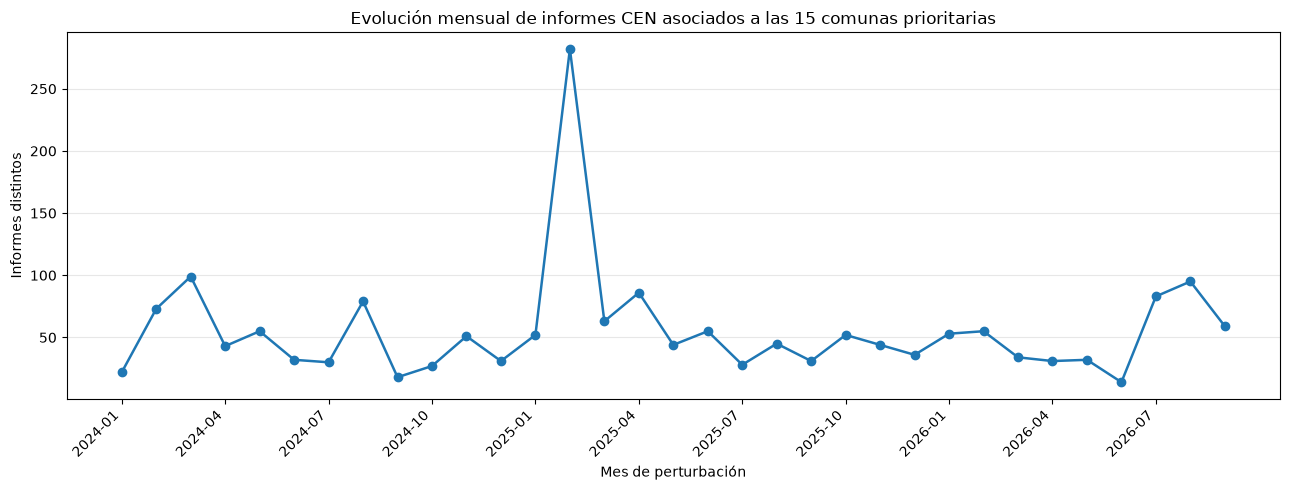

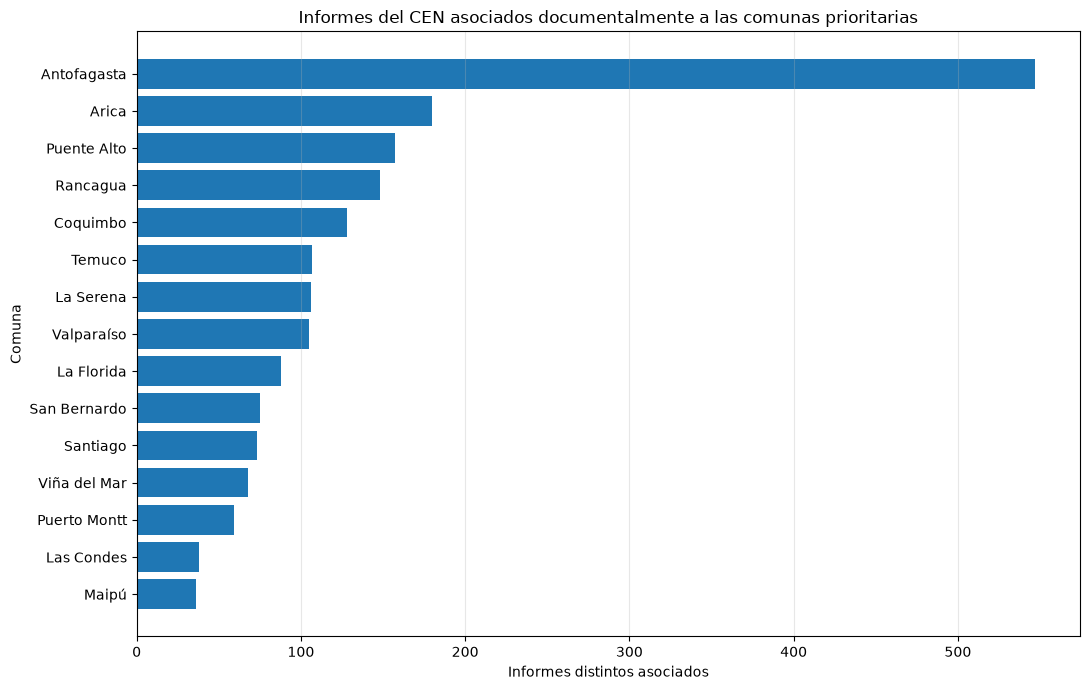

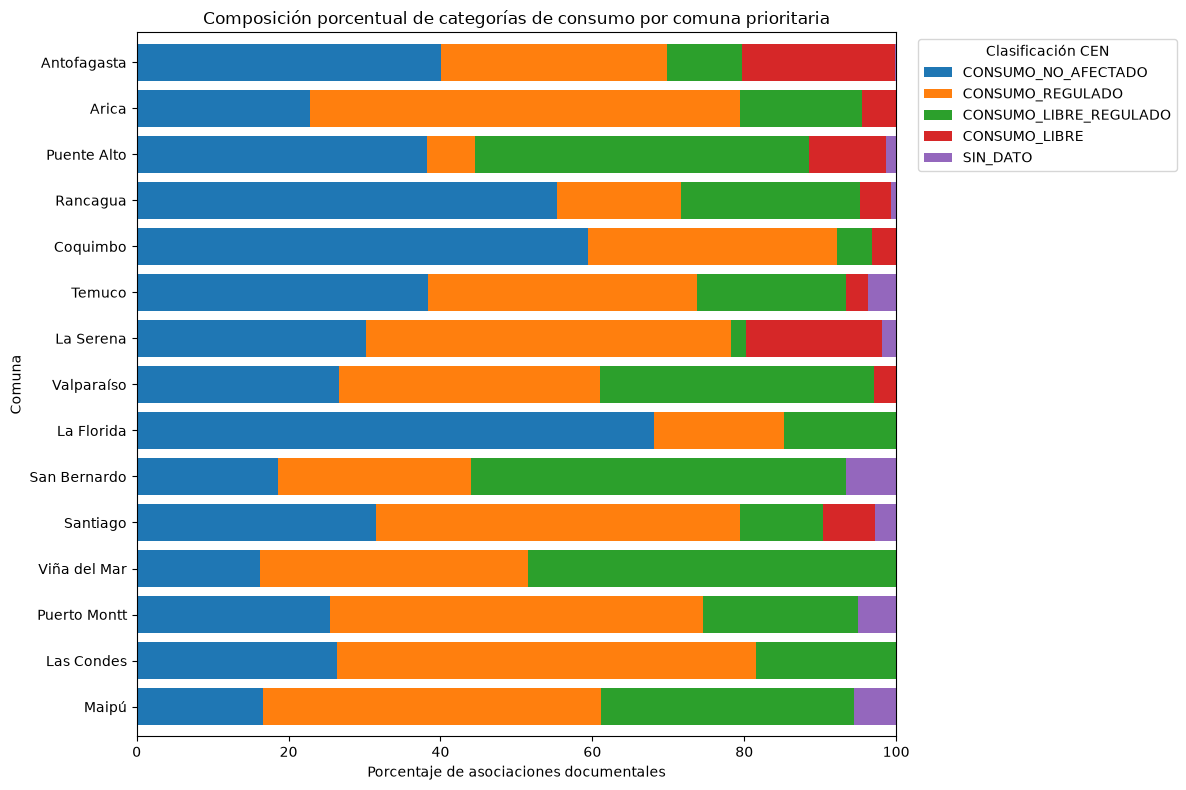

VISUALIZACIONES EXPLORATORIAS FINALIZADAS
[OK] Evolución mensual construida.
[OK] Distribución territorial construida.
[OK] Composición de consumo construida.
[OK] Integridad de los resultados verificada.


In [15]:
# ==========================================================
# FASE 2 - APARTADO 6.11
# VISUALIZACIONES EXPLORATORIAS
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


# ==========================================================
# 1. VERIFICAR CONJUNTOS DISPONIBLES
# ==========================================================

assert len(df_temporal_prioritarias) == 1834, (
    "El conjunto de informes prioritarios "
    "no coincide con el resultado esperado."
)

assert len(df_prioritarias_cen) == 1915, (
    "El conjunto de asociaciones prioritarias "
    "no coincide con el resultado esperado."
)

assert len(df_resumen_prioritarias) == 15, (
    "El resumen no contiene las 15 comunas."
)


# ==========================================================
# 2. GRÁFICO 1: EVOLUCIÓN MENSUAL
# ==========================================================

evolucion_mensual = (
    df_temporal_prioritarias
    .groupby("mes_perturbacion")
    .agg(
        informes=("id_falla", "nunique")
    )
    .sort_index()
)

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    evolucion_mensual.index,
    evolucion_mensual["informes"],
    marker="o",
    linewidth=1.8
)

ax.set_title(
    "Evolución mensual de informes CEN asociados "
    "a las 15 comunas prioritarias"
)

ax.set_xlabel("Mes de perturbación")
ax.set_ylabel("Informes distintos")

ax.grid(axis="y", alpha=0.3)

# Mostrar una etiqueta cada tres meses.

posiciones = list(
    range(0, len(evolucion_mensual), 3)
)

ax.set_xticks(posiciones)

ax.set_xticklabels(
    evolucion_mensual.index[posiciones],
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()


# ==========================================================
# 3. GRÁFICO 2: DISTRIBUCIÓN POR COMUNA
# ==========================================================

distribucion_comunal = (
    df_resumen_prioritarias[
        [
            "comuna_oficial",
            "informes_distintos"
        ]
    ]
    .sort_values("informes_distintos")
)

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    distribucion_comunal["comuna_oficial"],
    distribucion_comunal["informes_distintos"]
)

ax.set_title(
    "Informes del CEN asociados documentalmente "
    "a las comunas prioritarias"
)

ax.set_xlabel("Informes distintos asociados")
ax.set_ylabel("Comuna")

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 4. PREPARAR CLASIFICACIÓN DE CONSUMO POR COMUNA
# ==========================================================

# Construir la estructura comuna-informe.
# Cada informe puede pertenecer a varias comunas.

df_consumo_comunal = (
    df_prioritarias_cen[
        [
            "id_falla",
            "codigo_comuna"
        ]
    ]
    .merge(
        df_operacional_prioritarias[
            [
                "id_falla",
                "consumo_analitico"
            ]
        ],
        on="id_falla",
        how="left",
        validate="many_to_one"
    )
    .merge(
        df_prioritarias[
            [
                "codigo_comuna",
                "comuna_oficial"
            ]
        ],
        on="codigo_comuna",
        how="left",
        validate="many_to_one"
    )
)

assert len(df_consumo_comunal) == 1915, (
    "La integración del consumo modificó "
    "las asociaciones originales."
)

assert df_consumo_comunal[
    "comuna_oficial"
].notna().all(), (
    "Existen asociaciones sin comuna oficial."
)


# ==========================================================
# 5. CALCULAR DISTRIBUCIÓN PORCENTUAL
# ==========================================================

tabla_consumo_comunal = pd.crosstab(
    df_consumo_comunal["comuna_oficial"],
    df_consumo_comunal["consumo_analitico"]
)

categorias_consumo = [
    "CONSUMO_NO_AFECTADO",
    "CONSUMO_REGULADO",
    "CONSUMO_LIBRE_REGULADO",
    "CONSUMO_LIBRE",
    "SIN_DATO"
]

tabla_consumo_comunal = (
    tabla_consumo_comunal
    .reindex(
        columns=categorias_consumo,
        fill_value=0
    )
)

porcentaje_consumo_comunal = (
    tabla_consumo_comunal
    .div(
        tabla_consumo_comunal.sum(axis=1),
        axis=0
    )
    * 100
)

# Ordenar las comunas por cantidad de informes.

orden_comunas = (
    distribucion_comunal["comuna_oficial"].tolist()
)

porcentaje_consumo_comunal = (
    porcentaje_consumo_comunal
    .reindex(orden_comunas)
)


# ==========================================================
# 6. GRÁFICO 3: CLASIFICACIÓN DE CONSUMO POR COMUNA
# ==========================================================

fig, ax = plt.subplots(figsize=(12, 8))

porcentaje_consumo_comunal.plot(
    kind="barh",
    stacked=True,
    ax=ax,
    width=0.8
)

ax.set_title(
    "Composición porcentual de categorías "
    "de consumo por comuna prioritaria"
)

ax.set_xlabel("Porcentaje de asociaciones documentales")
ax.set_ylabel("Comuna")

ax.set_xlim(0, 100)

ax.legend(
    title="Clasificación CEN",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================================
# 7. VALIDACIÓN DE RESULTADOS
# ==========================================================

assert evolucion_mensual[
    "informes"
].sum() == 1834, (
    "La distribución temporal no coincide "
    "con el total de informes."
)

assert distribucion_comunal[
    "informes_distintos"
].sum() == 1915, (
    "La distribución comunal no coincide "
    "con las asociaciones territoriales."
)

assert tabla_consumo_comunal.to_numpy().sum() == 1915, (
    "La distribución de consumo presenta "
    "inconsistencias."
)


# ==========================================================
# 8. FINALIZAR
# ==========================================================

print("=" * 65)
print("VISUALIZACIONES EXPLORATORIAS FINALIZADAS")
print("=" * 65)

print("[OK] Evolución mensual construida.")

print("[OK] Distribución territorial construida.")

print("[OK] Composición de consumo construida.")

print("[OK] Integridad de los resultados verificada.")

### 6.11.4. Resultados e interpretación de las visualizaciones exploratorias

Las visualizaciones desarrolladas permitieron examinar la distribución temporal, territorial y operacional de los informes del Coordinador Eléctrico Nacional (CEN) asociados con las 15 comunas prioritarias seleccionadas mediante el Censo 2024.

El análisis consideró 1.834 informes distintos y 1.915 asociaciones territoriales, utilizando las variables previamente depuradas, normalizadas y validadas durante la Fase 2.

Las representaciones gráficas permiten identificar patrones relevantes para el estudio del impacto operacional documentado de las fallas del Sistema Eléctrico Nacional (SEN).

**Figura 1. Evolución mensual de informes asociados a las comunas prioritarias**

La primera visualización representa la evolución mensual de los 1.834 informes distintos durante el período comprendido entre enero de 2024 y septiembre de 2026.

Los resultados evidencian una distribución temporal variable, con períodos de concentración y disminución en la cantidad de documentos registrados.

El principal hallazgo corresponde a febrero de 2025, cuando se identificaron **282 informes**, equivalentes al 15,38 % del conjunto prioritario.

Este comportamiento constituye una concentración documental excepcional respecto de los meses restantes y representa un período de interés para el análisis operacional posterior.

Sin embargo, la concentración no permite establecer por sí sola la causa de los registros. Para determinar su relación con acontecimientos específicos del SEN será necesario examinar las fechas, características técnicas y antecedentes documentales correspondientes.

También se observan concentraciones secundarias durante marzo de 2024, agosto de 2024, abril de 2025 y agosto de 2026.

La interpretación de las tendencias debe considerar que 2026 dispone de información solamente hasta septiembre, por lo que no corresponde comparar directamente su volumen acumulado con años completos.

**Figura 2. Distribución territorial de informes asociados con las 15 comunas prioritarias**

La segunda visualización permite comparar la cantidad de informes distintos vinculados documentalmente con cada comuna.

Los resultados muestran una distribución territorial heterogénea.

Antofagasta presenta la mayor cantidad de registros asociados, con 547 informes, seguida por Arica, con 180; Puente Alto, con 157; Rancagua, con 148; y Coquimbo, con 128.

En contraste, Maipú presenta 36 informes asociados y Las Condes registra 38.

Esta distribución evidencia que la cantidad de documentos vinculados con una comuna no mantiene necesariamente una relación proporcional con su población censada.

Por ejemplo, Puente Alto ocupa la primera posición demográfica entre las comunas seleccionadas, mientras que Antofagasta concentra el mayor número de informes asociados.

No obstante, estas diferencias no constituyen una medición directa de confiabilidad del suministro eléctrico ni permiten establecer que una comuna haya experimentado mayor cantidad de interrupciones efectivas.

Los registros pueden presentar características distintas respecto de su alcance territorial, infraestructura involucrada y condiciones administrativas.

La distribución se construyó a partir de las 1.915 asociaciones territoriales. Por ello, aunque cada comuna presenta un conteo de informes distintos, la suma de los valores comunales supera los 1.834 informes únicos del conjunto prioritario, debido a que un mismo documento puede encontrarse asociado con varias comunas.

**Figura 3. Composición porcentual de categorías de consumo por comuna prioritaria**

La tercera visualización representa la participación relativa de las categorías de consumo registradas en los informes asociados con cada comuna.

Los resultados evidencian diferencias en la composición documental de los territorios seleccionados.

En comunas como La Florida, Coquimbo y Rancagua se observa una participación importante de la categoría `CONSUMO_NO_AFECTADO`.

Por otra parte, Arica, Las Condes, Maipú y La Serena presentan una participación relevante de la categoría `CONSUMO_REGULADO`.

También se identifican comunas donde la categoría `CONSUMO_LIBRE_REGULADO` representa una proporción significativa de las asociaciones, entre ellas Puente Alto, San Bernardo y Viña del Mar.

Estas diferencias permiten reconocer perfiles documentales distintos entre los territorios y constituyen antecedentes para profundizar la caracterización operacional de los informes.

Sin embargo, las categorías de consumo pertenecen a los registros del CEN y no representan una medición directa de clientes afectados en cada comuna.

Asimismo, los porcentajes corresponden a la composición interna de las asociaciones de cada territorio. Por esta razón, deben interpretarse considerando las diferencias en el número de registros disponibles.

**Interpretación integrada de los resultados**

Las tres visualizaciones permiten reconocer características complementarias de los informes asociados a las comunas prioritarias:

| Dimensión | Principal resultado | Contribución al proyecto |
|---|---|---|
| Temporal | Concentración de 282 informes durante febrero de 2025. | Identificar períodos que requieren revisión operacional. |
| Territorial | Antofagasta concentra 547 informes asociados. | Reconocer diferencias en la presencia documental entre comunas. |
| Operacional | Se observan diferencias en la composición de categorías de consumo. | Caracterizar los antecedentes operacionales registrados en cada territorio. |

Los resultados permiten avanzar desde la exploración individual de variables hacia una caracterización integrada de los informes del SEN.

Desde la perspectiva del objetivo del proyecto, el procesamiento ha permitido identificar **dónde, cuándo y bajo qué clasificaciones operacionales se documentan los informes asociados a las comunas prioritarias**.

No obstante, se mantiene una distinción metodológica fundamental: los registros analizados representan asociaciones documentales de fallas y no mediciones directas de interrupciones efectivas, clientes afectados, energía no suministrada o duración real de los cortes eléctricos comunales.

Por lo tanto, las visualizaciones constituyen evidencia descriptiva para orientar el análisis del impacto operacional documentado, sin establecer relaciones causales ni indicadores de continuidad que no puedan sustentarse mediante las fuentes disponibles.

**Validación de las visualizaciones**

El código incorpora comprobaciones orientadas a verificar la consistencia entre los datos representados y los conjuntos procesados.

Los controles consideran:

1. La correspondencia entre la distribución mensual y los 1.834 informes únicos.
2. La consistencia entre la distribución territorial y las 1.915 asociaciones comunales.
3. La conservación de las asociaciones al incorporar las categorías de consumo.
4. La correspondencia entre las frecuencias de consumo comunal y el total de asociaciones disponibles.

Estas verificaciones permiten mantener trazabilidad entre los datos preparados y las representaciones gráficas.

Con estos resultados se completa la exploración visual inicial de las dimensiones temporal, territorial y operacional del proyecto.

## 6.12. Caracterización de las principales fallas documentadas en las comunas prioritarias

### 6.12.1. Fundamentación técnica

El análisis del impacto operacional documentado de las fallas del Sistema Eléctrico Nacional (SEN) requiere identificar las características técnicas de los informes registrados por el Coordinador Eléctrico Nacional (CEN).

En los apartados anteriores se integraron los antecedentes territoriales, operacionales y temporales de 1.834 informes distintos, vinculados mediante 1.915 asociaciones documentales con las 15 comunas prioritarias seleccionadas a partir del Censo 2024.

A partir de estos resultados, corresponde examinar la naturaleza de las fallas registradas, considerando sus tipos, causas, origen y distribución territorial.

Este procedimiento permitirá identificar patrones recurrentes y acontecimientos que requieren una revisión específica de sus antecedentes técnicos.

### 6.12.2. Variables técnicas de análisis

Se utilizarán las siguientes variables disponibles en el conjunto de datos del CEN:

| Variable | Descripción | Aplicación en el análisis |
|---|---|---|
| `Tipo` | Clasificación de la instalación asociada al informe. | Identificar registros de líneas, subestaciones y centrales generadoras. |
| `Origen` | Clasificación de origen interno o externo. | Caracterizar el origen informado. |
| `Tipo Causa` | Condición presunta o definitiva de la causa. | Diferenciar el grado de definición de los antecedentes causales. |
| `Causa Definitiva` | Campo que contiene la descripción de causa registrada. | Identificar las descripciones más frecuentes. |
| `estado_normalizado` | Estado administrativo del informe. | Contextualizar la situación documental. |
| `consumo_normalizado` | Clasificación de consumo registrada. | Caracterizar antecedentes operacionales. |
| `fecha_perturbacion_dt` | Fecha y hora de perturbación procesada. | Reconocer concentraciones temporales. |
| `codigo_comuna` | Identificador territorial oficial. | Relacionar registros con comunas prioritarias. |

Debe considerarse que el campo `Causa Definitiva` puede contener descripciones como «Se investiga» y que la variable `Tipo Causa` distingue entre causas presuntas y definitivas. Por lo tanto, ambas variables deben analizarse conjuntamente y no debe suponerse que todas las descripciones corresponden a causas confirmadas.

### 6.12.3. Criterios para identificar fallas y acontecimientos relevantes

La identificación de los registros más relevantes se desarrollará considerando cuatro dimensiones complementarias.

**Frecuencia documental**

Se determinarán los tipos de instalación, orígenes y descripciones de causas más frecuentes en los informes asociados con las comunas prioritarias.

**Concentración temporal**

Se identificarán las fechas que concentran mayor cantidad de informes, con especial atención a febrero de 2025, período que presentó una concentración significativa durante la exploración temporal.

**Alcance territorial documentado**

Se identificarán los informes asociados con más de una comuna prioritaria, considerando la cantidad de territorios vinculados dentro del conjunto seleccionado.

**Características operacionales**

Se examinarán las clasificaciones de consumo y los estados administrativos de los informes correspondientes a los acontecimientos destacados.

### 6.12.4. Restricciones metodológicas

El concepto de *principales fallas* se utilizará inicialmente para identificar registros frecuentes, concentraciones temporales y asociaciones de mayor alcance territorial documentado.

Estos criterios no constituyen una clasificación directa de severidad física.

Un mismo acontecimiento eléctrico puede generar varios informes, por lo que la cantidad de registros no equivale necesariamente al número de fallas físicas independientes.

Asimismo, la vinculación de un informe con múltiples comunas no demuestra que todas ellas experimentaron una interrupción efectiva del suministro.

El análisis tampoco permitirá establecer automáticamente la cantidad de clientes afectados, la energía no suministrada ni el impacto económico de los acontecimientos.

Las conclusiones deberán sustentarse en las variables y antecedentes efectivamente disponibles en los registros del CEN.

El propósito de esta etapa será construir una caracterización técnica y operacional reproducible que permita identificar los principales patrones documentales y preparar análisis más específicos en las fases posteriores del proyecto.

In [16]:
# ==========================================================
# FASE 2 - APARTADO 6.12
# CARACTERIZACIÓN DE LAS PRINCIPALES FALLAS DOCUMENTADAS
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
from IPython.display import display


# ==========================================================
# 1. VERIFICAR DISPONIBILIDAD DE VARIABLES
# ==========================================================

columnas_requeridas = [
    "id_falla",
    "Tipo",
    "Origen",
    "Tipo Causa",
    "Causa Definitiva",
    "estado_normalizado",
    "consumo_normalizado",
    "fecha_perturbacion_dt"
]

faltantes = [
    columna
    for columna in columnas_requeridas
    if columna not in df_temporal_prioritarias.columns
]

if faltantes:
    raise ValueError(
        f"Faltan columnas para analizar las fallas: {faltantes}"
    )


# ==========================================================
# 2. PREPARAR BASE DE INFORMES PRIORITARIOS
# ==========================================================

df_fallas_prioritarias = (
    df_temporal_prioritarias[
        columnas_requeridas
    ].copy()
)

assert df_fallas_prioritarias["id_falla"].is_unique, (
    "Existen informes duplicados."
)

assert len(df_fallas_prioritarias) == len(
    df_temporal_prioritarias
), (
    "La preparación modificó el número de informes."
)


# ==========================================================
# 3. FUNCIÓN PARA NORMALIZAR DESCRIPCIONES
# ==========================================================

def normalizar_descripcion(valor):
    """
    Estandariza espacios y valores faltantes.

    No altera el significado de las categorías
    ni asigna causas que no estén documentadas.
    """

    if pd.isna(valor):
        return "SIN_DATO"

    texto = " ".join(str(valor).strip().split())

    if not texto:
        return "SIN_DATO"

    return texto


# ==========================================================
# 4. CREAR VARIABLES TÉCNICAS ANALÍTICAS
# ==========================================================

df_fallas_prioritarias["tipo_instalacion"] = (
    df_fallas_prioritarias["Tipo"]
    .map(normalizar_descripcion)
    .astype("string")
)

df_fallas_prioritarias["origen_falla"] = (
    df_fallas_prioritarias["Origen"]
    .map(normalizar_descripcion)
    .astype("string")
)

df_fallas_prioritarias["tipo_causa"] = (
    df_fallas_prioritarias["Tipo Causa"]
    .map(normalizar_descripcion)
    .astype("string")
)

df_fallas_prioritarias["descripcion_causa"] = (
    df_fallas_prioritarias["Causa Definitiva"]
    .map(normalizar_descripcion)
    .astype("string")
)

# Identificar el día de perturbación.

df_fallas_prioritarias["dia_perturbacion"] = (
    df_fallas_prioritarias["fecha_perturbacion_dt"]
    .dt.normalize()
)


# ==========================================================
# 5. FUNCIÓN PARA TABLAS DE FRECUENCIA
# ==========================================================

def frecuencia_fallas(df, columna):

    tabla = (
        df.groupby(
            columna,
            dropna=False
        )
        .agg(
            informes=("id_falla", "nunique")
        )
        .reset_index()
        .sort_values(
            "informes",
            ascending=False
        )
        .reset_index(drop=True)
    )

    tabla["porcentaje"] = (
        tabla["informes"] / len(df) * 100
    ).round(2)

    return tabla


# ==========================================================
# 6. IDENTIFICAR TIPOS DE INSTALACIÓN
# ==========================================================

tabla_tipos = frecuencia_fallas(
    df_fallas_prioritarias,
    "tipo_instalacion"
)

print("=" * 65)
print("CARACTERIZACIÓN TÉCNICA DE INFORMES PRIORITARIOS")
print("=" * 65)

print("\nTIPOS DE INSTALACIÓN")

display(tabla_tipos)


# ==========================================================
# 7. IDENTIFICAR ORIGEN DE LAS FALLAS
# ==========================================================

tabla_origen = frecuencia_fallas(
    df_fallas_prioritarias,
    "origen_falla"
)

print("\nORIGEN DE LAS FALLAS")

display(tabla_origen)


# ==========================================================
# 8. IDENTIFICAR TIPO DE CAUSA
# ==========================================================

tabla_tipo_causa = frecuencia_fallas(
    df_fallas_prioritarias,
    "tipo_causa"
)

print("\nCONDICIÓN DE LAS CAUSAS")

display(tabla_tipo_causa)


# ==========================================================
# 9. IDENTIFICAR DESCRIPCIONES DE CAUSAS FRECUENTES
# ==========================================================

tabla_causas = frecuencia_fallas(
    df_fallas_prioritarias,
    "descripcion_causa"
)

print("\nPRINCIPALES DESCRIPCIONES DE CAUSAS")

display(
    tabla_causas.head(15)
)


# ==========================================================
# 10. RELACIONAR TIPO DE INSTALACIÓN Y TIPO DE CAUSA
# ==========================================================

print("\nTIPO DE INSTALACIÓN SEGÚN CONDICIÓN DE CAUSA")

tabla_instalacion_causa = pd.crosstab(
    df_fallas_prioritarias["tipo_instalacion"],
    df_fallas_prioritarias["tipo_causa"],
    margins=True,
    margins_name="TOTAL"
)

display(tabla_instalacion_causa)


# ==========================================================
# 11. IDENTIFICAR FECHAS DE MAYOR CONCENTRACIÓN
# ==========================================================

tabla_dias = (
    df_fallas_prioritarias
    .groupby(
        "dia_perturbacion",
        dropna=False
    )
    .agg(
        informes=("id_falla", "nunique")
    )
    .reset_index()
    .sort_values(
        "informes",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nDÍAS CON MAYOR CONCENTRACIÓN DE INFORMES")

display(
    tabla_dias.head(10)
)


# ==========================================================
# 12. IDENTIFICAR INFORMES MULTICOMUNALES
# ==========================================================

tabla_alcance = (
    df_temporal_asociaciones
    .groupby(
        "id_falla",
        as_index=False
    )
    .agg(
        numero_comunas_prioritarias=(
            "codigo_comuna",
            "nunique"
        ),
        comunas_asociadas=(
            "comuna_oficial",
            lambda serie: " | ".join(
                sorted(set(serie.dropna()))
            )
        )
    )
)

assert tabla_alcance["id_falla"].is_unique, (
    "La agrupación generó identificadores duplicados."
)

informes_multicomunales = tabla_alcance.loc[
    tabla_alcance["numero_comunas_prioritarias"] > 1
].copy()

informes_multicomunales = (
    informes_multicomunales
    .merge(
        df_fallas_prioritarias[
            [
                "id_falla",
                "fecha_perturbacion_dt",
                "tipo_instalacion",
                "descripcion_causa",
                "consumo_normalizado",
                "estado_normalizado"
            ]
        ],
        on="id_falla",
        how="left",
        validate="one_to_one"
    )
)

informes_multicomunales = (
    informes_multicomunales
    .sort_values(
        [
            "numero_comunas_prioritarias",
            "fecha_perturbacion_dt"
        ],
        ascending=[False, True]
    )
)

print("\nINFORMES ASOCIADOS CON VARIAS COMUNAS PRIORITARIAS")

print(
    "Cantidad de informes multicomunales:",
    len(informes_multicomunales)
)

display(
    informes_multicomunales.head(15)
)


# ==========================================================
# 13. REVISAR CONCENTRACIÓN DEL 25 DE FEBRERO DE 2025
# ==========================================================

fecha_interes = pd.Timestamp("2025-02-25")

df_evento_febrero = (
    df_fallas_prioritarias.loc[
        df_fallas_prioritarias[
            "dia_perturbacion"
        ].eq(fecha_interes)
    ].copy()
)

print("\n" + "=" * 65)
print("REVISIÓN DOCUMENTAL - 25 DE FEBRERO DE 2025")
print("=" * 65)

print(
    "Informes prioritarios de la fecha:",
    len(df_evento_febrero)
)

print(
    "Porcentaje del conjunto prioritario:",
    f"{len(df_evento_febrero) / len(df_fallas_prioritarias) * 100:.2f}%"
)


# ==========================================================
# 14. TIPOS DE INSTALACIÓN EN LA FECHA ANALIZADA
# ==========================================================

print("\nTIPOS DE INSTALACIÓN - 25 DE FEBRERO")

display(
    frecuencia_fallas(
        df_evento_febrero,
        "tipo_instalacion"
    )
)


# ==========================================================
# 15. DESCRIPCIONES DE CAUSA EN LA FECHA ANALIZADA
# ==========================================================

print("\nDESCRIPCIONES DE CAUSA - 25 DE FEBRERO")

display(
    frecuencia_fallas(
        df_evento_febrero,
        "descripcion_causa"
    ).head(15)
)


# ==========================================================
# 16. CLASIFICACIÓN DE CONSUMO EN LA FECHA ANALIZADA
# ==========================================================

print("\nCLASIFICACIÓN DE CONSUMO - 25 DE FEBRERO")

display(
    frecuencia_fallas(
        df_evento_febrero,
        "consumo_normalizado"
    )
)


# ==========================================================
# 17. ESTADOS ADMINISTRATIVOS EN LA FECHA ANALIZADA
# ==========================================================

print("\nESTADOS ADMINISTRATIVOS - 25 DE FEBRERO")

display(
    frecuencia_fallas(
        df_evento_febrero,
        "estado_normalizado"
    )
)


# ==========================================================
# 18. COMUNAS ASOCIADAS CON LOS INFORMES DE LA FECHA
# ==========================================================

df_asociaciones_febrero = (
    df_temporal_asociaciones.loc[
        df_temporal_asociaciones[
            "fecha_perturbacion_dt"
        ].dt.normalize().eq(fecha_interes)
    ].copy()
)

tabla_comunas_febrero = (
    df_asociaciones_febrero
    .groupby(
        "comuna_oficial",
        as_index=False
    )
    .agg(
        informes=("id_falla", "nunique")
    )
    .sort_values(
        "informes",
        ascending=False
    )
)

print("\nCOMUNAS PRIORITARIAS ASOCIADAS - 25 DE FEBRERO")

display(
    tabla_comunas_febrero
)


# ==========================================================
# 19. VALIDACIONES DE INTEGRIDAD
# ==========================================================

total_prioritarios = len(df_fallas_prioritarias)

assert total_prioritarios == len(
    df_temporal_prioritarias
), (
    "Se modificó el conjunto prioritario."
)

assert tabla_tipos["informes"].sum() == total_prioritarios

assert tabla_origen["informes"].sum() == total_prioritarios

assert tabla_tipo_causa["informes"].sum() == total_prioritarios

assert tabla_causas["informes"].sum() == total_prioritarios

assert tabla_dias["informes"].sum() == total_prioritarios

assert tabla_alcance["numero_comunas_prioritarias"].sum() == len(
    df_temporal_asociaciones
), (
    "El alcance territorial no coincide "
    "con las asociaciones originales."
)

assert df_evento_febrero["id_falla"].is_unique, (
    "Existen documentos duplicados "
    "en la revisión de febrero."
)

assert len(df_asociaciones_febrero) >= len(
    df_evento_febrero
), (
    "La revisión territorial presenta inconsistencias."
)


# ==========================================================
# 20. RESUMEN FINAL
# ==========================================================

print("\n" + "=" * 65)
print("CARACTERIZACIÓN DE FALLAS FINALIZADA")
print("=" * 65)

print(
    "Informes prioritarios analizados:",
    total_prioritarios
)

print(
    "Asociaciones territoriales:",
    len(df_temporal_asociaciones)
)

print(
    "Informes vinculados con varias comunas prioritarias:",
    len(informes_multicomunales)
)

print(
    "Informes prioritarios del 25 de febrero de 2025:",
    len(df_evento_febrero)
)

print("\n[OK] Tipos de instalación caracterizados.")

print("[OK] Orígenes y causas documentales caracterizados.")

print("[OK] Concentraciones temporales identificadas.")

print("[OK] Asociaciones multicomunales revisadas.")

print("[OK] Integridad de los conjuntos verificada.")

CARACTERIZACIÓN TÉCNICA DE INFORMES PRIORITARIOS

TIPOS DE INSTALACIÓN


,tipo_instalacion,informes,porcentaje
0,subestacion,1289,70.28
1,linea,311,16.96
2,central_generadora,234,12.76



ORIGEN DE LAS FALLAS


,origen_falla,informes,porcentaje
0,externo,1292,70.45
1,interno,542,29.55



CONDICIÓN DE LAS CAUSAS


,tipo_causa,informes,porcentaje
0,causa_presunta,1282,69.9
1,causa_definitiva,552,30.1


... (15 outputs left out)

,estado_normalizado,informes,porcentaje
0,PENDIENTE,182,83.49
1,FINALIZADO,19,8.72
2,ANULADO,17,7.80



COMUNAS PRIORITARIAS ASOCIADAS - 25 DE FEBRERO


,comuna_oficial,informes
0,Antofagasta,82
1,Arica,26
9,Rancagua,19
13,Valparaíso,19
2,Coquimbo,15
7,Puente Alto,14
12,Temuco,14
14,Viña del Mar,11
10,San Bernardo,9
4,La Serena,9



CARACTERIZACIÓN DE FALLAS FINALIZADA
Informes prioritarios analizados: 1834
Asociaciones territoriales: 1915
Informes vinculados con varias comunas prioritarias: 71
Informes prioritarios del 25 de febrero de 2025: 218

[OK] Tipos de instalación caracterizados.
[OK] Orígenes y causas documentales caracterizados.
[OK] Concentraciones temporales identificadas.
[OK] Asociaciones multicomunales revisadas.
[OK] Integridad de los conjuntos verificada.


### 6.12.5. Resultados e interpretación de las principales fallas documentadas

La caracterización técnica permitió analizar 1.834 informes distintos del Coordinador Eléctrico Nacional (CEN), asociados mediante 1.915 relaciones territoriales con las 15 comunas prioritarias seleccionadas a partir del Censo 2024.

El procesamiento examinó tipos de instalación, origen, condición de las causas, descripciones registradas, concentraciones temporales y alcance territorial documentado.

**Distribución por tipo de instalación**

| Tipo de instalación | Informes | Porcentaje |
|---|---:|---:|
| Subestación | 1.289 | 70,28 % |
| Línea | 311 | 16,96 % |
| Central generadora | 234 | 12,76 % |
| **Total** | **1.834** | **100,00 %** |

Los informes asociados con subestaciones representan la mayor proporción del conjunto prioritario. Esta distribución identifica el tipo de instalación predominante en los registros estudiados, pero no demuestra que las subestaciones presenten necesariamente una mayor tasa de fallas, dado que no se dispone de una base de exposición comparable por tipo de instalación.

**Origen y condición de las causas**

El 70,45 % de los informes presenta origen externo, mientras que el 29,55 % registra origen interno.

Respecto de la condición causal, el 69,90 % corresponde a causas presuntas y el 30,10 % a causas definitivas.

Adicionalmente, 1.051 informes, equivalentes al 57,31 %, contienen la descripción «Se investiga».

Este resultado constituye una limitación importante para el análisis causal, dado que una proporción elevada de los documentos no permite establecer directamente un mecanismo de falla confirmado.

Por lo tanto, se distinguirán las descripciones registradas de las causas técnicamente determinadas, evitando presentar antecedentes presuntos como conclusiones definitivas.

**Concentración temporal de informes**

El 25 de febrero de 2025 constituye la fecha con mayor concentración documental dentro del conjunto prioritario, con 218 informes, equivalentes al 11,89 % del total.

En esa fecha se identificaron:

| Característica | Informes |
|---|---:|
| Asociados con subestaciones | 183 |
| Asociados con centrales generadoras | 27 |
| Asociados con líneas | 8 |
| Con descripción «Balckout del sistema» | 92 |
| Con descripción «Se investiga» | 72 |
| Clasificados como pendientes | 182 |

La concentración de registros y la presencia de referencias al blackout del sistema justifican una revisión específica de los antecedentes correspondientes a esta fecha.

Sin embargo, los 218 informes no deben interpretarse como 218 fallas físicas independientes ni atribuirse automáticamente a un único acontecimiento sin comprobar sus relaciones documentales.

**Alcance territorial documentado**

Se identificaron 71 informes asociados con más de una comuna prioritaria. Algunos documentos presentan asociaciones con hasta cinco comunas del conjunto seleccionado.

Este resultado evidencia que la estructura documental puede representar acontecimientos o condiciones registradas en varios territorios.

La cantidad de comunas asociadas constituye una medida de alcance documental, no una estimación directa del territorio efectivamente interrumpido.

**Caracterización del 25 de febrero de 2025**

En la fecha de mayor concentración, Antofagasta presentó 82 informes asociados, seguida por Arica, con 26; Rancagua y Valparaíso, con 19 cada una; y Coquimbo, con 15.

Las restantes comunas también presentan asociaciones documentales con informes de esa fecha.

Asimismo, las clasificaciones de consumo incluyen 78 informes de consumo regulado, 59 de consumo libre y regulado, 54 de consumo no afectado y 27 de consumo libre.

Esta composición evidencia que la concentración temporal presenta distintas características operacionales registradas.

**Interpretación integrada**

Los resultados permiten identificar patrones técnicos, temporales y territoriales de los informes de falla asociados con las comunas prioritarias.

Sin embargo, la frecuencia documental, las descripciones causales y las clasificaciones de consumo no constituyen por sí mismas una medición directa de severidad, duración efectiva de interrupciones, clientes afectados o energía no suministrada.

Por esta razón, el análisis se concentrará en caracterizar el impacto operacional documentado y reconocer acontecimientos relevantes que puedan estudiarse con mayor profundidad mediante sus antecedentes técnicos.

Las visualizaciones siguientes permitirán comunicar estos hallazgos y facilitar su interpretación.

### 6.12.6. Visualización de las características técnicas, operacionales y territoriales

Con el propósito de facilitar la interpretación de las principales características de los informes de falla, se desarrollarán seis visualizaciones complementarias mediante Matplotlib.

Las figuras representarán las siguientes dimensiones:

| Figura | Visualización | Propósito |
|---|---|---|
| 1 | Distribución por tipo de instalación | Identificar los tipos de instalación predominantes. |
| 2 | Principales descripciones de causas | Reconocer las categorías documentales más frecuentes. |
| 3 | Fechas de mayor concentración de informes | Identificar períodos relevantes para el análisis operacional. |
| 4 | Número de comunas prioritarias por informe | Caracterizar el alcance territorial documentado. |
| 5 | Distribución comunal del 25 de febrero de 2025 | Examinar las asociaciones territoriales de la fecha destacada. |
| 6 | Clasificación de consumo del 25 de febrero de 2025 | Caracterizar los antecedentes operacionales registrados. |

Las visualizaciones utilizarán las estructuras de datos generadas en el apartado anterior, sin modificar los informes originales.

Las representaciones distinguirán entre informes únicos y asociaciones territoriales, evitando interpretar los conteos documentales como mediciones directas de interrupciones efectivas del suministro eléctrico.

Las figuras también se guardarán en formato PNG para facilitar su incorporación al informe técnico institucional.

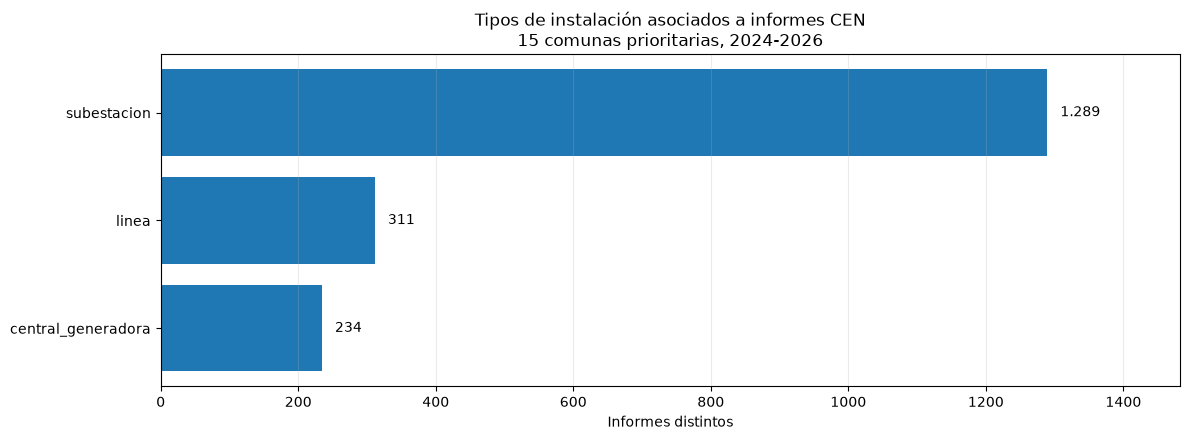

[OK] Figura guardada: /home/girosmedia/Magister/MCDI500_Programacion/Proyecto_MCDI500/F2/figuras/F2_612_Figura_01_Tipos_Instalacion.png


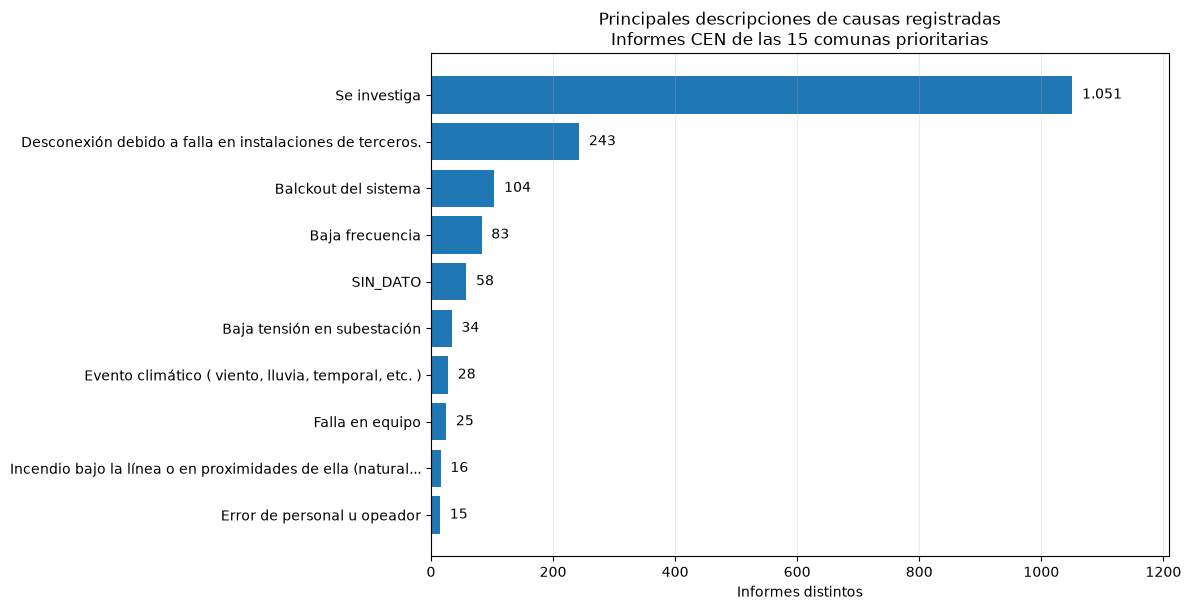

[OK] Figura guardada: /home/girosmedia/Magister/MCDI500_Programacion/Proyecto_MCDI500/F2/figuras/F2_612_Figura_02_Causas.png


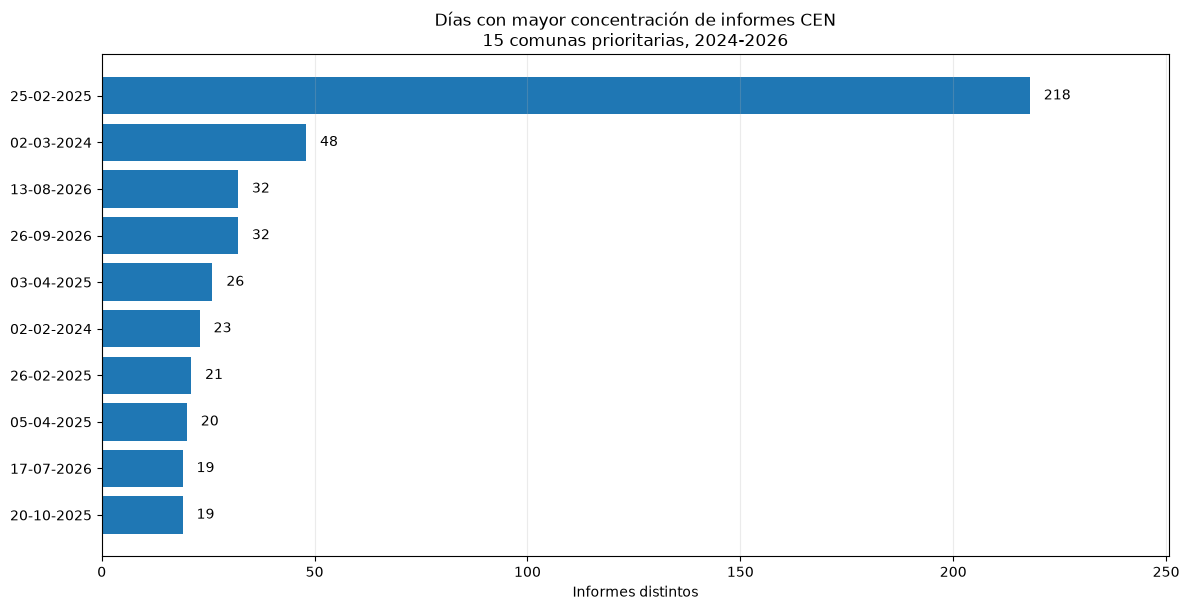

[OK] Figura guardada: /home/girosmedia/Magister/MCDI500_Programacion/Proyecto_MCDI500/F2/figuras/F2_612_Figura_03_Concentracion_Diaria.png


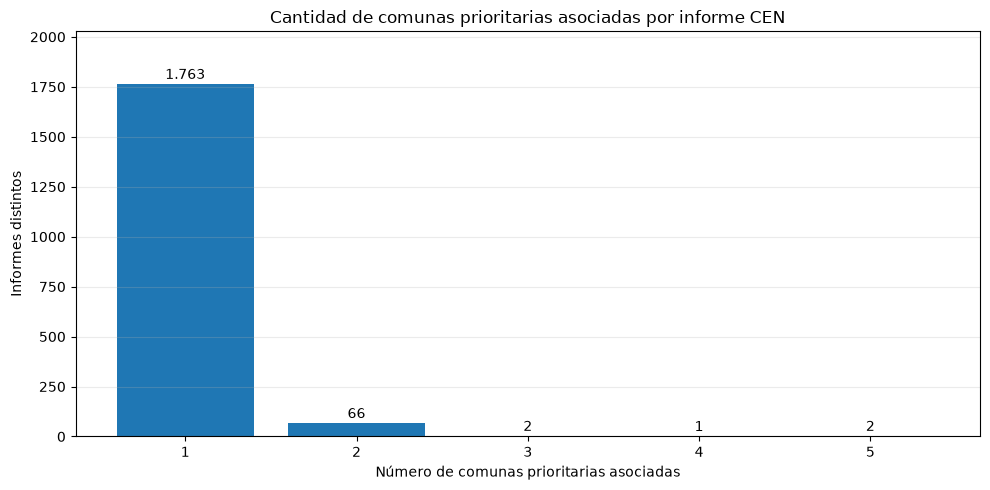

[OK] Figura guardada: /home/girosmedia/Magister/MCDI500_Programacion/Proyecto_MCDI500/F2/figuras/F2_612_Figura_04_Alcance_Territorial.png


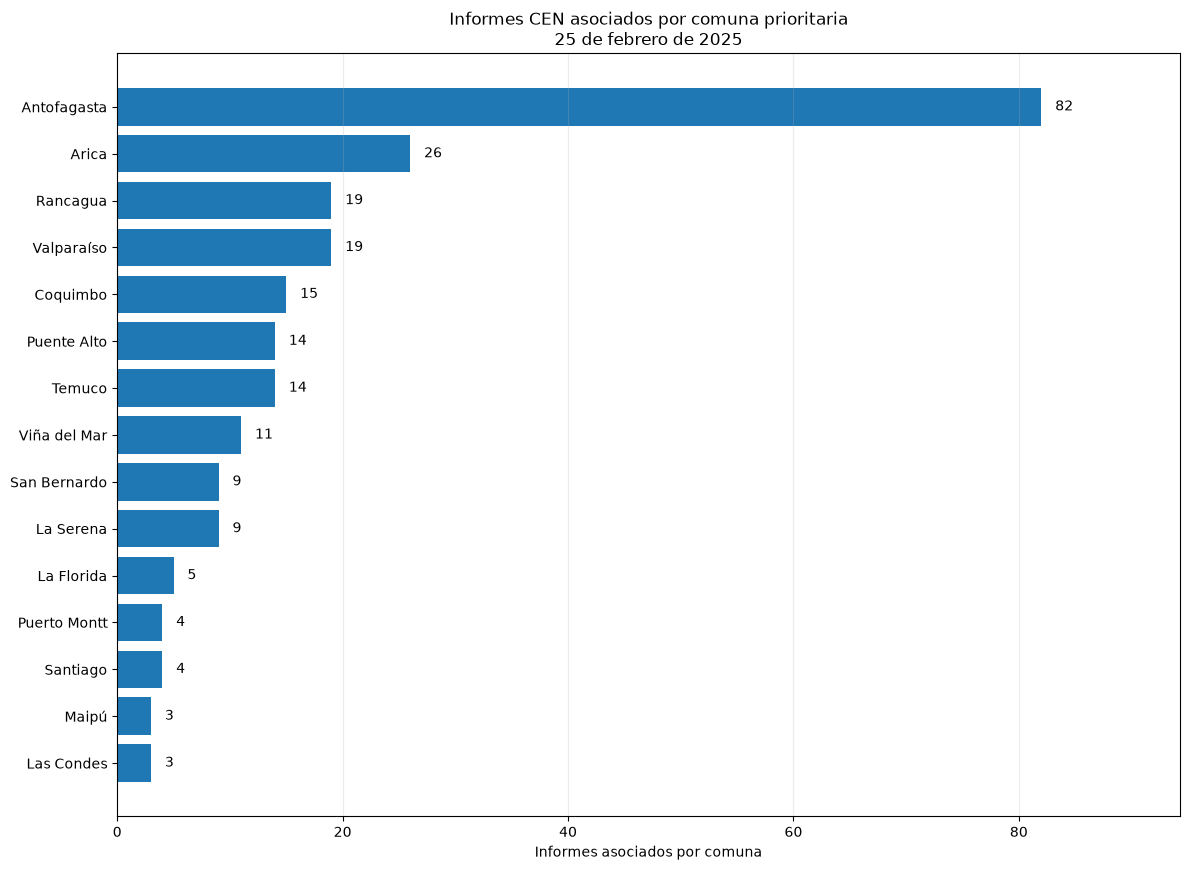

[OK] Figura guardada: /home/girosmedia/Magister/MCDI500_Programacion/Proyecto_MCDI500/F2/figuras/F2_612_Figura_05_Comunas_Febrero_2025.png


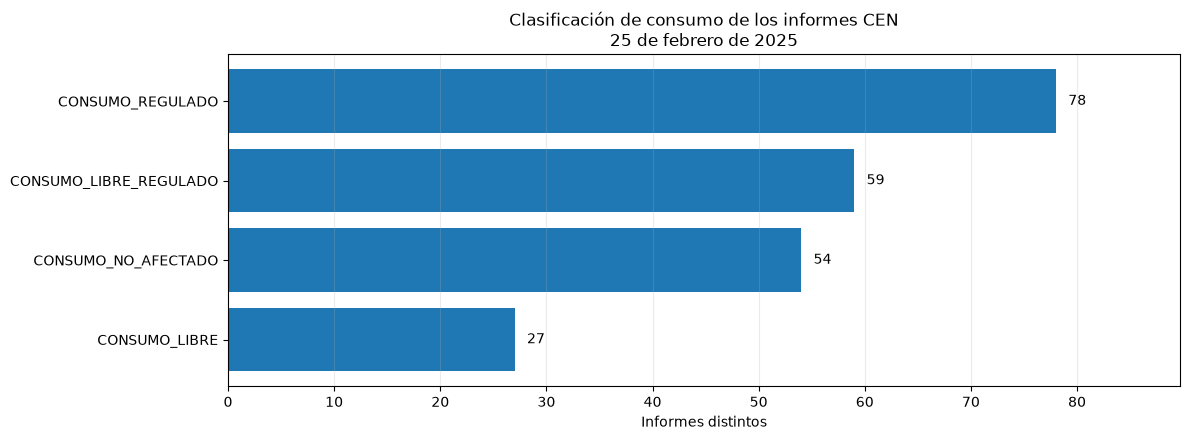

[OK] Figura guardada: /home/girosmedia/Magister/MCDI500_Programacion/Proyecto_MCDI500/F2/figuras/F2_612_Figura_06_Consumo_Febrero_2025.png

VISUALIZACIÓN DE PRINCIPALES FALLAS FINALIZADA
Informes prioritarios: 1834
Informes multicomunales: 71
Informes del 25 de febrero de 2025: 218
Figuras generadas: 6
Carpeta de resultados: /home/girosmedia/Magister/MCDI500_Programacion/Proyecto_MCDI500/F2/figuras

[OK] Distribución de instalaciones visualizada.
[OK] Principales causas visualizadas.
[OK] Concentraciones temporales visualizadas.
[OK] Alcance territorial visualizado.
[OK] Distribución comunal de febrero visualizada.
[OK] Caracterización de consumo visualizada.
[OK] Resultados validados.


In [17]:
# ==========================================================
# FASE 2 - APARTADO 6.12.6
# VISUALIZACIÓN DE LAS PRINCIPALES FALLAS DOCUMENTADAS
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt
import textwrap

from pathlib import Path
from IPython.display import display


# ==========================================================
# 1. CONFIGURAR CARPETA DE FIGURAS
# ==========================================================

carpeta_figuras = Path(RAIZ) / "F2" / "figuras"

carpeta_figuras.mkdir(
    parents=True,
    exist_ok=True
)


# ==========================================================
# 2. FUNCIÓN PARA GUARDAR FIGURAS
# ==========================================================

def guardar_figura(figura, nombre):

    ruta = carpeta_figuras / nombre

    figura.savefig(
        ruta,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    print(f"[OK] Figura guardada: {ruta}")


# ==========================================================
# 3. FUNCIÓN PARA GRÁFICOS DE BARRAS HORIZONTALES
# ==========================================================

def grafico_barras(
    tabla,
    columna_categoria,
    columna_valor,
    titulo,
    nombre_archivo,
    etiqueta_x="Informes distintos",
    ancho_etiqueta=55
):

    datos = tabla.copy()

    datos = datos.sort_values(
        columna_valor,
        ascending=False
    )

    etiquetas = [
        textwrap.shorten(
            str(valor),
            width=ancho_etiqueta,
            placeholder="..."
        )
        for valor in datos[columna_categoria]
    ]

    valores = datos[columna_valor].astype(int).tolist()

    posiciones = list(range(len(datos)))

    altura = max(
        4.5,
        len(datos) * 0.52 + 1
    )

    fig, ax = plt.subplots(
        figsize=(12, altura)
    )

    ax.barh(
        posiciones,
        valores
    )

    ax.set_yticks(posiciones)

    ax.set_yticklabels(etiquetas)

    ax.invert_yaxis()

    ax.set_title(titulo)

    ax.set_xlabel(etiqueta_x)

    ax.grid(
        axis="x",
        alpha=0.25
    )

    maximo = max(valores) if valores else 1

    ax.set_xlim(
        0,
        maximo * 1.15
    )

    # Incorporar valor en cada barra.

    for posicion, valor in zip(posiciones, valores):

        ax.text(
            valor + maximo * 0.015,
            posicion,
            f"{valor:,}".replace(",", "."),
            va="center"
        )

    fig.tight_layout()

    guardar_figura(
        fig,
        nombre_archivo
    )


# ==========================================================
# 4. FIGURA 1 - TIPOS DE INSTALACIÓN
# ==========================================================

grafico_barras(
    tabla=tabla_tipos,
    columna_categoria="tipo_instalacion",
    columna_valor="informes",
    titulo=(
        "Tipos de instalación asociados a informes CEN\n"
        "15 comunas prioritarias, 2024-2026"
    ),
    nombre_archivo="F2_612_Figura_01_Tipos_Instalacion.png"
)


# ==========================================================
# 5. FIGURA 2 - PRINCIPALES DESCRIPCIONES DE CAUSAS
# ==========================================================

principales_causas = (
    tabla_causas
    .head(10)
    .copy()
)

grafico_barras(
    tabla=principales_causas,
    columna_categoria="descripcion_causa",
    columna_valor="informes",
    titulo=(
        "Principales descripciones de causas registradas\n"
        "Informes CEN de las 15 comunas prioritarias"
    ),
    nombre_archivo="F2_612_Figura_02_Causas.png",
    ancho_etiqueta=60
)


# ==========================================================
# 6. FIGURA 3 - DÍAS DE MAYOR CONCENTRACIÓN
# ==========================================================

principales_dias = (
    tabla_dias
    .dropna(subset=["dia_perturbacion"])
    .head(10)
    .copy()
)

principales_dias["fecha_grafico"] = (
    pd.to_datetime(
        principales_dias["dia_perturbacion"]
    )
    .dt.strftime("%d-%m-%Y")
)

grafico_barras(
    tabla=principales_dias,
    columna_categoria="fecha_grafico",
    columna_valor="informes",
    titulo=(
        "Días con mayor concentración de informes CEN\n"
        "15 comunas prioritarias, 2024-2026"
    ),
    nombre_archivo="F2_612_Figura_03_Concentracion_Diaria.png"
)


# ==========================================================
# 7. FIGURA 4 - ALCANCE TERRITORIAL DOCUMENTADO
# ==========================================================

distribucion_alcance = (
    tabla_alcance[
        "numero_comunas_prioritarias"
    ]
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    distribucion_alcance.index.astype(str),
    distribucion_alcance.values
)

ax.set_title(
    "Cantidad de comunas prioritarias asociadas por informe CEN"
)

ax.set_xlabel(
    "Número de comunas prioritarias asociadas"
)

ax.set_ylabel(
    "Informes distintos"
)

ax.grid(
    axis="y",
    alpha=0.25
)

altura_maxima = distribucion_alcance.max()

ax.set_ylim(
    0,
    altura_maxima * 1.15
)

for posicion, valor in enumerate(
    distribucion_alcance.values
):

    ax.text(
        posicion,
        valor + altura_maxima * 0.015,
        f"{valor:,}".replace(",", "."),
        ha="center"
    )

fig.tight_layout()

guardar_figura(
    fig,
    "F2_612_Figura_04_Alcance_Territorial.png"
)


# ==========================================================
# 8. FIGURA 5 - COMUNAS ASOCIADAS EL 25 DE FEBRERO
# ==========================================================

grafico_barras(
    tabla=tabla_comunas_febrero,
    columna_categoria="comuna_oficial",
    columna_valor="informes",
    titulo=(
        "Informes CEN asociados por comuna prioritaria\n"
        "25 de febrero de 2025"
    ),
    nombre_archivo="F2_612_Figura_05_Comunas_Febrero_2025.png",
    etiqueta_x="Informes asociados por comuna"
)


# ==========================================================
# 9. PREPARAR CONSUMO DEL 25 DE FEBRERO
# ==========================================================

consumo_febrero = (
    df_evento_febrero[
        "consumo_normalizado"
    ]
    .astype("string")
    .fillna("SIN_DATO")
    .value_counts()
    .rename_axis("categoria_consumo")
    .reset_index(name="informes")
)


# ==========================================================
# 10. FIGURA 6 - CONSUMO DEL 25 DE FEBRERO
# ==========================================================

grafico_barras(
    tabla=consumo_febrero,
    columna_categoria="categoria_consumo",
    columna_valor="informes",
    titulo=(
        "Clasificación de consumo de los informes CEN\n"
        "25 de febrero de 2025"
    ),
    nombre_archivo="F2_612_Figura_06_Consumo_Febrero_2025.png"
)


# ==========================================================
# 11. VALIDACIONES DE INTEGRIDAD
# ==========================================================

total_informes = len(df_fallas_prioritarias)

assert tabla_tipos["informes"].sum() == total_informes, (
    "La distribución de instalaciones no coincide."
)

assert tabla_causas["informes"].sum() == total_informes, (
    "La distribución de causas no coincide."
)

assert tabla_dias["informes"].sum() == total_informes, (
    "La distribución diaria no coincide."
)

assert distribucion_alcance.sum() == total_informes, (
    "La distribución territorial no coincide."
)

assert (
    tabla_alcance[
        "numero_comunas_prioritarias"
    ].sum()
    == len(df_temporal_asociaciones)
), (
    "El alcance territorial no coincide "
    "con el total de asociaciones."
)

assert (
    tabla_comunas_febrero["informes"].sum()
    == len(df_asociaciones_febrero)
), (
    "La distribución comunal de febrero es inconsistente."
)

assert consumo_febrero["informes"].sum() == len(
    df_evento_febrero
), (
    "La distribución de consumo es inconsistente."
)


# ==========================================================
# 12. VALIDAR ARCHIVOS GENERADOS
# ==========================================================

archivos_png = list(
    carpeta_figuras.glob("F2_612_Figura_*.png")
)

assert len(archivos_png) == 6, (
    "No se encontraron las seis figuras esperadas."
)


# ==========================================================
# 13. RESUMEN FINAL
# ==========================================================

print("\n" + "=" * 65)
print("VISUALIZACIÓN DE PRINCIPALES FALLAS FINALIZADA")
print("=" * 65)

print("Informes prioritarios:", total_informes)

print(
    "Informes multicomunales:",
    len(informes_multicomunales)
)

print(
    "Informes del 25 de febrero de 2025:",
    len(df_evento_febrero)
)

print(
    "Figuras generadas:",
    len(archivos_png)
)

print(
    "Carpeta de resultados:",
    carpeta_figuras
)

print("\n[OK] Distribución de instalaciones visualizada.")
print("[OK] Principales causas visualizadas.")
print("[OK] Concentraciones temporales visualizadas.")
print("[OK] Alcance territorial visualizado.")
print("[OK] Distribución comunal de febrero visualizada.")
print("[OK] Caracterización de consumo visualizada.")
print("[OK] Resultados validados.")

### 6.12.7. Resultados e interpretación de las visualizaciones técnicas

Las seis visualizaciones desarrolladas permitieron representar las principales características técnicas, causales, temporales y territoriales de los 1.834 informes distintos del Coordinador Eléctrico Nacional (CEN) vinculados con las 15 comunas prioritarias.

Los resultados constituyen antecedentes para caracterizar el impacto operacional documentado de las fallas del Sistema Eléctrico Nacional (SEN).

**Figura 1. Distribución por tipo de instalación**

La mayor proporción de informes corresponde a subestaciones, con 1.289 documentos, equivalentes al 70,28 % del conjunto prioritario.

Las líneas representan el 16,96 %, mientras que las centrales generadoras corresponden al 12,76 %.

Este resultado permite identificar que las subestaciones constituyen el tipo de instalación predominante en la documentación analizada.

Sin embargo, la distribución corresponde a la frecuencia de informes y no a tasas comparables de fallas por tipo de instalación.

**Figura 2. Principales descripciones de causas**

La descripción «Se investiga» concentra 1.051 informes, equivalentes al 57,31 % del conjunto.

Entre las demás categorías destacan la desconexión por fallas en instalaciones de terceros, con 243 documentos; «Balckout del sistema», con 104; y baja frecuencia, con 83.

La elevada presencia de descripciones no concluyentes evidencia limitaciones en la información causal disponible.

Por lo tanto, las categorías deberán interpretarse considerando la condición presunta o definitiva de las causas registradas.

**Figura 3. Días con mayor concentración de informes**

El 25 de febrero de 2025 presenta la mayor concentración documental, con 218 informes distintos.

Esta cantidad supera ampliamente los 48 documentos identificados el 2 de marzo de 2024, segunda fecha con mayor frecuencia.

El resultado permite reconocer un período de especial interés para estudiar acontecimientos relevantes del SEN.

No obstante, la concentración de informes no representa necesariamente una cantidad equivalente de fallas físicas independientes.

**Figura 4. Alcance territorial de los informes**

La distribución muestra que 1.763 informes están asociados con una sola comuna prioritaria, mientras que 71 presentan asociaciones con dos o más comunas.

Dentro de los informes multicomunales se identificaron 66 documentos asociados con dos comunas, dos con tres, uno con cuatro y dos con cinco comunas prioritarias.

La existencia de documentos multicomunales confirma la necesidad de distinguir entre informes únicos y asociaciones territoriales.

De esta manera, los 1.834 informes producen 1.915 asociaciones, sin que esta diferencia represente la ocurrencia de fallas independientes adicionales.

**Figura 5. Distribución territorial del 25 de febrero de 2025**

Durante la fecha de mayor concentración documental se identificaron asociaciones con las 15 comunas prioritarias.

Antofagasta presenta 82 informes asociados, seguida por Arica, con 26; Rancagua y Valparaíso, con 19 cada una; y Coquimbo, con 15.

La distribución permite reconocer diferencias territoriales en los registros asociados a esta fecha.

Sin embargo, la cantidad de informes no permite determinar directamente la magnitud de las interrupciones efectivas experimentadas en cada comuna.

**Figura 6. Clasificación de consumo del 25 de febrero de 2025**

Los 218 informes prioritarios de la fecha presentan las siguientes clasificaciones:

| Clasificación de consumo | Informes |
|---|---:|
| Consumo regulado | 78 |
| Consumo libre y regulado | 59 |
| Consumo no afectado | 54 |
| Consumo libre | 27 |
| **Total** | **218** |

La distribución evidencia que los informes presentan distintas clasificaciones operacionales de consumo.

Las categorías de consumo regulado, libre y mixto representan 164 documentos, mientras que 54 registros se encuentran clasificados como consumo no afectado.

Estas categorías constituyen información documental relevante, pero no permiten determinar directamente la cantidad de clientes afectados en cada comuna.

**Interpretación integrada**

Las visualizaciones permiten identificar tres hallazgos fundamentales:

1. Las subestaciones predominan entre los tipos de instalación asociados a los informes prioritarios.
2. Existe una proporción importante de descripciones causales pendientes de determinación.
3. El 25 de febrero de 2025 constituye la principal concentración temporal documentada del período analizado.

Adicionalmente, se identificaron 71 informes asociados con varias comunas prioritarias.

Estos hallazgos justifican profundizar el análisis mediante una integración de las características técnicas de los informes con su identificación territorial.

Por esta razón, el siguiente apartado desarrollará un análisis cruzado que permitirá determinar qué tipos de instalaciones, causas registradas y clasificaciones de consumo predominan en cada una de las 15 comunas prioritarias.

La caracterización resultante permitirá identificar diferencias operacionales documentadas entre territorios, manteniendo las restricciones derivadas de la naturaleza de los registros del CEN.

## 6.13. Análisis cruzado de las características de las fallas y las comunas prioritarias

### 6.13.1. Fundamentación técnica

La caracterización individual de las variables territoriales, técnicas y operacionales permitió identificar patrones relevantes en los informes del Coordinador Eléctrico Nacional (CEN).

Sin embargo, para avanzar hacia el objetivo de analizar el impacto operacional documentado de las fallas del Sistema Eléctrico Nacional sobre las 15 comunas prioritarias, resulta necesario integrar dichas dimensiones.

El análisis cruzado permitirá establecer perfiles documentales por comuna, considerando los tipos de instalación, las clasificaciones causales, los estados administrativos y las categorías de consumo.

Esta integración se realizará utilizando los códigos comunales oficiales previamente homologados y auditados.

### 6.13.2. Dimensiones de análisis

Se considerarán las siguientes dimensiones:

| Dimensión | Variable o indicador | Propósito |
|---|---|---|
| Territorial | Código y nombre de comuna | Identificar el territorio asociado. |
| Demográfica | Población censada 2024 | Contextualizar la selección territorial. |
| Documental | Informes asociados | Cuantificar la presencia documental por comuna. |
| Técnica | Tipo de instalación | Caracterizar las instalaciones asociadas. |
| Causal | Tipo y descripción de causa | Identificar condiciones causales registradas. |
| Operacional | Clasificación de consumo | Caracterizar los antecedentes de consumo informados. |
| Temporal | Fecha de perturbación | Identificar concentraciones documentales por territorio. |
| Alcance | Número de comunas asociadas | Distinguir informes de alcance documental individual y multicomunal. |

### 6.13.3. Criterios metodológicos

La unidad de análisis será la asociación entre informe y comuna.

Cada informe podrá aparecer en más de una comuna cuando la fuente documental establezca dichas relaciones.

Dentro de cada comuna, un identificador documental se contabilizará una sola vez.

Las comparaciones utilizarán frecuencias absolutas y proporciones internas por comuna, evitando interpretar las diferencias de tamaño documental como medidas directas de confiabilidad o severidad del suministro eléctrico.

La población censada se incorporará como antecedente territorial, pero no como estimación de clientes afectados.

Los resultados permitirán reconocer perfiles técnicos y operacionales documentados, identificar concentraciones relevantes y preparar futuras investigaciones sobre el comportamiento de las fallas del SEN en los territorios seleccionados.

In [18]:
# ==========================================================
# FASE 2 - APARTADO 6.13
# ANÁLISIS CRUZADO DE FALLAS Y COMUNAS PRIORITARIAS
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
from IPython.display import display


# ==========================================================
# 1. VERIFICAR DISPONIBILIDAD DE LOS CONJUNTOS
# ==========================================================

assert df_fallas_prioritarias["id_falla"].is_unique, (
    "Existen informes técnicos duplicados."
)

assert len(df_prioritarias) == 15, (
    "La selección territorial no contiene 15 comunas."
)

assert not df_temporal_asociaciones.duplicated(
    subset=["id_falla", "codigo_comuna"]
).any(), (
    "Existen asociaciones territoriales duplicadas."
)


# ==========================================================
# 2. PREPARAR VARIABLES TÉCNICAS
# ==========================================================

columnas_tecnicas = [
    "id_falla",
    "tipo_instalacion",
    "origen_falla",
    "tipo_causa",
    "descripcion_causa"
]

df_tecnico = df_fallas_prioritarias[
    columnas_tecnicas
].copy()


# ==========================================================
# 3. CONSTRUIR CONJUNTO INTEGRADO COMUNAL
# ==========================================================

df_cruce_fallas_comunas = (
    df_temporal_asociaciones.merge(
        df_tecnico,
        on="id_falla",
        how="left",
        validate="many_to_one",
        indicator=True
    )
)

assert df_cruce_fallas_comunas["_merge"].eq("both").all(), (
    "Existen asociaciones sin información técnica."
)

df_cruce_fallas_comunas = (
    df_cruce_fallas_comunas.drop(columns=["_merge"])
)

assert len(df_cruce_fallas_comunas) == len(
    df_temporal_asociaciones
), (
    "La integración modificó el número de asociaciones."
)


# ==========================================================
# 4. IDENTIFICAR CONDICIONES TÉCNICAS
# ==========================================================

def crear_indicador(serie, valor):
    """
    Devuelve 1 cuando la categoría coincide
    y 0 en los demás casos.
    """

    return (
        serie.astype("string")
        .str.strip()
        .str.casefold()
        .eq(valor.casefold())
        .fillna(False)
        .astype(int)
    )


df_cruce_fallas_comunas["es_subestacion"] = crear_indicador(
    df_cruce_fallas_comunas["tipo_instalacion"],
    "subestacion"
)

df_cruce_fallas_comunas["es_linea"] = crear_indicador(
    df_cruce_fallas_comunas["tipo_instalacion"],
    "linea"
)

df_cruce_fallas_comunas["es_central"] = crear_indicador(
    df_cruce_fallas_comunas["tipo_instalacion"],
    "central_generadora"
)

df_cruce_fallas_comunas["es_causa_presunta"] = crear_indicador(
    df_cruce_fallas_comunas["tipo_causa"],
    "causa_presunta"
)

df_cruce_fallas_comunas["es_se_investiga"] = crear_indicador(
    df_cruce_fallas_comunas["descripcion_causa"],
    "Se investiga"
)


# ==========================================================
# 5. IDENTIFICAR REFERENCIAS DOCUMENTALES A BLACKOUT
# ==========================================================

# Se consideran ambas grafías para la búsqueda.
# No se modifica la descripción original.

df_cruce_fallas_comunas["referencia_blackout"] = (
    df_cruce_fallas_comunas["descripcion_causa"]
    .astype("string")
    .str.contains(
        r"balckout|blackout",
        case=False,
        regex=True,
        na=False
    )
    .astype(int)
)


# ==========================================================
# 6. CLASIFICAR INFORMACIÓN DE CONSUMO
# ==========================================================

categorias_consumo = {
    "CONSUMO_REGULADO",
    "CONSUMO_LIBRE",
    "CONSUMO_LIBRE_REGULADO"
}

df_cruce_fallas_comunas["consumo_categoria_asociada"] = (
    df_cruce_fallas_comunas["consumo_normalizado"]
    .isin(categorias_consumo)
    .astype(int)
)

# Este indicador no mide clientes afectados.
# Solamente identifica categorías documentales.


# ==========================================================
# 7. IDENTIFICAR EL 25 DE FEBRERO DE 2025
# ==========================================================

fecha_referencia = pd.Timestamp("2025-02-25")

df_cruce_fallas_comunas["es_25_febrero_2025"] = (
    df_cruce_fallas_comunas["fecha_perturbacion_dt"]
    .dt.normalize()
    .eq(fecha_referencia)
    .astype(int)
)


# ==========================================================
# 8. IDENTIFICAR INFORMES MULTICOMUNALES
# ==========================================================

df_cruce_fallas_comunas["numero_comunas_informe"] = (
    df_cruce_fallas_comunas
    .groupby("id_falla")["codigo_comuna"]
    .transform("nunique")
)

df_cruce_fallas_comunas["es_multicomunal"] = (
    df_cruce_fallas_comunas["numero_comunas_informe"]
    .gt(1)
    .astype(int)
)


# ==========================================================
# 9. CONSTRUIR MATRIZ DE INDICADORES COMUNALES
# ==========================================================

df_indicadores_comunales = (
    df_cruce_fallas_comunas
    .groupby("codigo_comuna", as_index=False)
    .agg(
        asociaciones=("id_falla", "size"),
        informes_distintos=("id_falla", "nunique"),
        informes_subestacion=("es_subestacion", "sum"),
        informes_linea=("es_linea", "sum"),
        informes_central=("es_central", "sum"),
        causas_presuntas=("es_causa_presunta", "sum"),
        causas_en_investigacion=("es_se_investiga", "sum"),
        referencias_blackout=("referencia_blackout", "sum"),
        consumo_categoria_asociada=(
            "consumo_categoria_asociada",
            "sum"
        ),
        informes_25_febrero=("es_25_febrero_2025", "sum"),
        asociaciones_multicomunales=("es_multicomunal", "sum")
    )
)


# ==========================================================
# 10. INCORPORAR DATOS TERRITORIALES OFICIALES
# ==========================================================

df_perfil_comunal = (
    df_prioritarias[
        [
            "posicion_demografica",
            "codigo_comuna",
            "comuna_oficial",
            "region_oficial",
            "poblacion_2024"
        ]
    ].merge(
        df_indicadores_comunales,
        on="codigo_comuna",
        how="left",
        validate="one_to_one"
    )
)


# ==========================================================
# 11. CALCULAR PROPORCIONES INTERNAS
# ==========================================================

df_perfil_comunal["pct_subestacion"] = (
    df_perfil_comunal["informes_subestacion"]
    / df_perfil_comunal["asociaciones"]
    * 100
).round(2)

df_perfil_comunal["pct_causas_presuntas"] = (
    df_perfil_comunal["causas_presuntas"]
    / df_perfil_comunal["asociaciones"]
    * 100
).round(2)

df_perfil_comunal["pct_consumo_categoria_asociada"] = (
    df_perfil_comunal["consumo_categoria_asociada"]
    / df_perfil_comunal["asociaciones"]
    * 100
).round(2)

df_perfil_comunal["pct_25_febrero"] = (
    df_perfil_comunal["informes_25_febrero"]
    / df_perfil_comunal["asociaciones"]
    * 100
).round(2)


# ==========================================================
# 12. ORDENAR RESULTADOS
# ==========================================================

df_perfil_comunal = (
    df_perfil_comunal
    .sort_values("posicion_demografica")
    .reset_index(drop=True)
)


# ==========================================================
# 13. VALIDACIONES DE INTEGRIDAD
# ==========================================================

assert len(df_perfil_comunal) == 15, (
    "La matriz no contiene las 15 comunas."
)

assert df_perfil_comunal["codigo_comuna"].is_unique, (
    "Existen comunas duplicadas."
)

assert df_perfil_comunal["asociaciones"].sum() == len(
    df_temporal_asociaciones
), (
    "La matriz no conserva las asociaciones originales."
)

assert (
    df_perfil_comunal["informes_subestacion"].sum()
    + df_perfil_comunal["informes_linea"].sum()
    + df_perfil_comunal["informes_central"].sum()
    == len(df_temporal_asociaciones)
), (
    "Los tipos de instalación no cubren "
    "todas las asociaciones."
)

assert (
    df_perfil_comunal["informes_25_febrero"].sum()
    == len(df_asociaciones_febrero)
), (
    "La distribución territorial de febrero es inconsistente."
)

assert (
    df_cruce_fallas_comunas["id_falla"].nunique()
    == len(df_fallas_prioritarias)
), (
    "La integración no conserva los informes únicos."
)


# ==========================================================
# 14. MOSTRAR RESULTADOS GENERALES
# ==========================================================

print("=" * 65)
print("ANÁLISIS CRUZADO DE FALLAS Y COMUNAS PRIORITARIAS")
print("=" * 65)

print("\nRESULTADOS GENERALES")

print("Comunas analizadas:", len(df_perfil_comunal))

print(
    "Informes únicos:",
    df_cruce_fallas_comunas["id_falla"].nunique()
)

print(
    "Asociaciones documentales:",
    len(df_cruce_fallas_comunas)
)

print(
    "Informes multicomunales:",
    df_cruce_fallas_comunas.loc[
        df_cruce_fallas_comunas["es_multicomunal"].eq(1),
        "id_falla"
    ].nunique()
)


# ==========================================================
# 15. MATRIZ TÉCNICA POR COMUNA
# ==========================================================

print("\nCARACTERIZACIÓN TÉCNICA POR COMUNA")

display(
    df_perfil_comunal[
        [
            "comuna_oficial",
            "asociaciones",
            "informes_subestacion",
            "informes_linea",
            "informes_central",
            "causas_presuntas",
            "causas_en_investigacion"
        ]
    ]
)


# ==========================================================
# 16. MATRIZ OPERACIONAL POR COMUNA
# ==========================================================

print("\nCARACTERIZACIÓN OPERACIONAL POR COMUNA")

display(
    df_perfil_comunal[
        [
            "comuna_oficial",
            "referencias_blackout",
            "consumo_categoria_asociada",
            "informes_25_febrero",
            "asociaciones_multicomunales"
        ]
    ]
)


# ==========================================================
# 17. INDICADORES PORCENTUALES
# ==========================================================

print("\nPROPORCIONES DOCUMENTALES POR COMUNA")

display(
    df_perfil_comunal[
        [
            "comuna_oficial",
            "pct_subestacion",
            "pct_causas_presuntas",
            "pct_consumo_categoria_asociada",
            "pct_25_febrero"
        ]
    ]
)


# ==========================================================
# 18. FINALIZAR
# ==========================================================

print("\n" + "=" * 65)
print("ANÁLISIS CRUZADO FINALIZADO")
print("=" * 65)

print("[OK] Características técnicas integradas.")

print("[OK] Características operacionales integradas.")

print("[OK] Indicadores territoriales construidos.")

print("[OK] Informes multicomunales identificados.")

print("[OK] Integridad de asociaciones verificada.")

ANÁLISIS CRUZADO DE FALLAS Y COMUNAS PRIORITARIAS

RESULTADOS GENERALES
Comunas analizadas: 15
Informes únicos: 1834
Asociaciones documentales: 1915
Informes multicomunales: 71

CARACTERIZACIÓN TÉCNICA POR COMUNA


,comuna_oficial,asociaciones,informes_subestacion,informes_linea,informes_central,causas_presuntas,causas_en_investigacion
0,Puente Alto,157,90,38,29,120,109
1,Maipú,36,35,1,0,29,17
2,Santiago,73,62,9,2,48,25
3,Antofagasta,547,395,91,61,314,264
4,La Florida,88,40,6,42,64,62
5,Viña del Mar,68,56,12,0,58,47
6,San Bernardo,75,58,12,5,60,50
7,Las Condes,38,32,6,0,32,25
8,Temuco,107,73,33,1,84,53
9,Valparaíso,105,83,19,3,82,66



CARACTERIZACIÓN OPERACIONAL POR COMUNA


,comuna_oficial,referencias_blackout,consumo_categoria_asociada,informes_25_febrero,asociaciones_multicomunales
0,Puente Alto,4,95,14,18
1,Maipú,1,28,3,9
2,Santiago,2,48,4,10
3,Antofagasta,41,327,82,0
4,La Florida,6,28,5,17
5,Viña del Mar,6,57,11,17
6,San Bernardo,1,56,9,16
7,Las Condes,1,28,3,6
8,Temuco,3,62,14,1
9,Valparaíso,15,77,19,17



PROPORCIONES DOCUMENTALES POR COMUNA


,comuna_oficial,pct_subestacion,pct_causas_presuntas,pct_consumo_categoria_asociada,pct_25_febrero
0,Puente Alto,57.32,76.43,60.51,8.92
1,Maipú,97.22,80.56,77.78,8.33
2,Santiago,84.93,65.75,65.75,5.48
3,Antofagasta,72.21,57.40,59.78,14.99
4,La Florida,45.45,72.73,31.82,5.68
5,Viña del Mar,82.35,85.29,83.82,16.18
6,San Bernardo,77.33,80.00,74.67,12.00
7,Las Condes,84.21,84.21,73.68,7.89
8,Temuco,68.22,78.50,57.94,13.08
9,Valparaíso,79.05,78.10,73.33,18.10



ANÁLISIS CRUZADO FINALIZADO
[OK] Características técnicas integradas.
[OK] Características operacionales integradas.
[OK] Indicadores territoriales construidos.
[OK] Informes multicomunales identificados.
[OK] Integridad de asociaciones verificada.


### 6.13.4. Resultados e interpretación del análisis cruzado de fallas y comunas prioritarias

El análisis cruzado permitió integrar las características técnicas y operacionales de los informes del Coordinador Eléctrico Nacional (CEN) con las 15 comunas prioritarias seleccionadas mediante el Censo 2024.

El procesamiento consideró 1.834 informes distintos y 1.915 asociaciones territoriales, utilizando los códigos comunales oficiales previamente homologados y validados.

#### 6.13.4.1. Caracterización técnica por comuna

Los resultados evidencian diferencias relevantes en la distribución de los tipos de instalación asociados con los informes.

Antofagasta presenta la mayor cantidad de asociaciones documentales, con 547 registros, de los cuales 395 corresponden a subestaciones, 91 a líneas y 61 a centrales generadoras.

Puente Alto registra 157 asociaciones, distribuidas en 90 informes de subestaciones, 38 de líneas y 29 de centrales generadoras.

Rancagua presenta 148 asociaciones, de las cuales 76 corresponden a subestaciones, 27 a líneas y 45 a centrales generadoras.

En términos relativos, Maipú presenta la mayor participación de informes asociados con subestaciones, alcanzando el 97,22 % de sus 36 asociaciones documentales.

En contraste, La Florida presenta una composición técnica diferente, con 42 registros asociados con centrales generadoras, equivalentes al 47,73 % de sus 88 asociaciones.

Estas diferencias permiten identificar perfiles documentales distintos entre las comunas prioritarias.

Sin embargo, las cantidades registradas no constituyen tasas comparables de fallas por tipo de instalación, debido a que no se dispone de información homogénea sobre la cantidad de instalaciones, su exposición operacional o su tiempo efectivo de servicio en cada territorio.

#### 6.13.4.2. Condición de las causas documentadas

El análisis identificó una participación importante de causas presuntas en las comunas seleccionadas.

Viña del Mar presenta un 85,29 % de asociaciones clasificadas con causas presuntas, seguida por Las Condes, con 84,21 %; La Serena, con 83,96 %; y Coquimbo, con 82,03 %.

En cuanto a las descripciones causales, se identificaron 264 asociaciones con la descripción «Se investiga» en Antofagasta, 120 en Arica, 109 en Puente Alto y 94 en Coquimbo.

Estos resultados evidencian que una proporción significativa de los informes todavía presenta información causal no concluyente.

Por esta razón, resulta necesario diferenciar entre las causas clasificadas como definitivas, las causas presuntas y los registros que no disponen de una descripción causal determinada.

#### 6.13.4.3. Caracterización operacional por comuna

Las categorías de consumo regulado, libre y mixto presentan distintas participaciones en las comunas prioritarias.

Viña del Mar registra 57 asociaciones en estas categorías, equivalentes al 83,82 % de sus registros.

Maipú presenta 28 asociaciones, correspondientes al 77,78 %, mientras que Arica registra 139, equivalentes al 77,22 %.

En contraste, La Florida presenta una participación del 31,82 %.

Estas diferencias describen la composición de las categorías de consumo registradas en los documentos del CEN.

No representan porcentajes de habitantes afectados, clientes sin suministro ni energía no suministrada.

#### 6.13.4.4. Concentraciones temporales y referencias a blackout

La concentración del 25 de febrero de 2025 presenta una distribución diferenciada entre las comunas.

Antofagasta registra 82 asociaciones correspondientes a esa fecha, equivalentes al 14,99 % de sus registros.

Valparaíso presenta 19 asociaciones, equivalentes al 18,10 % de su conjunto comunal, mientras que Viña del Mar registra 11, equivalentes al 16,18 %.

En cuanto a las descripciones que contienen referencias a blackout, Antofagasta presenta 41 asociaciones, Valparaíso 15 y Arica 14.

Estos antecedentes permiten identificar territorios que presentan una participación relevante de documentos asociados con acontecimientos sistémicos o concentraciones temporales destacadas.

Sin embargo, las referencias textuales a blackout no permiten establecer automáticamente que todos los registros corresponden a un mismo acontecimiento físico.

#### 6.13.4.5. Alcance territorial documentado

El procesamiento identificó 71 informes asociados con más de una de las comunas prioritarias.

Las asociaciones multicomunales se presentan principalmente en territorios como Coquimbo, La Serena, Puente Alto, La Florida, Valparaíso y Viña del Mar.

Este resultado confirma que un mismo informe puede contribuir a la caracterización documental de más de un territorio.

Por lo tanto, las asociaciones multicomunales deben conservarse sin multiplicar artificialmente el número de informes independientes.

#### 6.13.4.6. Interpretación integrada

La matriz construida permite identificar diferencias técnicas, operacionales y temporales entre las 15 comunas prioritarias.

No obstante, los indicadores disponibles todavía presentan una limitación para responder completamente al objetivo de investigación: la caracterización identifica tipos de instalaciones y condiciones documentales, pero no establece cuáles son las descripciones de fallas más recurrentes en cada territorio.

Para resolver esta brecha, se desarrollará un análisis complementario de recurrencia documental.

Este procedimiento permitirá identificar las descripciones causales que aparecen con mayor frecuencia, distinguir su condición presunta o definitiva y establecer cuáles predominan en cada una de las comunas prioritarias.

Los resultados se interpretarán como recurrencia de categorías documentales, sin asumir que representan necesariamente mecanismos físicos idénticos o fallas independientes.

### 6.13.5. Identificación de las fallas y causas documentadas más recurrentes por comuna

#### Fundamentación técnica

La caracterización desarrollada en los apartados anteriores permitió identificar los tipos de instalaciones y las condiciones operacionales de los informes asociados con las 15 comunas prioritarias.

Sin embargo, para profundizar el análisis del impacto operacional documentado de las fallas del Sistema Eléctrico Nacional, resulta necesario identificar las descripciones causales que se repiten con mayor frecuencia y establecer su distribución territorial.

El análisis utilizará las variables `Causa Definitiva` y `Tipo Causa` del conjunto original del Coordinador Eléctrico Nacional, previamente preparadas como `descripcion_causa` y `tipo_causa`.

#### Criterios de clasificación

Se diferenciarán tres condiciones documentales.

| Condición | Criterio | Tratamiento |
|---|---|---|
| Causa no determinada | Descripciones como «Se investiga» o ausencia de información. | Se cuantifican por separado, pero no se incluyen en el ranking de causas específicas. |
| Causa presunta | Descripción registrada con condición `causa_presunta`. | Se considera en el análisis descriptivo, identificando su carácter provisional. |
| Causa definitiva | Descripción registrada con condición `causa_definitiva`. | Se analiza separadamente como causa clasificada administrativamente como definitiva. |

La clasificación como definitiva se tomará del campo proporcionado por el CEN y no constituirá una verificación causal independiente.

#### Indicadores de recurrencia

Se construirán los siguientes indicadores:

| Indicador | Descripción |
|---|---|
| Informes distintos por descripción causal | Cantidad de documentos únicos que presentan una determinada descripción. |
| Asociaciones territoriales por descripción | Cantidad de relaciones informe–comuna que presentan la descripción. |
| Comunas con presencia documental | Cantidad de comunas prioritarias donde aparece una descripción determinada. |
| Frecuencia de causas definitivas | Cantidad de informes cuya descripción está clasificada como definitiva. |
| Principales descripciones por comuna | Tres categorías causales más frecuentes en cada territorio. |
| Participación relativa comunal | Porcentaje de asociaciones de una comuna correspondiente a cada descripción. |

#### Restricciones metodológicas

El término recurrencia se utilizará para describir la repetición de categorías documentales entre informes.

No se interpretará automáticamente como recurrencia física de fallas sobre un mismo equipo, instalación o componente.

Un mismo acontecimiento sistémico puede generar múltiples informes con descripciones similares. Por ello, la frecuencia de una categoría no equivale necesariamente a la cantidad de fallas físicas independientes.

El análisis permitirá identificar patrones técnicos documentados y establecer qué descripciones se presentan con mayor frecuencia en cada comuna prioritaria, proporcionando antecedentes para profundizar el estudio de los acontecimientos operacionales relevantes.

In [19]:
# ==========================================================
# FASE 2 - APARTADO 6.13.5
# IDENTIFICACIÓN DE FALLAS Y CAUSAS RECURRENTES
# EN LAS 15 COMUNAS PRIORITARIAS
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
from IPython.display import display


# ==========================================================
# 1. VERIFICAR INFORMACIÓN DISPONIBLE
# ==========================================================

columnas_requeridas = [
    "id_falla",
    "codigo_comuna",
    "comuna_oficial",
    "descripcion_causa",
    "tipo_causa"
]

faltantes = [
    columna
    for columna in columnas_requeridas
    if columna not in df_cruce_fallas_comunas.columns
]

if faltantes:
    raise ValueError(
        f"Faltan variables para el análisis: {faltantes}"
    )


# ==========================================================
# 2. CONSERVAR INFORMACIÓN ORIGINAL
# ==========================================================

df_recurrencia = (
    df_cruce_fallas_comunas[
        columnas_requeridas
    ].copy(deep=True)
)

assert not df_recurrencia.duplicated(
    subset=["id_falla", "codigo_comuna"]
).any(), (
    "Existen asociaciones informe-comuna duplicadas."
)

total_asociaciones = len(df_recurrencia)

total_informes = df_recurrencia["id_falla"].nunique()


# ==========================================================
# 3. NORMALIZAR DESCRIPCIONES PARA CLASIFICACIÓN
# ==========================================================

df_recurrencia["descripcion_clave"] = (
    df_recurrencia["descripcion_causa"]
    .astype("string")
    .str.strip()
    .str.casefold()
    .str.replace(r"\s+", " ", regex=True)
    .str.replace(r"\.$", "", regex=True)
)

df_recurrencia["tipo_causa_clave"] = (
    df_recurrencia["tipo_causa"]
    .astype("string")
    .str.strip()
    .str.casefold()
)


# ==========================================================
# 4. IDENTIFICAR CAUSAS NO DETERMINADAS
# ==========================================================

descripciones_no_determinadas = {
    "se investiga",
    "sin_dato",
    "sin dato",
    "sin información",
    "sin informacion",
    "no determinada",
    "no determinado",
    "por determinar",
    "pendiente",
    "en investigación",
    "en investigacion"
}

df_recurrencia["causa_no_determinada"] = (
    df_recurrencia["descripcion_clave"]
    .isna()
    |
    df_recurrencia["descripcion_clave"].isin(
        descripciones_no_determinadas
    )
)


# ==========================================================
# 5. CLASIFICAR CONDICIÓN CAUSAL
# ==========================================================

df_recurrencia["causa_clasificada_definitiva"] = (
    df_recurrencia["tipo_causa_clave"]
    .eq("causa_definitiva")
    .fillna(False)
)

df_recurrencia["causa_clasificada_presunta"] = (
    df_recurrencia["tipo_causa_clave"]
    .eq("causa_presunta")
    .fillna(False)
)


# ==========================================================
# 6. IDENTIFICAR INFORMES ÚNICOS
# ==========================================================

df_informes_causas = (
    df_recurrencia.drop_duplicates(
        subset=["id_falla"]
    ).copy()
)

assert len(df_informes_causas) == total_informes


# ==========================================================
# 7. CUANTIFICAR INFORMACIÓN CAUSAL DISPONIBLE
# ==========================================================

sin_causa = int(
    df_informes_causas[
        "causa_no_determinada"
    ].sum()
)

con_descripcion = total_informes - sin_causa

causas_definitivas = int(
    (
        ~df_informes_causas["causa_no_determinada"]
        &
        df_informes_causas["causa_clasificada_definitiva"]
    ).sum()
)

causas_presuntas = int(
    (
        ~df_informes_causas["causa_no_determinada"]
        &
        df_informes_causas["causa_clasificada_presunta"]
    ).sum()
)


# ==========================================================
# 8. CONSTRUIR CONJUNTO CON DESCRIPCIONES DETERMINADAS
# ==========================================================

df_causas_identificadas = (
    df_recurrencia.loc[
        ~df_recurrencia["causa_no_determinada"]
    ].copy()
)

df_informes_identificados = (
    df_informes_causas.loc[
        ~df_informes_causas["causa_no_determinada"]
    ].copy()
)


# ==========================================================
# 9. RANKING GENERAL DE DESCRIPCIONES RECURRENTES
# ==========================================================

# Se utilizan informes únicos para evitar
# duplicar documentos multicomunales.

ranking_causas = (
    df_informes_identificados
    .groupby(
        "descripcion_causa",
        as_index=False
    )
    .agg(
        informes_distintos=("id_falla", "nunique")
    )
)

# Incorporar presencia territorial.

presencia_territorial = (
    df_causas_identificadas
    .groupby(
        "descripcion_causa",
        as_index=False
    )
    .agg(
        asociaciones=("id_falla", "size"),
        comunas_distintas=("codigo_comuna", "nunique")
    )
)

ranking_causas = ranking_causas.merge(
    presencia_territorial,
    on="descripcion_causa",
    how="left",
    validate="one_to_one"
)

ranking_causas["pct_informes_prioritarios"] = (
    ranking_causas["informes_distintos"]
    / total_informes
    * 100
).round(2)

ranking_causas = (
    ranking_causas
    .sort_values(
        "informes_distintos",
        ascending=False
    )
    .reset_index(drop=True)
)


# ==========================================================
# 10. RANKING DE CAUSAS CLASIFICADAS COMO DEFINITIVAS
# ==========================================================

df_definitivas = df_informes_identificados.loc[
    df_informes_identificados[
        "causa_clasificada_definitiva"
    ]
].copy()

ranking_definitivas = (
    df_definitivas
    .groupby(
        "descripcion_causa",
        as_index=False
    )
    .agg(
        informes_distintos=("id_falla", "nunique")
    )
    .sort_values(
        "informes_distintos",
        ascending=False
    )
    .reset_index(drop=True)
)

ranking_definitivas["pct_informes_prioritarios"] = (
    ranking_definitivas["informes_distintos"]
    / total_informes
    * 100
).round(2)


# ==========================================================
# 11. RECURRENCIA DE DESCRIPCIONES POR COMUNA
# ==========================================================

tabla_recurrencia_comunal = (
    df_causas_identificadas
    .groupby(
        [
            "codigo_comuna",
            "comuna_oficial",
            "descripcion_causa"
        ],
        as_index=False
    )
    .agg(
        informes=("id_falla", "nunique")
    )
)


# ==========================================================
# 12. INCORPORAR TOTAL DE ASOCIACIONES POR COMUNA
# ==========================================================

totales_comunales = (
    df_recurrencia
    .groupby(
        "codigo_comuna",
        as_index=False
    )
    .agg(
        total_asociaciones=("id_falla", "size")
    )
)

tabla_recurrencia_comunal = (
    tabla_recurrencia_comunal.merge(
        totales_comunales,
        on="codigo_comuna",
        how="left",
        validate="many_to_one"
    )
)

tabla_recurrencia_comunal["pct_comunal"] = (
    tabla_recurrencia_comunal["informes"]
    / tabla_recurrencia_comunal["total_asociaciones"]
    * 100
).round(2)


# ==========================================================
# 13. IDENTIFICAR LAS TRES CAUSAS MÁS FRECUENTES
# POR COMUNA
# ==========================================================

tabla_recurrencia_comunal = (
    tabla_recurrencia_comunal
    .sort_values(
        [
            "comuna_oficial",
            "informes",
            "descripcion_causa"
        ],
        ascending=[True, False, True]
    )
    .reset_index(drop=True)
)

tabla_recurrencia_comunal["posicion"] = (
    tabla_recurrencia_comunal
    .groupby("codigo_comuna")
    .cumcount() + 1
)

top_3_causas_comuna = (
    tabla_recurrencia_comunal.loc[
        tabla_recurrencia_comunal["posicion"] <= 3
    ].copy()
)


# ==========================================================
# 14. IDENTIFICAR DESCRIPCIÓN PREDOMINANTE POR COMUNA
# ==========================================================

causa_predominante_comuna = (
    tabla_recurrencia_comunal.loc[
        tabla_recurrencia_comunal["posicion"] == 1,
        [
            "codigo_comuna",
            "descripcion_causa",
            "informes",
            "pct_comunal"
        ]
    ].copy()
)

causa_predominante_comuna = (
    df_prioritarias[
        [
            "posicion_demografica",
            "codigo_comuna",
            "comuna_oficial"
        ]
    ].merge(
        causa_predominante_comuna,
        on="codigo_comuna",
        how="left",
        validate="one_to_one"
    )
)

causa_predominante_comuna["descripcion_causa"] = (
    causa_predominante_comuna["descripcion_causa"]
    .fillna("SIN_DESCRIPCION_ESPECIFICA")
)

causa_predominante_comuna["informes"] = (
    causa_predominante_comuna["informes"]
    .fillna(0)
    .astype(int)
)

causa_predominante_comuna = (
    causa_predominante_comuna
    .sort_values("posicion_demografica")
)


# ==========================================================
# 15. VALIDACIONES TÉCNICAS
# ==========================================================

assert len(df_recurrencia) == len(
    df_cruce_fallas_comunas
), (
    "Se modificó la cantidad de asociaciones."
)

assert len(df_informes_causas) == 1834, (
    "El conjunto no conserva los informes únicos."
)

assert (
    sin_causa + con_descripcion == total_informes
), (
    "La clasificación causal es inconsistente."
)

assert ranking_causas[
    "informes_distintos"
].sum() == con_descripcion, (
    "El ranking general no coincide "
    "con los informes analizados."
)

assert ranking_definitivas[
    "informes_distintos"
].sum() == causas_definitivas, (
    "El ranking de causas definitivas "
    "presenta inconsistencias."
)

assert len(causa_predominante_comuna) == 15, (
    "El resumen no conserva las 15 comunas."
)

assert not top_3_causas_comuna.duplicated(
    subset=[
        "codigo_comuna",
        "descripcion_causa"
    ]
).any(), (
    "Existen causas duplicadas por comuna."
)


# ==========================================================
# 16. MOSTRAR RESULTADOS GENERALES
# ==========================================================

print("=" * 65)
print("ANÁLISIS DE RECURRENCIA DOCUMENTAL DE FALLAS")
print("=" * 65)

print("\nRESULTADOS GENERALES")

print("Informes únicos analizados:", total_informes)

print("Asociaciones territoriales:", total_asociaciones)

print("Informes sin causa determinada:", sin_causa)

print("Informes con descripción específica:", con_descripcion)

print(
    "Informes con causa clasificada como definitiva:",
    causas_definitivas
)

print(
    "Informes con causa clasificada como presunta:",
    causas_presuntas
)


# ==========================================================
# 17. MOSTRAR CAUSAS MÁS RECURRENTES
# ==========================================================

print("\n" + "=" * 65)
print("PRINCIPALES DESCRIPCIONES CAUSALES RECURRENTES")
print("=" * 65)

display(
    ranking_causas.head(15)
)


# ==========================================================
# 18. MOSTRAR CAUSAS CLASIFICADAS COMO DEFINITIVAS
# ==========================================================

print("\n" + "=" * 65)
print("PRINCIPALES CAUSAS CLASIFICADAS COMO DEFINITIVAS")
print("=" * 65)

display(
    ranking_definitivas.head(15)
)


# ==========================================================
# 19. MOSTRAR TRES CAUSAS PRINCIPALES POR COMUNA
# ==========================================================

print("\n" + "=" * 65)
print("TRES DESCRIPCIONES CAUSALES MÁS FRECUENTES POR COMUNA")
print("=" * 65)

display(
    top_3_causas_comuna[
        [
            "comuna_oficial",
            "posicion",
            "descripcion_causa",
            "informes",
            "pct_comunal"
        ]
    ]
)


# ==========================================================
# 20. MOSTRAR DESCRIPCIÓN PREDOMINANTE POR COMUNA
# ==========================================================

print("\n" + "=" * 65)
print("DESCRIPCIÓN CAUSAL PREDOMINANTE POR COMUNA")
print("=" * 65)

display(
    causa_predominante_comuna[
        [
            "comuna_oficial",
            "descripcion_causa",
            "informes",
            "pct_comunal"
        ]
    ]
)


# ==========================================================
# 21. FINALIZAR
# ==========================================================

print("\n" + "=" * 65)
print("ANÁLISIS DE RECURRENCIA FINALIZADO")
print("=" * 65)

print("[OK] Informes únicos conservados.")

print("[OK] Causas no determinadas identificadas.")

print("[OK] Descripciones recurrentes clasificadas.")

print("[OK] Causas definitivas analizadas por separado.")

print("[OK] Recurrencia territorial calculada.")

print("[OK] Tres descripciones principales por comuna identificadas.")

print("[OK] Resultados de integridad verificados.")

ANÁLISIS DE RECURRENCIA DOCUMENTAL DE FALLAS

RESULTADOS GENERALES
Informes únicos analizados: 1834
Asociaciones territoriales: 1915
Informes sin causa determinada: 1109
Informes con descripción específica: 725
Informes con causa clasificada como definitiva: 385
Informes con causa clasificada como presunta: 340

PRINCIPALES DESCRIPCIONES CAUSALES RECURRENTES


,descripcion_causa,informes_distintos,asociaciones,comunas_distintas,pct_informes_prioritarios
0,Desconexión debido a falla en instalaciones de...,243,245,15,13.25
1,Balckout del sistema,104,110,15,5.67
2,Baja frecuencia,83,94,15,4.53
3,Baja tensión en subestación,34,34,10,1.85
4,"Evento climático ( viento, lluvia, temporal, e...",28,28,13,1.53
5,Falla en equipo,25,25,9,1.36
6,Incendio bajo la línea o en proximidades de el...,16,16,5,0.87
7,Error de personal u opeador,15,15,6,0.82
8,Falla en sistema de control,15,15,5,0.82
9,"Falla originada en terceros (accidentes, inter...",14,14,6,0.76



PRINCIPALES CAUSAS CLASIFICADAS COMO DEFINITIVAS


,descripcion_causa,informes_distintos,pct_informes_prioritarios
0,Desconexión debido a falla en instalaciones de...,126,6.87
1,Balckout del sistema,67,3.65
2,Baja frecuencia,34,1.85
3,Baja tensión en subestación,14,0.76
4,Error de personal u opeador,12,0.65
5,"Evento climático ( viento, lluvia, temporal, e...",12,0.65
6,Conductor cortado,11,0.60
7,Falla en sistema de control,10,0.55
8,Falta de alimentación a instalaciones,10,0.55
9,Falla en equipo,10,0.55



TRES DESCRIPCIONES CAUSALES MÁS FRECUENTES POR COMUNA


,comuna_oficial,posicion,descripcion_causa,informes,pct_comunal
0,Antofagasta,1,Desconexión debido a falla en instalaciones de...,118,21.57
1,Antofagasta,2,Balckout del sistema,41,7.50
2,Antofagasta,3,Baja frecuencia,19,3.47
25,Arica,1,Balckout del sistema,14,7.78
26,Arica,2,Desconexión debido a falla en instalaciones de...,10,5.56
27,Arica,3,Falla causada por atentados o vandalismo.,7,3.89
38,Coquimbo,1,Desconexión debido a falla en instalaciones de...,22,17.19
39,Coquimbo,2,Baja frecuencia,2,1.56
40,Coquimbo,3,"Evento catastrófico ( inundaciones, terremoto,...",2,1.56
48,La Florida,1,Balckout del sistema,6,6.82



DESCRIPCIÓN CAUSAL PREDOMINANTE POR COMUNA


,comuna_oficial,descripcion_causa,informes,pct_comunal
0,Puente Alto,Desconexión debido a falla en instalaciones de...,10,6.37
1,Maipú,Baja frecuencia,5,13.89
2,Santiago,Baja frecuencia,8,10.96
3,Antofagasta,Desconexión debido a falla en instalaciones de...,118,21.57
4,La Florida,Balckout del sistema,6,6.82
5,Viña del Mar,Balckout del sistema,6,8.82
6,San Bernardo,Baja frecuencia,5,6.67
7,Las Condes,Baja frecuencia,4,10.53
8,Temuco,Desconexión debido a falla en instalaciones de...,26,24.30
9,Valparaíso,Balckout del sistema,15,14.29



ANÁLISIS DE RECURRENCIA FINALIZADO
[OK] Informes únicos conservados.
[OK] Causas no determinadas identificadas.
[OK] Descripciones recurrentes clasificadas.
[OK] Causas definitivas analizadas por separado.
[OK] Recurrencia territorial calculada.
[OK] Tres descripciones principales por comuna identificadas.
[OK] Resultados de integridad verificados.


**Resultados e interpretación del análisis de recurrencia documental**

El análisis de recurrencia permitió identificar las descripciones causales más frecuentes entre los 1.834 informes distintos del Coordinador Eléctrico Nacional (CEN), vinculados mediante 1.915 asociaciones documentales con las 15 comunas prioritarias.

El procedimiento distinguió las descripciones causales específicas de aquellas que no permiten determinar una causa, conservando la clasificación presunta o definitiva registrada en cada informe.

**Disponibilidad de información causal**

| Indicador | Informes | Porcentaje |
|---|---:|---:|
| Informes sin causa determinada | 1.109 | 60,47 % |
| Informes con descripción causal específica | 725 | 39,53 % |
| **Total** | **1.834** | **100,00 %** |

De los 725 informes con una descripción específica, 385 presentan causas clasificadas como definitivas y 340 como presuntas.

La elevada proporción de información causal no determinada constituye una limitación relevante para analizar los mecanismos que originan las fallas del Sistema Eléctrico Nacional.

**Descripciones causales más recurrentes**

Al excluir las categorías sin causa determinada, se identificaron las siguientes descripciones:

| Descripción registrada | Informes distintos | Porcentaje del total |
|---|---:|---:|
| Desconexión por falla en instalaciones de terceros | 243 | 13,25 % |
| Balckout del sistema | 104 | 5,67 % |
| Baja frecuencia | 83 | 4,53 % |
| Baja tensión en subestación | 34 | 1,85 % |
| Evento climático | 28 | 1,53 % |
| Falla en equipo | 25 | 1,36 % |

*Fuente: Elaboración propia mediante Python, a partir de los registros del CEN.*

La descripción más recurrente corresponde a desconexiones asociadas con fallas en instalaciones de terceros, con 243 informes distintos.

Le siguen las referencias a blackout del sistema, con 104 documentos, y las condiciones de baja frecuencia, con 83 registros.

Estas categorías describen distintos tipos de antecedentes operacionales. Algunas corresponden a mecanismos causales, mientras que otras representan condiciones eléctricas o acontecimientos sistémicos.

Por ello, no deben interpretarse como mecanismos físicos equivalentes.

**Causas clasificadas como definitivas**

El análisis separado de los informes con condición causal definitiva identificó las siguientes descripciones predominantes:

| Descripción | Informes |
|---|---:|
| Desconexión por falla en instalaciones de terceros | 126 |
| Balckout del sistema | 67 |
| Baja frecuencia | 34 |
| Baja tensión en subestación | 14 |
| Error de personal u operador | 12 |
| Evento climático | 12 |

Estos resultados permiten identificar las descripciones más frecuentes entre los informes clasificados administrativamente como definitivos.

Sin embargo, dicha clasificación corresponde a la información proporcionada por el CEN y no representa una verificación causal independiente.

**Recurrencia por comuna prioritaria**

El análisis territorial permitió identificar diferencias en las descripciones predominantes.

| Comuna | Descripción predominante | Informes |
|---|---|---:|
| Puente Alto | Falla en instalaciones de terceros | 10 |
| Maipú | Baja frecuencia | 5 |
| Santiago | Baja frecuencia | 8 |
| Antofagasta | Falla en instalaciones de terceros | 118 |
| La Florida | Balckout del sistema | 6 |
| Viña del Mar | Balckout del sistema | 6 |
| San Bernardo | Baja frecuencia | 5 |
| Las Condes | Baja frecuencia | 4 |
| Temuco | Falla en instalaciones de terceros | 26 |
| Valparaíso | Balckout del sistema | 15 |
| Puerto Montt | Baja frecuencia | 16 |
| Coquimbo | Falla en instalaciones de terceros | 22 |
| Rancagua | Falla en instalaciones de terceros | 27 |
| La Serena | Balckout del sistema | 9 |
| Arica | Balckout del sistema | 14 |

*Fuente: Elaboración propia mediante el análisis de recurrencia documental por código comunal.*

En Viña del Mar, la referencia a blackout comparte la frecuencia máxima con la descripción de incendio bajo la línea o en sus proximidades, ambas con seis informes. Por lo tanto, no existe una categoría predominante única en esa comuna.

Los resultados evidencian que las descripciones más recurrentes varían entre territorios.

En Antofagasta, Temuco, Coquimbo y Rancagua predominan las desconexiones relacionadas con instalaciones de terceros.

En Maipú, Santiago, San Bernardo, Las Condes y Puerto Montt destaca la baja frecuencia.

En Valparaíso, La Serena, Arica y La Florida predominan las referencias documentales a blackout del sistema.

**Interpretación para el objetivo del proyecto**

La identificación de recurrencias permite avanzar desde una caracterización general de informes hacia el reconocimiento de patrones técnicos documentados en las comunas prioritarias.

Sin embargo, la recurrencia se refiere a la repetición de descripciones entre documentos y no necesariamente a fallas físicas repetitivas sobre un mismo equipo.

Además, la existencia de acontecimientos sistémicos puede provocar que varios informes compartan una misma descripción causal.

Por lo tanto, los resultados permiten identificar patrones de exposición documental a determinadas categorías de fallas, pero no constituyen mediciones directas de frecuencia física, severidad o interrupciones efectivas del suministro comunal.

Las visualizaciones siguientes permitirán comparar estas recurrencias e identificar diferencias territoriales relevantes.

### 6.13.6. Visualización comparativa de las fallas y causas más recurrentes por comuna

A partir de los resultados del análisis de recurrencia documental, se desarrollarán visualizaciones destinadas a identificar las principales descripciones causales registradas y su distribución territorial.

El procedimiento considerará las frecuencias generales de informes distintos, las causas clasificadas como definitivas y las asociaciones documentales de las 15 comunas prioritarias.

Se elaborarán cuatro figuras complementarias:

1. Ranking de las diez descripciones causales determinadas más frecuentes.
2. Ranking de las ocho descripciones causales clasificadas como definitivas más frecuentes.
3. Matriz de participación porcentual de las seis principales descripciones causales en cada comuna prioritaria.
4. Composición porcentual de las condiciones de información causal por comuna.

La matriz territorial utilizará como denominador el total de asociaciones documentales de cada comuna. Por lo tanto, los porcentajes permitirán comparar la participación relativa de las descripciones entre territorios, sin eliminar del denominador los registros que presentan causas no determinadas.

Las visualizaciones mantendrán la distinción entre recurrencia documental y recurrencia física de fallas.

Asimismo, permitirán identificar limitaciones de calidad de información y diferencias territoriales que podrán orientar análisis posteriores del impacto operacional documentado del Sistema Eléctrico Nacional.

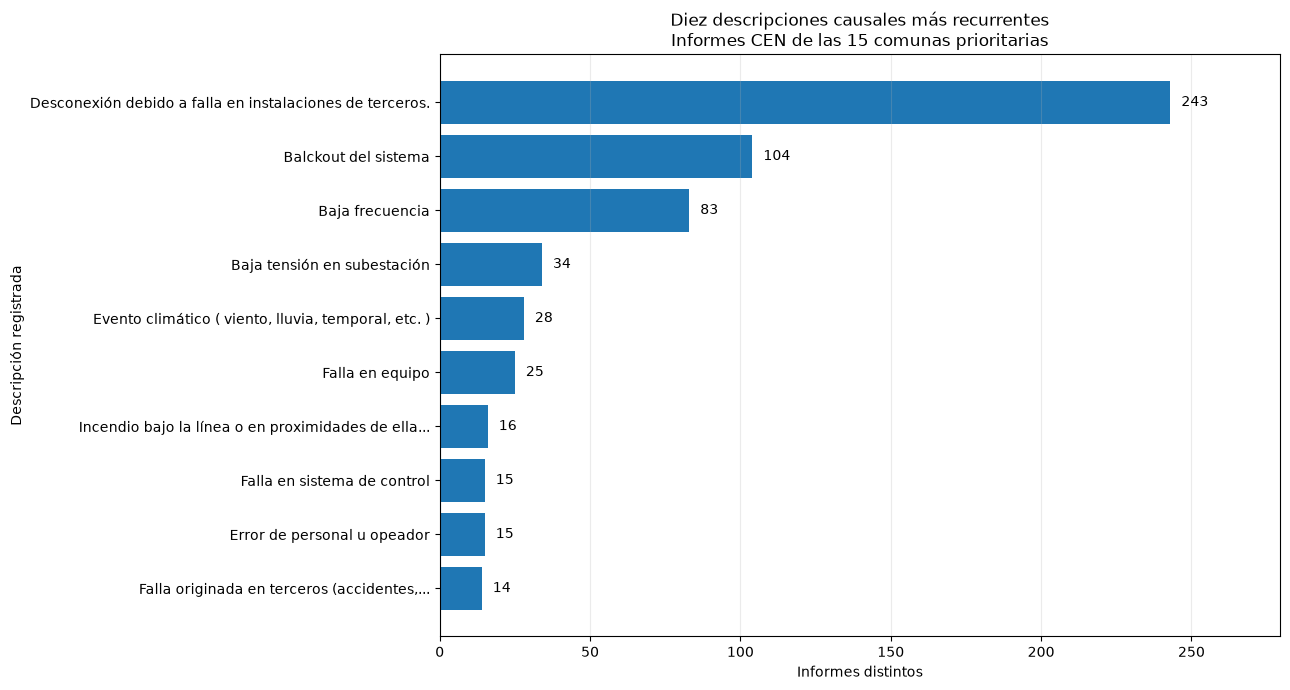

[OK] Guardado: /home/girosmedia/Magister/MCDI500_Programacion/Proyecto_MCDI500/F2/figuras/F2_613_Figura_01_Recurrencia_General.png


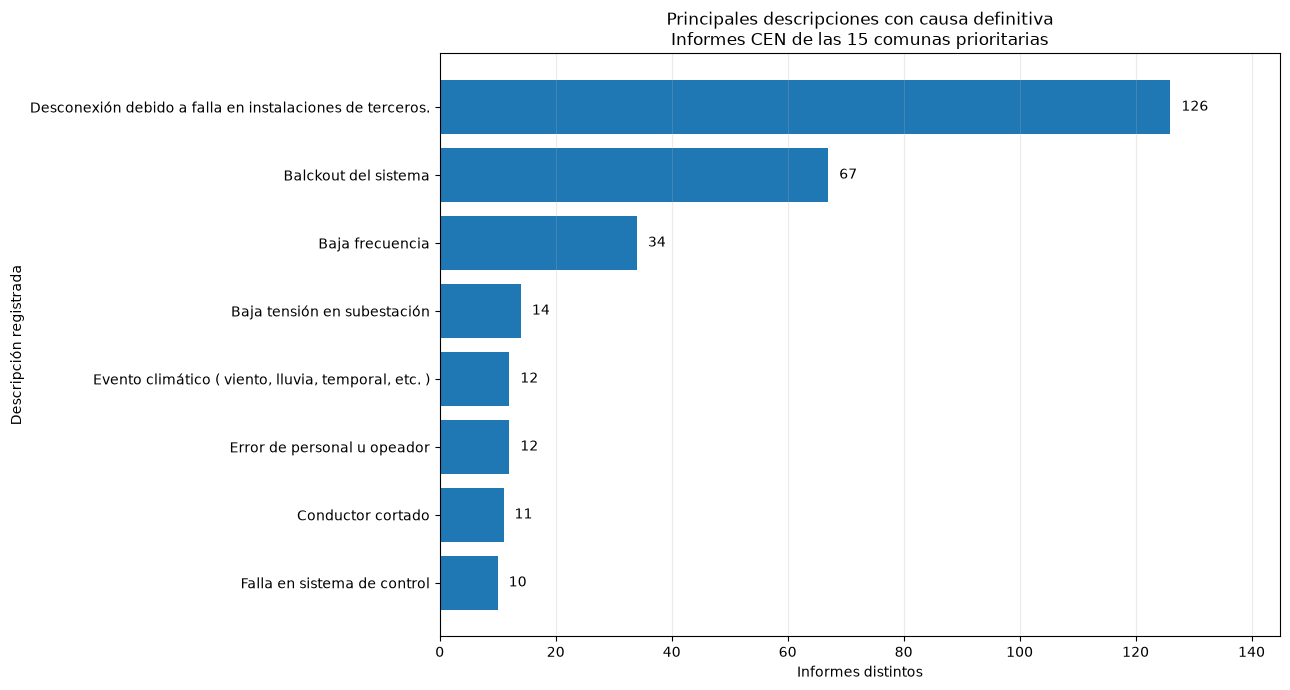

[OK] Guardado: /home/girosmedia/Magister/MCDI500_Programacion/Proyecto_MCDI500/F2/figuras/F2_613_Figura_02_Causas_Definitivas.png


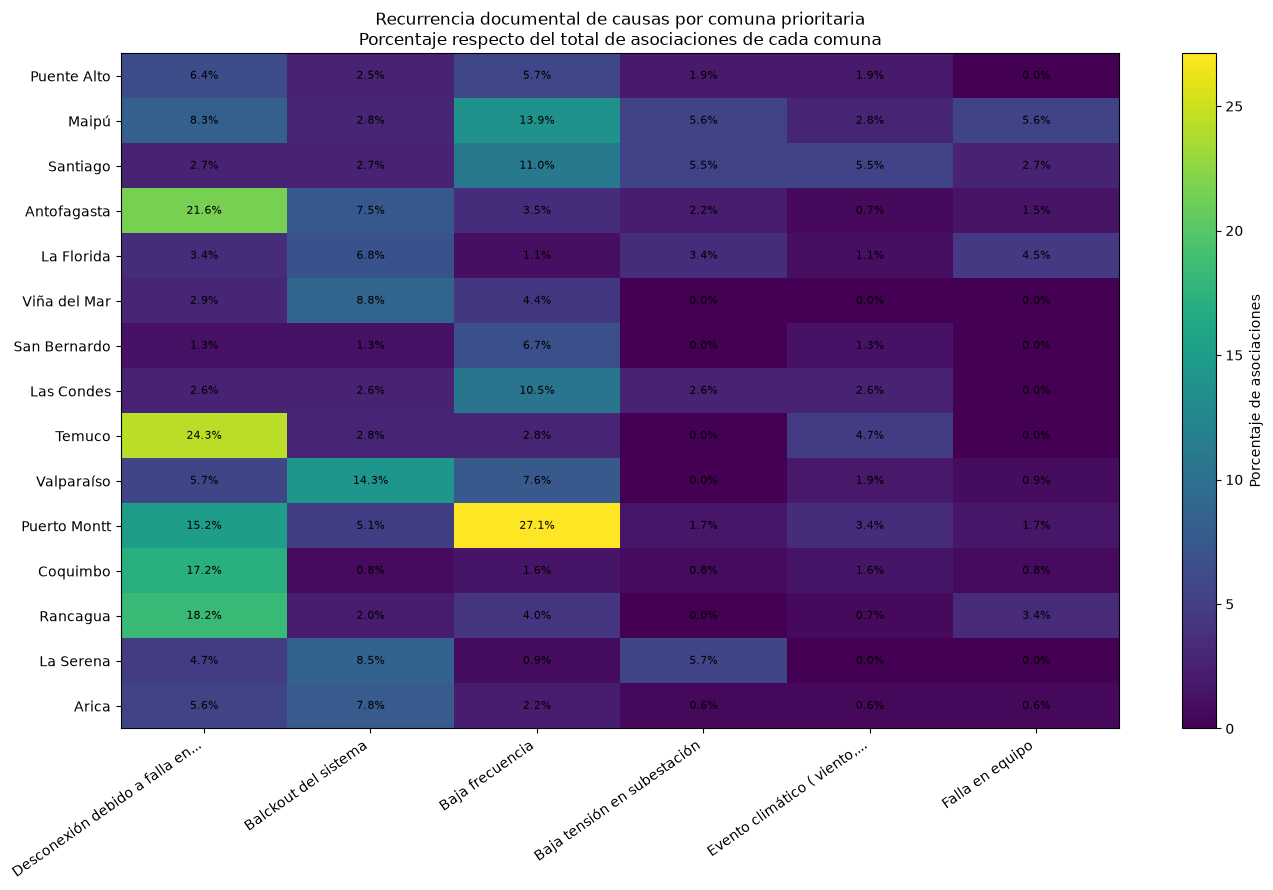

[OK] Guardado: /home/girosmedia/Magister/MCDI500_Programacion/Proyecto_MCDI500/F2/figuras/F2_613_Figura_03_Matriz_Recurrencia_Comunal.png


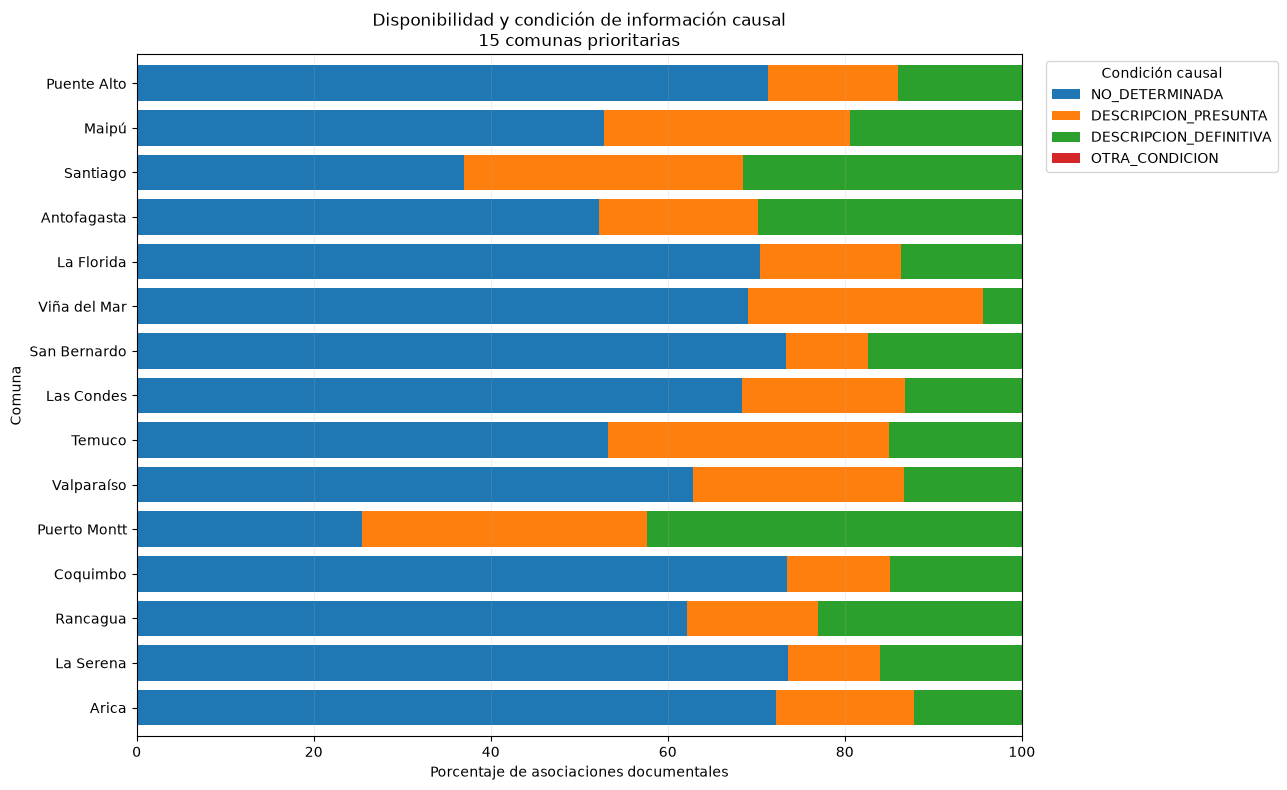

[OK] Guardado: /home/girosmedia/Magister/MCDI500_Programacion/Proyecto_MCDI500/F2/figuras/F2_613_Figura_04_Calidad_Causal_Comunal.png

VISUALIZACIÓN DE RECURRENCIA DOCUMENTAL FINALIZADA
Informes únicos: 1834
Asociaciones territoriales: 1915
Comunas analizadas: 15
Figuras generadas: 4

[OK] Ranking general de causas visualizado.
[OK] Ranking de causas definitivas visualizado.
[OK] Matriz de recurrencia comunal construida.
[OK] Calidad causal por comuna visualizada.
[OK] Integridad de los resultados verificada.


In [20]:
# ==========================================================
# FASE 2 - APARTADO 6.13.6
# VISUALIZACIÓN DE RECURRENCIA DOCUMENTAL POR COMUNA
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt
import textwrap

from pathlib import Path
from IPython.display import display


# ==========================================================
# 1. CONFIGURAR CARPETA DE SALIDA
# ==========================================================

carpeta_figuras = Path(RAIZ) / "F2" / "figuras"

carpeta_figuras.mkdir(
    parents=True,
    exist_ok=True
)


# ==========================================================
# 2. VERIFICAR CONJUNTOS DISPONIBLES
# ==========================================================

assert len(df_informes_causas) == 1834

assert len(df_recurrencia) == 1915

assert len(df_prioritarias) == 15

assert ranking_causas["informes_distintos"].sum() == 725


# ==========================================================
# 3. FUNCIÓN PARA GUARDAR FIGURAS
# ==========================================================

archivos_generados = []

def guardar_grafico(figura, nombre_archivo):

    ruta = carpeta_figuras / nombre_archivo

    figura.savefig(
        ruta,
        dpi=200,
        bbox_inches="tight"
    )

    archivos_generados.append(ruta)

    plt.show()

    plt.close(figura)

    print(f"[OK] Guardado: {ruta}")


# ==========================================================
# 4. FUNCIÓN PARA RANKINGS DE CAUSAS
# ==========================================================

def graficar_ranking(
    tabla,
    titulo,
    nombre_archivo,
    cantidad=10
):

    datos = tabla.head(cantidad).copy()

    datos = datos.sort_values(
        "informes_distintos",
        ascending=True
    )

    etiquetas = [
        textwrap.shorten(
            str(valor),
            width=58,
            placeholder="..."
        )
        for valor in datos["descripcion_causa"]
    ]

    valores = datos[
        "informes_distintos"
    ].astype(int).tolist()

    fig, ax = plt.subplots(
        figsize=(13, 7)
    )

    ax.barh(
        etiquetas,
        valores
    )

    ax.set_title(titulo)

    ax.set_xlabel("Informes distintos")

    ax.set_ylabel("Descripción registrada")

    ax.grid(
        axis="x",
        alpha=0.25
    )

    maximo = max(valores)

    ax.set_xlim(
        0,
        maximo * 1.15
    )

    for posicion, valor in enumerate(valores):

        ax.text(
            valor + maximo * 0.015,
            posicion,
            f"{valor:,}".replace(",", "."),
            va="center"
        )

    fig.tight_layout()

    guardar_grafico(
        fig,
        nombre_archivo
    )


# ==========================================================
# 5. FIGURA 1 - PRINCIPALES DESCRIPCIONES RECURRENTES
# ==========================================================

graficar_ranking(
    tabla=ranking_causas,
    titulo=(
        "Diez descripciones causales más recurrentes\n"
        "Informes CEN de las 15 comunas prioritarias"
    ),
    nombre_archivo="F2_613_Figura_01_Recurrencia_General.png",
    cantidad=10
)


# ==========================================================
# 6. FIGURA 2 - CAUSAS CLASIFICADAS COMO DEFINITIVAS
# ==========================================================

graficar_ranking(
    tabla=ranking_definitivas,
    titulo=(
        "Principales descripciones con causa definitiva\n"
        "Informes CEN de las 15 comunas prioritarias"
    ),
    nombre_archivo="F2_613_Figura_02_Causas_Definitivas.png",
    cantidad=8
)


# ==========================================================
# 7. PREPARAR MATRIZ DE RECURRENCIA TERRITORIAL
# ==========================================================

# Seleccionar las seis descripciones determinadas
# más frecuentes del conjunto prioritario.

causas_principales = (
    ranking_causas
    .head(6)["descripcion_causa"]
    .tolist()
)

# Conservar el orden demográfico de las 15 comunas.

orden_comunas = (
    df_prioritarias
    .sort_values("posicion_demografica")
    ["comuna_oficial"]
    .tolist()
)

# Construir matriz de participación porcentual.

matriz_recurrencia = (
    tabla_recurrencia_comunal
    .pivot(
        index="comuna_oficial",
        columns="descripcion_causa",
        values="pct_comunal"
    )
    .reindex(
        index=orden_comunas,
        columns=causas_principales
    )
    .fillna(0)
    .astype(float)
)

assert matriz_recurrencia.shape == (15, 6)


# ==========================================================
# 8. FIGURA 3 - MATRIZ DE RECURRENCIA POR COMUNA
# ==========================================================

fig, ax = plt.subplots(
    figsize=(14, 9)
)

imagen = ax.imshow(
    matriz_recurrencia.to_numpy(),
    aspect="auto"
)

# Etiquetas abreviadas para mejorar lectura.

etiquetas_causas = [
    textwrap.shorten(
        str(causa),
        width=32,
        placeholder="..."
    )
    for causa in causas_principales
]

ax.set_xticks(
    range(len(causas_principales))
)

ax.set_xticklabels(
    etiquetas_causas,
    rotation=35,
    ha="right"
)

ax.set_yticks(
    range(len(orden_comunas))
)

ax.set_yticklabels(orden_comunas)

ax.set_title(
    "Recurrencia documental de causas por comuna prioritaria\n"
    "Porcentaje respecto del total de asociaciones de cada comuna"
)

# Incorporar valores porcentuales.

for fila in range(
    len(matriz_recurrencia.index)
):

    for columna in range(
        len(matriz_recurrencia.columns)
    ):

        valor = matriz_recurrencia.iloc[
            fila,
            columna
        ]

        ax.text(
            columna,
            fila,
            f"{valor:.1f}%",
            ha="center",
            va="center",
            fontsize=8
        )

barra_color = fig.colorbar(
    imagen,
    ax=ax
)

barra_color.set_label(
    "Porcentaje de asociaciones"
)

fig.tight_layout()

guardar_grafico(
    fig,
    "F2_613_Figura_03_Matriz_Recurrencia_Comunal.png"
)


# ==========================================================
# 9. PREPARAR CLASIFICACIÓN DE INFORMACIÓN CAUSAL
# ==========================================================

df_calidad_causal = df_recurrencia[
    [
        "id_falla",
        "codigo_comuna",
        "comuna_oficial",
        "causa_no_determinada",
        "causa_clasificada_definitiva",
        "causa_clasificada_presunta"
    ]
].copy()

df_calidad_causal["situacion_causal"] = (
    "OTRA_CONDICION"
)

# Sin información causal determinada.

df_calidad_causal.loc[
    df_calidad_causal["causa_no_determinada"],
    "situacion_causal"
] = "NO_DETERMINADA"

# Descripción específica, clasificada como presunta.

df_calidad_causal.loc[
    (
        ~df_calidad_causal["causa_no_determinada"]
        & df_calidad_causal[
            "causa_clasificada_presunta"
        ]
    ),
    "situacion_causal"
] = "DESCRIPCION_PRESUNTA"

# Descripción específica, clasificada como definitiva.

df_calidad_causal.loc[
    (
        ~df_calidad_causal["causa_no_determinada"]
        & df_calidad_causal[
            "causa_clasificada_definitiva"
        ]
    ),
    "situacion_causal"
] = "DESCRIPCION_DEFINITIVA"


# ==========================================================
# 10. CALCULAR DISTRIBUCIÓN POR COMUNA
# ==========================================================

tabla_calidad_causal = pd.crosstab(
    df_calidad_causal["comuna_oficial"],
    df_calidad_causal["situacion_causal"]
)

categorias_calidad = [
    "NO_DETERMINADA",
    "DESCRIPCION_PRESUNTA",
    "DESCRIPCION_DEFINITIVA",
    "OTRA_CONDICION"
]

tabla_calidad_causal = (
    tabla_calidad_causal
    .reindex(
        index=orden_comunas,
        columns=categorias_calidad,
        fill_value=0
    )
)

porcentaje_calidad_causal = (
    tabla_calidad_causal
    .div(
        tabla_calidad_causal.sum(axis=1),
        axis=0
    )
    * 100
)

assert tabla_calidad_causal.to_numpy().sum() == 1915


# ==========================================================
# 11. FIGURA 4 - DISPONIBILIDAD DE CAUSAS POR COMUNA
# ==========================================================

fig, ax = plt.subplots(
    figsize=(13, 8)
)

porcentaje_calidad_causal.plot(
    kind="barh",
    stacked=True,
    ax=ax,
    width=0.8
)

ax.set_title(
    "Disponibilidad y condición de información causal\n"
    "15 comunas prioritarias"
)

ax.set_xlabel(
    "Porcentaje de asociaciones documentales"
)

ax.set_ylabel("Comuna")

ax.set_xlim(0, 100)

ax.invert_yaxis()

ax.legend(
    title="Condición causal",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(
    axis="x",
    alpha=0.2
)

fig.tight_layout()

guardar_grafico(
    fig,
    "F2_613_Figura_04_Calidad_Causal_Comunal.png"
)


# ==========================================================
# 12. VALIDACIONES FINALES
# ==========================================================

assert ranking_definitivas[
    "informes_distintos"
].sum() == 385

assert (
    tabla_calidad_causal.sum(axis=1)
    .sum()
    == len(df_recurrencia)
)

assert (
    porcentaje_calidad_causal.sum(axis=1)
    .round(6)
    .eq(100)
    .all()
)

assert len(archivos_generados) == 4

assert all(
    ruta.exists()
    for ruta in archivos_generados
)


# ==========================================================
# 13. RESUMEN FINAL
# ==========================================================

print("\n" + "=" * 65)
print("VISUALIZACIÓN DE RECURRENCIA DOCUMENTAL FINALIZADA")
print("=" * 65)

print("Informes únicos:", len(df_informes_causas))

print("Asociaciones territoriales:", len(df_recurrencia))

print("Comunas analizadas:", len(orden_comunas))

print("Figuras generadas:", len(archivos_generados))

print("\n[OK] Ranking general de causas visualizado.")

print("[OK] Ranking de causas definitivas visualizado.")

print("[OK] Matriz de recurrencia comunal construida.")

print("[OK] Calidad causal por comuna visualizada.")

print("[OK] Integridad de los resultados verificada.")

**Resultados e interpretación de las visualizaciones de recurrencia documental**

Las visualizaciones permitieron identificar las descripciones causales más recurrentes en los informes del Coordinador Eléctrico Nacional (CEN) y comparar su distribución entre las 15 comunas prioritarias.

El procesamiento consideró 1.834 informes distintos y 1.915 asociaciones territoriales, distinguiendo las descripciones específicas de aquellas que no permiten determinar una causa.

**Figura 1. Descripciones causales más recurrentes**

El ranking general evidencia que la descripción más frecuente corresponde a desconexiones relacionadas con fallas en instalaciones de terceros, con 243 informes distintos.

Le siguen las referencias a blackout del sistema, con 104 informes, y las condiciones de baja frecuencia, con 83 registros.

Otras descripciones relevantes son baja tensión en subestaciones, con 34 informes; eventos climáticos, con 28; y fallas en equipos, con 25.

Estos resultados identifican las principales categorías documentales registradas, pero no representan necesariamente mecanismos físicos de falla equivalentes.

**Figura 2. Principales descripciones con causa clasificada como definitiva**

Al considerar exclusivamente los informes con descripciones específicas y condición causal definitiva, se mantiene el predominio de las desconexiones asociadas con instalaciones de terceros, con 126 documentos.

En segundo lugar aparecen las referencias a blackout del sistema, con 67 informes, seguidas por baja frecuencia, con 34.

La comparación evidencia que no todas las descripciones recurrentes presentan el mismo grado de determinación causal.

Este aspecto es relevante porque permite diferenciar las observaciones documentales de aquellas clasificadas administrativamente como definitivas, sin asumir que dicha clasificación constituye una verificación técnica independiente.

**Figura 3. Matriz de recurrencia documental por comuna prioritaria**

La matriz permite identificar diferencias territoriales en la participación relativa de las seis descripciones causales más frecuentes.

Los resultados destacados son los siguientes:

| Comuna | Descripción destacada | Participación comunal |
|---|---|---:|
| Puerto Montt | Baja frecuencia | 27,12 % |
| Temuco | Desconexión por falla en instalaciones de terceros | 24,30 % |
| Antofagasta | Desconexión por falla en instalaciones de terceros | 21,57 % |
| Rancagua | Desconexión por falla en instalaciones de terceros | 18,24 % |
| Coquimbo | Desconexión por falla en instalaciones de terceros | 17,19 % |
| Valparaíso | Blackout del sistema | 14,29 % |
| Maipú | Baja frecuencia | 13,89 % |

*Fuente: Elaboración propia mediante Python, utilizando asociaciones territoriales CEN–INE.*

La comparación evidencia que los perfiles documentales son diferentes entre comunas.

En Puerto Montt destaca la baja frecuencia, mientras que Antofagasta, Temuco, Rancagua y Coquimbo presentan una mayor participación relativa de desconexiones asociadas con instalaciones de terceros.

En Valparaíso sobresalen las referencias a blackout del sistema.

Estos resultados permiten identificar categorías de interés para profundizar el análisis operacional en cada territorio.

Sin embargo, los porcentajes corresponden a la proporción de asociaciones documentales de cada comuna y no a tasas de fallas físicas, habitantes afectados o clientes interrumpidos.

Asimismo, la matriz representa solamente las seis descripciones seleccionadas, por lo que sus porcentajes no deben interpretarse como una distribución exhaustiva de todas las causas.

**Figura 4. Disponibilidad y condición de información causal por comuna**

La cuarta visualización muestra diferencias en la disponibilidad de información causal entre las comunas prioritarias.

En varias comunas, entre ellas Puente Alto, San Bernardo, Coquimbo, La Serena y Arica, predomina la categoría de información causal no determinada.

En contraste, Puerto Montt presenta una mayor participación relativa de descripciones clasificadas como definitivas y una menor proporción de registros sin causa determinada.

Estas diferencias reflejan la composición documental de los informes disponibles y no necesariamente una mayor capacidad técnica de diagnóstico de las instalaciones de una comuna.

A escala del conjunto prioritario, 1.109 de los 1.834 informes carecen de causa determinada, equivalentes al 60,47 %.

Esta condición representa una limitación significativa para analizar mecanismos causales y debe considerarse al interpretar las recurrencias identificadas.

**Interpretación integrada y vinculación con el objetivo del proyecto**

El análisis permite identificar tres resultados relevantes.

En primer lugar, las desconexiones asociadas con instalaciones de terceros constituyen la descripción causal específica más recurrente del conjunto prioritario.

En segundo lugar, la distribución de estas descripciones varía entre comunas, lo que permite establecer perfiles operacionales documentales diferenciados.

En tercer lugar, la elevada proporción de causas no determinadas limita la posibilidad de atribuir mecanismos físicos específicos a una parte importante de los informes.

En consecuencia, el procesamiento permite caracterizar las fallas documentadas según su recurrencia, condición causal y distribución territorial, contribuyendo al objetivo de analizar el impacto operacional documentado del Sistema Eléctrico Nacional sobre las comunas prioritarias.

No obstante, los resultados no permiten establecer directamente la severidad de las interrupciones, la cantidad de clientes afectados, la energía no suministrada ni la frecuencia física de fallas independientes.

La información obtenida constituye una base técnica reproducible para profundizar el análisis de acontecimientos relevantes y desarrollar estudios posteriores de confiabilidad y continuidad operacional del suministro eléctrico.

## 6.14. Validación técnica integral del procesamiento

### 6.14.1. Fundamentación técnica

El procesamiento de datos desarrollado durante la Fase 2 permitió construir un conjunto de información integrado para analizar el impacto operacional documentado de las fallas del Sistema Eléctrico Nacional (SEN) en las 15 comunas prioritarias seleccionadas mediante el Censo 2024.

El trabajo consideró la consolidación y exploración de informes del Coordinador Eléctrico Nacional (CEN), el diagnóstico de calidad, la normalización territorial, la integración con el maestro comunal del Instituto Nacional de Estadísticas (INE), el preprocesamiento operacional y temporal, y la caracterización de las fallas documentadas.

Para garantizar que estos procedimientos produzcan resultados consistentes, resulta necesario implementar pruebas técnicas que permitan evaluar el funcionamiento de las funciones desarrolladas y la integridad de los conjuntos procesados.

La validación constituye un requisito fundamental para asegurar la reproducibilidad, trazabilidad y confiabilidad técnica del proyecto.

### 6.14.2. Estrategia de validación

Se aplicarán tres grupos de pruebas complementarias:

| Grupo | Tipo de prueba | Objetivo |
|---|---|---|
| 1 | Casos normales | Verificar que las funciones procesen correctamente datos válidos y produzcan los resultados esperados. |
| 2 | Casos límite y excepcionales | Comprobar el tratamiento de valores faltantes, fechas inválidas, regiones múltiples y duplicaciones. |
| 3 | Integridad de conjuntos procesados | Verificar la conservación de registros, unicidad de identificadores, coherencia de asociaciones y consistencia de resultados. |

Las pruebas funcionales utilizarán casos sintéticos con resultados esperados conocidos, evitando modificar los registros originales.

Las pruebas de integridad se aplicarán sobre los conjuntos efectivamente construidos durante el procesamiento.

### 6.14.3. Criterios de validación

El procedimiento verificará las siguientes condiciones:

**Normalización territorial**

Se comprobará que las funciones de normalización identifiquen correctamente denominaciones comunales y regionales, incluyendo caracteres acentuados y registros multirregionales.

**Clasificación operacional**

Se verificará que las categorías administrativas y de consumo sean reconocidas correctamente y que los valores faltantes o no previstos reciban un tratamiento explícito.

**Conversión temporal**

Se comprobará el reconocimiento de formatos de fecha válidos, el tratamiento de fechas inexistentes y la identificación de intervalos cronológicos negativos.

**Integridad documental**

Se verificará la conservación de los 18.019 informes originales, la unicidad de sus identificadores y la correspondencia entre los conjuntos derivados.

**Integridad territorial**

Se comprobará la conservación de las 23.284 asociaciones territoriales, la correcta homologación comunal y la ausencia de asociaciones duplicadas.

**Integridad del conjunto prioritario**

Se verificará que los resultados conserven las 15 comunas prioritarias, los 1.834 informes distintos y las 1.915 asociaciones territoriales identificadas.

**Consistencia de la caracterización causal**

Se comprobará la correspondencia entre informes con causas determinadas, causas no determinadas y las clasificaciones documentales utilizadas en el análisis de recurrencia.

### 6.14.4. Criterio de aceptación

Cada prueba se clasificará como:

- `APROBADA`: el resultado obtenido coincide con el comportamiento esperado.
- `NO_APROBADA`: se identifica una diferencia entre el resultado obtenido y el resultado esperado.

El procedimiento generará una tabla consolidada con la identificación de cada prueba, su grupo, el resultado y una observación técnica.

La validación integral se considerará satisfactoria cuando todas las pruebas definidas sean aprobadas.

Los resultados permitirán respaldar la consistencia del procesamiento y establecer evidencia verificable para la reproducibilidad del proyecto.

Debe considerarse que la aprobación de estas pruebas demuestra la consistencia técnica de las funciones y transformaciones evaluadas, pero no constituye una verificación independiente de la exactitud de todos los antecedentes publicados por las fuentes originales.

In [21]:
# ==========================================================
# FASE 2 - APARTADO 6.14
# VALIDACIÓN TÉCNICA INTEGRAL DEL PROCESAMIENTO
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
import numpy as np

from IPython.display import display


# ==========================================================
# 1. CONFIGURAR REGISTRO DE PRUEBAS
# ==========================================================

resultados_pruebas = []


def ejecutar_prueba(grupo, nombre, funcion, observacion):
    """
    Ejecuta una prueba de validación.

    Registra:
    - Grupo de prueba.
    - Nombre.
    - Estado.
    - Observación.
    - Error, si corresponde.

    No modifica los conjuntos originales.
    """

    try:

        resultado = funcion()

        aprobada = bool(resultado)

        estado = (
            "APROBADA"
            if aprobada
            else "NO_APROBADA"
        )

        detalle = (
            observacion
            if aprobada
            else "El resultado no coincide con lo esperado."
        )

    except Exception as error:

        estado = "NO_APROBADA"

        detalle = (
            f"{type(error).__name__}: {error}"
        )

    resultados_pruebas.append({
        "grupo": grupo,
        "prueba": nombre,
        "estado": estado,
        "observacion": detalle
    })


# ==========================================================
# 2. PRUEBAS DE NORMALIZACIÓN TERRITORIAL
# ==========================================================

ejecutar_prueba(
    "NORMALIZACION",
    "Normalización de caracteres acentuados",
    lambda: (
        normalizar_comuna("Viña del Mar")
        == "VINA DEL MAR"
    ),
    "La normalización reconoce caracteres acentuados."
)


ejecutar_prueba(
    "NORMALIZACION",
    "Coincidencia de región individual",
    lambda: verificar_region_multiple(
        "Ñuble",
        "Ñuble"
    ),
    "Se reconoce una región individual válida."
)


ejecutar_prueba(
    "NORMALIZACION",
    "Reconocimiento de regiones múltiples",
    lambda: verificar_region_multiple(
        "Maule|Ñuble",
        "Ñuble"
    ),
    "Se identifica la región oficial dentro de una lista."
)


ejecutar_prueba(
    "NORMALIZACION",
    "Rechazo de región no coincidente",
    lambda: not verificar_region_multiple(
        "Maule|Biobío",
        "Ñuble"
    ),
    "No se asigna una coincidencia regional inexistente."
)


ejecutar_prueba(
    "NORMALIZACION",
    "Tratamiento de región faltante",
    lambda: not verificar_region_multiple(
        pd.NA,
        "Ñuble"
    ),
    "Los valores nulos no generan coincidencias falsas."
)


# ==========================================================
# 3. PRUEBAS DE AUDITORÍA GEOGRÁFICA
# ==========================================================

ejecutar_prueba(
    "AUDITORIA_GEOGRAFICA",
    "Coincidencia regional con denominaciones alternativas",
    lambda: auditar_asociacion(
        "Metropolitana",
        "Metropolitana de Santiago"
    ) == "COINCIDE",
    "Se reconoce una denominación regional equivalente."
)


ejecutar_prueba(
    "AUDITORIA_GEOGRAFICA",
    "Detección de diferencia regional",
    lambda: auditar_asociacion(
        "Valparaíso",
        "Coquimbo"
    ) == "REVISAR_DIFERENCIA",
    "Se identifica una incompatibilidad regional."
)


ejecutar_prueba(
    "AUDITORIA_GEOGRAFICA",
    "Identificación de zona faltante",
    lambda: auditar_asociacion(
        pd.NA,
        "Valparaíso"
    ) == "SIN_ZONA_CEN",
    "Se clasifica correctamente la ausencia de zona."
)


ejecutar_prueba(
    "AUDITORIA_GEOGRAFICA",
    "Detección de denominación no reconocida",
    lambda: auditar_asociacion(
        "REGION_INEXISTENTE",
        "Valparaíso"
    ) == "REVISAR_DENOMINACION",
    "Se identifica una denominación regional desconocida."
)


# ==========================================================
# 4. PRUEBAS DE CLASIFICACIÓN OPERACIONAL
# ==========================================================

ejecutar_prueba(
    "CLASIFICACION_OPERACIONAL",
    "Reconocimiento de estado válido",
    lambda: clasificar_categoria(
        "FINALIZADO",
        estados_validos
    ) == "FINALIZADO",
    "Se conserva una categoría administrativa válida."
)


ejecutar_prueba(
    "CLASIFICACION_OPERACIONAL",
    "Reconocimiento de consumo válido",
    lambda: clasificar_categoria(
        "CONSUMO_REGULADO",
        consumos_validos
    ) == "CONSUMO_REGULADO",
    "Se conserva una clasificación de consumo reconocida."
)


ejecutar_prueba(
    "CLASIFICACION_OPERACIONAL",
    "Tratamiento de valor nulo",
    lambda: clasificar_categoria(
        pd.NA,
        estados_validos
    ) == "SIN_DATO",
    "Los valores nulos se clasifican explícitamente."
)


ejecutar_prueba(
    "CLASIFICACION_OPERACIONAL",
    "Tratamiento de cadena vacía",
    lambda: clasificar_categoria(
        " ",
        estados_validos
    ) == "SIN_DATO",
    "Las cadenas vacías se identifican como datos faltantes."
)


ejecutar_prueba(
    "CLASIFICACION_OPERACIONAL",
    "Detección de categoría desconocida",
    lambda: clasificar_categoria(
        "VALOR_NO_RECONOCIDO",
        consumos_validos
    ) == "OTRO_VALOR",
    "Las categorías no previstas se identifican para revisión."
)


# ==========================================================
# 5. PRUEBAS DE CONVERSIÓN TEMPORAL
# ==========================================================

ejecutar_prueba(
    "CONVERSION_TEMPORAL",
    "Conversión de fecha ISO",
    lambda: convertir_fecha_cen(
        "2025-02-25 15:16:00"
    ) == pd.Timestamp(
        "2025-02-25 15:16:00"
    ),
    "Se reconoce una fecha con formato ISO."
)


ejecutar_prueba(
    "CONVERSION_TEMPORAL",
    "Conversión de fecha día/mes/año",
    lambda: convertir_fecha_cen(
        "25/02/2025 15:16:00"
    ) == pd.Timestamp(
        "2025-02-25 15:16:00"
    ),
    "Se reconoce una fecha con formato día/mes/año."
)


ejecutar_prueba(
    "CONVERSION_TEMPORAL",
    "Identificación de fecha inexistente",
    lambda: pd.isna(
        convertir_fecha_cen(
            "2025-02-30"
        )
    ),
    "Las fechas inexistentes se clasifican como inválidas."
)


ejecutar_prueba(
    "CONVERSION_TEMPORAL",
    "Tratamiento de fecha faltante",
    lambda: pd.isna(
        convertir_fecha_cen(
            pd.NA
        )
    ),
    "Las fechas faltantes se conservan como NaT."
)


# ==========================================================
# 6. PRUEBA DE INTERVALO CRONOLÓGICO NEGATIVO
# ==========================================================

def comprobar_intervalo_negativo():

    inicio = convertir_fecha_cen(
        "2025-02-25 18:00:00"
    )

    termino = convertir_fecha_cen(
        "2025-02-25 17:00:00"
    )

    intervalo = (
        termino - inicio
    ).total_seconds() / 3600

    return intervalo == -1.0


ejecutar_prueba(
    "CONVERSION_TEMPORAL",
    "Detección de intervalo negativo",
    comprobar_intervalo_negativo,
    "Se reconoce un término anterior a la perturbación."
)


# ==========================================================
# 7. PRUEBA DE EXCEPCIÓN POR DUPLICADOS
# ==========================================================

def comprobar_rechazo_duplicados():
    """
    Verifica que una integración many_to_one
    rechace claves duplicadas en la tabla derecha.
    """

    tabla_izquierda = pd.DataFrame({
        "id_falla": [1, 2]
    })

    tabla_derecha = pd.DataFrame({
        "id_falla": [1, 1, 2],
        "categoria": ["A", "B", "C"]
    })

    try:

        tabla_izquierda.merge(
            tabla_derecha,
            on="id_falla",
            how="left",
            validate="many_to_one"
        )

    except pd.errors.MergeError:

        return True

    return False


ejecutar_prueba(
    "CONTROL_EXCEPCIONES",
    "Rechazo de integración con claves duplicadas",
    comprobar_rechazo_duplicados,
    "Pandas impide una integración many_to_one inconsistente."
)


# ==========================================================
# 8. PRUEBAS DE INTEGRIDAD DOCUMENTAL
# ==========================================================

ejecutar_prueba(
    "INTEGRIDAD_DOCUMENTAL",
    "Conservación de informes originales",
    lambda: len(df_f2) == 18019,
    "Se conservaron los 18.019 informes del CEN."
)


ejecutar_prueba(
    "INTEGRIDAD_DOCUMENTAL",
    "Unicidad de informes originales",
    lambda: (
        df_f2["id_falla"].is_unique
        and df_f2["id_falla"].notna().all()
    ),
    "Los informes poseen identificadores únicos y completos."
)


ejecutar_prueba(
    "INTEGRIDAD_DOCUMENTAL",
    "Conservación de base temporal",
    lambda: len(df_temporal_cen) == len(df_f2),
    "La transformación temporal no eliminó informes."
)


ejecutar_prueba(
    "INTEGRIDAD_DOCUMENTAL",
    "Conservación de columnas originales",
    lambda: df_temporal_cen[
        df_f2.columns
    ].equals(df_f2),
    "Las variables originales permanecen intactas."
)


# ==========================================================
# 9. PRUEBAS DE INTEGRIDAD TERRITORIAL
# ==========================================================

ejecutar_prueba(
    "INTEGRIDAD_TERRITORIAL",
    "Conservación de asociaciones",
    lambda: len(df_auditoria) == 23284,
    "Se conservaron las 23.284 asociaciones."
)


ejecutar_prueba(
    "INTEGRIDAD_TERRITORIAL",
    "Ausencia de asociaciones duplicadas",
    lambda: not df_auditoria.duplicated(
        subset=[
            "id_falla",
            "codigo_comuna"
        ]
    ).any(),
    "No existen relaciones informe-comuna duplicadas."
)


ejecutar_prueba(
    "INTEGRIDAD_TERRITORIAL",
    "Completitud de homologación comunal",
    lambda: (
        df_comunas_ine_final[
            "codigo_comuna"
        ].notna().all()
    ),
    "Todas las asociaciones tienen código comunal oficial."
)


ejecutar_prueba(
    "INTEGRIDAD_TERRITORIAL",
    "Consistencia geográfica",
    lambda: (
        df_auditoria[
            "resultado_auditoria"
        ].eq("COINCIDE").all()
    ),
    "Todas las asociaciones presentan coincidencia regional."
)


# ==========================================================
# 10. PRUEBAS DEL CONJUNTO PRIORITARIO
# ==========================================================

ejecutar_prueba(
    "CONJUNTO_PRIORITARIO",
    "Cantidad de comunas prioritarias",
    lambda: len(df_prioritarias) == 15,
    "La selección contiene 15 comunas."
)


ejecutar_prueba(
    "CONJUNTO_PRIORITARIO",
    "Unicidad de códigos comunales",
    lambda: (
        df_prioritarias[
            "codigo_comuna"
        ].is_unique
    ),
    "No existen comunas prioritarias duplicadas."
)


ejecutar_prueba(
    "CONJUNTO_PRIORITARIO",
    "Conservación de informes prioritarios",
    lambda: (
        df_temporal_prioritarias[
            "id_falla"
        ].nunique() == 1834
    ),
    "Se identificaron 1.834 informes distintos."
)


ejecutar_prueba(
    "CONJUNTO_PRIORITARIO",
    "Conservación de asociaciones prioritarias",
    lambda: len(df_temporal_asociaciones) == 1915,
    "Se conservaron 1.915 asociaciones prioritarias."
)


ejecutar_prueba(
    "CONJUNTO_PRIORITARIO",
    "Consistencia del conjunto cruzado",
    lambda: (
        len(df_cruce_fallas_comunas)
        == len(df_temporal_asociaciones)
    ),
    "La integración técnica conserva las asociaciones."
)


# ==========================================================
# 11. PRUEBAS DE CALIDAD TEMPORAL
# ==========================================================

ejecutar_prueba(
    "CALIDAD_TEMPORAL",
    "Validez de fechas de perturbación",
    lambda: (
        df_temporal_cen[
            "fecha_perturbacion_dt"
        ].notna().sum() == 18019
    ),
    "Se reconocieron las fechas de perturbación originales."
)


ejecutar_prueba(
    "CALIDAD_TEMPORAL",
    "Identificación de fechas de término faltantes",
    lambda: (
        df_temporal_cen[
            "validacion_temporal"
        ].eq("SIN_FECHA_TERMINO").sum() == 7214
    ),
    "Se identificaron 7.214 informes sin fecha de término."
)


ejecutar_prueba(
    "CALIDAD_TEMPORAL",
    "Ausencia de intervalos negativos válidos",
    lambda: (
        df_temporal_cen[
            "intervalo_documental_horas"
        ].dropna().ge(0).all()
    ),
    "Los intervalos utilizados no presentan valores negativos."
)


# ==========================================================
# 12. PRUEBAS DE CONSISTENCIA CAUSAL
# ==========================================================

ejecutar_prueba(
    "CONSISTENCIA_CAUSAL",
    "Conservación de informes analizados",
    lambda: len(df_informes_causas) == 1834,
    "El análisis causal conserva los informes únicos."
)


ejecutar_prueba(
    "CONSISTENCIA_CAUSAL",
    "Identificación de causas no determinadas",
    lambda: (
        df_informes_causas[
            "causa_no_determinada"
        ].sum() == 1109
    ),
    "Se identificaron 1.109 informes sin causa determinada."
)


ejecutar_prueba(
    "CONSISTENCIA_CAUSAL",
    "Conservación de informes con descripción causal",
    lambda: (
        ranking_causas[
            "informes_distintos"
        ].sum() == 725
    ),
    "Se conservaron los 725 informes con descripción específica."
)


ejecutar_prueba(
    "CONSISTENCIA_CAUSAL",
    "Coherencia de causas definitivas",
    lambda: (
        ranking_definitivas[
            "informes_distintos"
        ].sum() == 385
    ),
    "Se identificaron 385 informes con descripción definitiva."
)


# ==========================================================
# 13. CONSTRUIR TABLA GENERAL DE PRUEBAS
# ==========================================================

df_resultados_pruebas = pd.DataFrame(
    resultados_pruebas
)

df_resultados_pruebas.index = (
    df_resultados_pruebas.index + 1
)

df_resultados_pruebas.index.name = "N°"


# ==========================================================
# 14. CALCULAR RESUMEN
# ==========================================================

total_pruebas = len(df_resultados_pruebas)

pruebas_aprobadas = int(
    df_resultados_pruebas[
        "estado"
    ].eq("APROBADA").sum()
)

pruebas_no_aprobadas = (
    total_pruebas - pruebas_aprobadas
)

porcentaje_aprobacion = (
    pruebas_aprobadas / total_pruebas * 100
)


# ==========================================================
# 15. PRESENTAR RESULTADOS GENERALES
# ==========================================================

print("=" * 70)
print("VALIDACIÓN TÉCNICA INTEGRAL - FASE 2")
print("=" * 70)

print("\nRESUMEN DE VALIDACIÓN")

print("Pruebas ejecutadas:", total_pruebas)

print("Pruebas aprobadas:", pruebas_aprobadas)

print("Pruebas no aprobadas:", pruebas_no_aprobadas)

print(
    "Porcentaje de aprobación:",
    f"{porcentaje_aprobacion:.2f}%"
)


# ==========================================================
# 16. MOSTRAR RESULTADOS DETALLADOS
# ==========================================================

print("\nRESULTADOS DE LAS PRUEBAS")

display(
    df_resultados_pruebas
)


# ==========================================================
# 17. MOSTRAR RESUMEN POR GRUPO
# ==========================================================

resumen_grupos = pd.crosstab(
    df_resultados_pruebas["grupo"],
    df_resultados_pruebas["estado"]
)

print("\nRESUMEN DE PRUEBAS POR GRUPO")

display(resumen_grupos)


# ==========================================================
# 18. IDENTIFICAR PRUEBAS NO APROBADAS
# ==========================================================

if pruebas_no_aprobadas > 0:

    print("\nPRUEBAS QUE REQUIEREN REVISIÓN")

    display(
        df_resultados_pruebas.loc[
            df_resultados_pruebas[
                "estado"
            ].eq("NO_APROBADA")
        ]
    )

else:

    print(
        "\n[OK] Todas las pruebas fueron aprobadas."
    )


# ==========================================================
# 19. CRITERIO DE ACEPTACIÓN FINAL
# ==========================================================

if pruebas_no_aprobadas > 0:

    raise AssertionError(
        f"La validación identificó "
        f"{pruebas_no_aprobadas} prueba(s) no aprobada(s). "
        "Revisar los resultados antes de continuar."
    )


print("\n" + "=" * 70)
print("VALIDACIÓN TÉCNICA INTEGRAL FINALIZADA")
print("=" * 70)

print("[OK] Funciones de normalización verificadas.")

print("[OK] Clasificaciones operacionales verificadas.")

print("[OK] Conversiones temporales evaluadas.")

print("[OK] Casos excepcionales comprobados.")

print("[OK] Integridad documental confirmada.")

print("[OK] Integridad territorial confirmada.")

print("[OK] Conjuntos prioritarios verificados.")

print("[OK] Caracterización causal validada.")

VALIDACIÓN TÉCNICA INTEGRAL - FASE 2

RESUMEN DE VALIDACIÓN
Pruebas ejecutadas: 40
Pruebas aprobadas: 40
Pruebas no aprobadas: 0
Porcentaje de aprobación: 100.00%

RESULTADOS DE LAS PRUEBAS


,grupo,prueba,estado,observacion
N°,,,,
1,NORMALIZACION,Normalización de caracteres acentuados,APROBADA,La normalización reconoce caracteres acentuados.
2,NORMALIZACION,Coincidencia de región individual,APROBADA,Se reconoce una región individual válida.
3,NORMALIZACION,Reconocimiento de regiones múltiples,APROBADA,Se identifica la región oficial dentro de una ...
4,NORMALIZACION,Rechazo de región no coincidente,APROBADA,No se asigna una coincidencia regional inexist...
5,NORMALIZACION,Tratamiento de región faltante,APROBADA,Los valores nulos no generan coincidencias fal...
6,AUDITORIA_GEOGRAFICA,Coincidencia regional con denominaciones alter...,APROBADA,Se reconoce una denominación regional equivale...
7,AUDITORIA_GEOGRAFICA,Detección de diferencia regional,APROBADA,Se identifica una incompatibilidad regional.
8,AUDITORIA_GEOGRAFICA,Identificación de zona faltante,APROBADA,Se clasifica correctamente la ausencia de zona.
9,AUDITORIA_GEOGRAFICA,Detección de denominación no reconocida,APROBADA,Se identifica una denominación regional descon...



RESUMEN DE PRUEBAS POR GRUPO


estado,APROBADA
grupo,
AUDITORIA_GEOGRAFICA,4
CALIDAD_TEMPORAL,3
CLASIFICACION_OPERACIONAL,5
CONJUNTO_PRIORITARIO,5
CONSISTENCIA_CAUSAL,4
CONTROL_EXCEPCIONES,1
CONVERSION_TEMPORAL,5
INTEGRIDAD_DOCUMENTAL,4
INTEGRIDAD_TERRITORIAL,4



[OK] Todas las pruebas fueron aprobadas.

VALIDACIÓN TÉCNICA INTEGRAL FINALIZADA
[OK] Funciones de normalización verificadas.
[OK] Clasificaciones operacionales verificadas.
[OK] Conversiones temporales evaluadas.
[OK] Casos excepcionales comprobados.
[OK] Integridad documental confirmada.
[OK] Integridad territorial confirmada.
[OK] Conjuntos prioritarios verificados.
[OK] Caracterización causal validada.


### 6.14.5. Resultados e interpretación de la validación técnica integral

La validación técnica integral permitió comprobar el comportamiento de las funciones y transformaciones implementadas durante la Fase 2 del proyecto, considerando casos normales, condiciones límite, situaciones excepcionales y verificaciones de integridad de los conjuntos procesados.

Se ejecutaron **40 pruebas distribuidas en diez grupos de validación**, obteniéndose los siguientes resultados.

| Indicador | Resultado |
|---|---:|
| Pruebas técnicas ejecutadas | 40 |
| Pruebas aprobadas | 40 |
| Pruebas no aprobadas | 0 |
| **Porcentaje de aprobación** | **100,00 %** |

*Fuente: Elaboración propia mediante pruebas automatizadas implementadas en Python.*

**Resultados por grupo de validación**

| Grupo de validación | Pruebas aprobadas |
|---|---:|
| Normalización territorial | 5 |
| Auditoría geográfica | 4 |
| Clasificación operacional | 5 |
| Conversión temporal | 5 |
| Control de excepciones | 1 |
| Integridad documental | 4 |
| Integridad territorial | 4 |
| Conjunto prioritario | 5 |
| Calidad temporal | 3 |
| Consistencia causal | 4 |
| **Total** | **40** |

Los resultados confirman que las funciones evaluadas respondieron correctamente a las condiciones definidas.

En particular, las pruebas permitieron verificar el reconocimiento de denominaciones territoriales, el tratamiento de regiones múltiples, la identificación de categorías operacionales y la conversión de fechas válidas e inválidas.

Asimismo, se comprobó el rechazo de integraciones inconsistentes mediante el control de identificadores duplicados.

**Validación de integridad documental y territorial**

Las pruebas de integridad confirmaron la conservación de las principales unidades de análisis del proyecto.

| Conjunto de información | Resultado validado |
|---|---:|
| Informes originales del CEN | 18.019 |
| Asociaciones territoriales homologadas | 23.284 |
| Comunas prioritarias | 15 |
| Informes distintos vinculados con comunas prioritarias | 1.834 |
| Asociaciones territoriales prioritarias | 1.915 |

Los controles también confirmaron la ausencia de identificadores documentales duplicados en el conjunto original, la integridad de las asociaciones territoriales y la correspondencia geográfica de los registros homologados, de acuerdo con las reglas implementadas.

**Validación temporal**

Las pruebas verificaron el reconocimiento de las 18.019 fechas de perturbación y la identificación de 7.214 informes sin fecha efectiva de término.

También se comprobó que los intervalos documentales conservados como válidos no presentan valores negativos.

Estos controles respaldan la coherencia de las transformaciones temporales, aunque no sustituyen la revisión específica de intervalos extremos ni de posibles inconsistencias documentales de origen.

**Validación de la información causal**

El procesamiento confirmó la conservación de los 1.834 informes prioritarios, identificando 1.109 registros sin causa determinada y 725 con descripciones causales específicas.

Entre estos últimos, 385 presentan una clasificación causal definitiva.

La validación permitió comprobar que las distribuciones causales son consistentes con los totales documentales utilizados en el análisis de recurrencia.

**Interpretación técnica**

La aprobación del 100 % de las pruebas implementadas constituye evidencia de consistencia funcional y de integridad de los conjuntos evaluados.

No obstante, este resultado debe interpretarse dentro del alcance de las pruebas ejecutadas.

En particular, las verificaciones no constituyen una auditoría independiente de la exactitud de los informes originales del CEN ni permiten confirmar la ocurrencia de interrupciones efectivas en todas las comunas asociadas.

Asimismo, la ejecución satisfactoria de las pruebas no reemplaza la comprobación de reproducibilidad del notebook completo desde un entorno de ejecución limpio.

En consecuencia, se considera completada la validación técnica integral de las funciones y transformaciones evaluadas.

El siguiente paso consiste en exportar los conjuntos procesados, documentar sus características y verificar que los archivos generados puedan recuperarse sin pérdida de registros o identificadores.

## 6.15. Exportación y documentación de los conjuntos de datos procesados

### 6.15.1. Fundamentación técnica

La Fase 2 permitió desarrollar un proceso de exploración, transformación, integración y validación de información del Coordinador Eléctrico Nacional (CEN) y del Instituto Nacional de Estadísticas (INE).

Los resultados obtenidos se encuentran disponibles en diferentes estructuras de datos de Pandas, utilizadas para caracterizar las fallas documentadas del Sistema Eléctrico Nacional y sus asociaciones con las 15 comunas prioritarias.

Para asegurar la trazabilidad y facilitar la utilización posterior de estos resultados, corresponde generar archivos estructurados que permitan conservar la información procesada.

### 6.15.2. Estrategia de exportación

Se utilizará el formato CSV con codificación UTF-8 con BOM (`utf-8-sig`), favoreciendo su utilización mediante Python y otras aplicaciones de análisis de datos.

Los archivos se almacenarán en una carpeta específica del proyecto, manteniendo una separación entre los datos originales y los conjuntos derivados.

Se exportarán las bases documentales, asociaciones territoriales, informes prioritarios, indicadores comunales, recurrencias causales y resultados de validación técnica.

Adicionalmente, se generará un manifiesto de procesamiento en formato JSON con información sobre los archivos producidos.

### 6.15.3. Controles de integridad

La exportación incorporará las siguientes comprobaciones:

1. Verificar la existencia de los archivos generados.
2. Confirmar que los archivos puedan leerse nuevamente mediante Pandas.
3. Comparar la cantidad de registros exportados con los conjuntos originales en memoria.
4. Verificar la conservación de los identificadores documentales y códigos comunales.
5. Comprobar la ausencia de duplicados en los conjuntos que requieren identificadores únicos.
6. Registrar las características de cada archivo mediante un manifiesto de exportación.

Se conservarán los códigos comunales como texto para evitar la pérdida de ceros iniciales.

Los conjuntos exportados mantendrán la distinción entre informes únicos y asociaciones territoriales, así como las variables técnicas, operacionales y temporales desarrolladas.

### 6.15.4. Reproducibilidad y trazabilidad

Los archivos procesados permitirán continuar el proyecto sin reconstruir manualmente las integraciones desarrolladas durante F2.

Sin embargo, estos archivos constituyen productos derivados y no reemplazan las fuentes originales utilizadas para su construcción.

El repositorio deberá conservar los scripts, notebooks, dependencias y documentación necesarios para reproducir el procesamiento.

La exportación constituye una etapa de preparación de entregables. La reproducibilidad integral se comprobará posteriormente mediante la ejecución completa de los notebooks en una sesión nueva.

In [22]:
# ==========================================================
# FASE 2 - APARTADO 6.15
# EXPORTACIÓN Y VALIDACIÓN DE DATOS PROCESADOS
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
import json
import hashlib

from pathlib import Path
from datetime import datetime
from IPython.display import display


# ==========================================================
# 1. CONFIGURAR DIRECTORIO DE EXPORTACIÓN
# ==========================================================

carpeta_salida = (
    Path(RAIZ) / "data" / "processed" / "f2"
)

carpeta_salida.mkdir(
    parents=True,
    exist_ok=True
)

print("=" * 65)
print("EXPORTACIÓN DE CONJUNTOS PROCESADOS - FASE 2")
print("=" * 65)

print("\nDirectorio de salida:")
print(carpeta_salida)


# ==========================================================
# 2. PREPARAR BASE INTEGRADA DEFINITIVA
# ==========================================================

# Incorporar indicadores de condición causal a la
# estructura territorial y operacional del apartado 6.13.

columnas_causales = [
    "id_falla",
    "codigo_comuna",
    "causa_no_determinada",
    "causa_clasificada_definitiva",
    "causa_clasificada_presunta"
]

df_f2_integrado = (
    df_cruce_fallas_comunas.merge(
        df_recurrencia[columnas_causales],
        on=["id_falla", "codigo_comuna"],
        how="left",
        validate="one_to_one",
        indicator=True
    )
)

assert df_f2_integrado["_merge"].eq("both").all(), (
    "Existen asociaciones sin clasificación causal."
)

df_f2_integrado = df_f2_integrado.drop(
    columns=["_merge"]
)

assert len(df_f2_integrado) == 1915, (
    "La integración final modificó las asociaciones."
)

assert not df_f2_integrado.duplicated(
    subset=["id_falla", "codigo_comuna"]
).any(), (
    "Existen asociaciones duplicadas."
)


# ==========================================================
# 3. PREPARAR TABLA DE VALIDACIONES
# ==========================================================

df_pruebas_exportar = (
    df_resultados_pruebas.reset_index().copy()
)

assert len(df_pruebas_exportar) == 40, (
    "La tabla de validación no contiene 40 pruebas."
)

assert df_pruebas_exportar["estado"].eq(
    "APROBADA"
).all(), (
    "Existen pruebas no aprobadas."
)


# ==========================================================
# 4. DEFINIR ARCHIVOS A EXPORTAR
# ==========================================================

archivos_exportacion = {

    "01_cen_documental_procesado.csv":
        df_temporal_cen,

    "02_cen_asociaciones_auditadas.csv":
        df_auditoria,

    "03_cen_informes_prioritarios.csv":
        df_temporal_prioritarias,

    "04_cen_fallas_comunas_integrado.csv":
        df_f2_integrado,

    "05_cen_perfiles_15_comunas.csv":
        df_perfil_comunal,

    "06_cen_recurrencia_causal_comunal.csv":
        tabla_recurrencia_comunal,

    "07_cen_validaciones_tecnicas.csv":
        df_pruebas_exportar
}


# ==========================================================
# 5. DEFINIR IDENTIFICADORES DE CONTROL
# ==========================================================

identificadores = {

    "01_cen_documental_procesado.csv":
        ["id_falla"],

    "02_cen_asociaciones_auditadas.csv":
        ["id_falla", "codigo_comuna"],

    "03_cen_informes_prioritarios.csv":
        ["id_falla"],

    "04_cen_fallas_comunas_integrado.csv":
        ["id_falla", "codigo_comuna"],

    "05_cen_perfiles_15_comunas.csv":
        ["codigo_comuna"],

    "06_cen_recurrencia_causal_comunal.csv":
        ["codigo_comuna", "descripcion_causa"],

    "07_cen_validaciones_tecnicas.csv":
        []
}


# ==========================================================
# 6. FUNCIÓN PARA CALCULAR HUELLA DIGITAL SHA-256
# ==========================================================

def calcular_sha256(ruta):
    """
    Calcula la huella digital de un archivo.

    Permite identificar modificaciones posteriores
    en su contenido.
    """

    generador = hashlib.sha256()

    with open(ruta, "rb") as archivo:

        for bloque in iter(
            lambda: archivo.read(1024 * 1024),
            b""
        ):

            generador.update(bloque)

    return generador.hexdigest()


# ==========================================================
# 7. EXPORTAR Y VERIFICAR ARCHIVOS
# ==========================================================

registro_exportaciones = []

for nombre, dataframe in archivos_exportacion.items():

    ruta = carpeta_salida / nombre

    # ---------------------------------------------
    # EXPORTAR DATAFRAME
    # ---------------------------------------------

    dataframe.to_csv(
        ruta,
        index=False,
        encoding="utf-8-sig",
        date_format="%Y-%m-%d %H:%M:%S",
        # Mismo fin de fila en Windows y Linux: el SHA-256
        # del manifiesto debe coincidir en cualquier equipo.
        lineterminator="\n"
    )

    assert ruta.exists(), (
        f"No se generó el archivo {nombre}"
    )

    # ---------------------------------------------
    # RECUPERAR EL ARCHIVO EXPORTADO
    # ---------------------------------------------

    claves = identificadores[nombre]

    tipos_lectura = {
        columna: "string"
        for columna in claves
    }

    # Los códigos comunales deben conservarse
    # como texto, incluyendo sus ceros iniciales.

    if "codigo_comuna" in dataframe.columns:

        tipos_lectura["codigo_comuna"] = "string"

    if "id_falla" in dataframe.columns:

        tipos_lectura["id_falla"] = "string"

    df_recuperado = pd.read_csv(
        ruta,
        encoding="utf-8-sig",
        dtype=tipos_lectura,
        low_memory=False
    )

    # ---------------------------------------------
    # VERIFICAR DIMENSIONES
    # ---------------------------------------------

    assert len(df_recuperado) == len(dataframe), (
        f"Se modificó el número de filas: {nombre}"
    )

    assert len(df_recuperado.columns) == len(
        dataframe.columns
    ), (
        f"Se modificó el número de columnas: {nombre}"
    )

    assert list(df_recuperado.columns) == list(
        dataframe.columns
    ), (
        f"Se modificaron los nombres de columnas: {nombre}"
    )

    # ---------------------------------------------
    # VERIFICAR IDENTIFICADORES
    # ---------------------------------------------

    if claves:

        assert df_recuperado[claves].notna().all().all(), (
            f"Existen identificadores faltantes: {nombre}"
        )

        assert not df_recuperado.duplicated(
            subset=claves
        ).any(), (
            f"Existen identificadores duplicados: {nombre}"
        )

        # Comparar valores de identificadores
        # con el dataframe original.

        for columna in claves:

            valores_originales = (
                dataframe[columna]
                .astype("string")
                .reset_index(drop=True)
            )

            valores_recuperados = (
                df_recuperado[columna]
                .astype("string")
                .reset_index(drop=True)
            )

            assert (
                valores_originales.fillna("<NULO>").tolist()
                ==
                valores_recuperados.fillna("<NULO>").tolist()
            ), (
                f"Se modificó el identificador "
                f"{columna} en {nombre}"
            )

    # ---------------------------------------------
    # REGISTRAR INFORMACIÓN TÉCNICA
    # ---------------------------------------------

    registro_exportaciones.append({

        "archivo": nombre,

        "registros": len(df_recuperado),

        "columnas": len(df_recuperado.columns),

        "tamano_bytes": ruta.stat().st_size,

        "sha256": calcular_sha256(ruta),

        "estado": "VALIDADO"

    })

    print(f"[OK] Exportado y validado: {nombre}")


# ==========================================================
# 8. VALIDAR CONJUNTOS PRINCIPALES
# ==========================================================

assert len(df_temporal_cen) == 18019

assert len(df_auditoria) == 23284

assert len(df_temporal_prioritarias) == 1834

assert len(df_f2_integrado) == 1915

assert len(df_perfil_comunal) == 15

assert len(df_pruebas_exportar) == 40


# ==========================================================
# 9. GENERAR MANIFIESTO DE EXPORTACIÓN
# ==========================================================

manifiesto = {

    "proyecto":
        "Proyecto MCDI500 - Grupo 7",

    "fase":
        "F2 - Exploración y Preprocesamiento",

    "objetivo":
        (
            "Análisis del impacto operacional documentado "
            "de las fallas del Sistema Eléctrico Nacional "
            "sobre las 15 comunas prioritarias de Chile"
        ),

    "fuentes": [
        "Coordinador Eléctrico Nacional",
        "Instituto Nacional de Estadísticas - Censo 2024"
    ],

    "fecha_exportacion":
        datetime.now().astimezone().isoformat(),

    "codificacion":
        "utf-8-sig",

    "informes_originales":
        18019,

    "asociaciones_territoriales":
        23284,

    "comunas_prioritarias":
        15,

    "informes_prioritarios":
        1834,

    "asociaciones_prioritarias":
        1915,

    "pruebas_aprobadas":
        40,

    "limitaciones": [
        (
            "La asociación informe-comuna no demuestra "
            "una interrupción efectiva del suministro."
        ),
        (
            "La población censada no representa "
            "clientes afectados."
        ),
        (
            "Los intervalos documentales no equivalen "
            "necesariamente a duración de cortes comunales."
        ),
        (
            "Las recurrencias corresponden a "
            "descripciones documentales."
        )
    ],

    "archivos":
        registro_exportaciones
}


ruta_manifiesto = (
    carpeta_salida / "manifest_f2.json"
)

with open(
    ruta_manifiesto,
    "w",
    encoding="utf-8"
) as archivo:

    json.dump(
        manifiesto,
        archivo,
        ensure_ascii=False,
        indent=4
    )


# ==========================================================
# 10. VALIDAR MANIFIESTO
# ==========================================================

assert ruta_manifiesto.exists()

with open(
    ruta_manifiesto,
    "r",
    encoding="utf-8"
) as archivo:

    manifiesto_recuperado = json.load(archivo)

assert len(
    manifiesto_recuperado["archivos"]
) == 7, (
    "El manifiesto no contiene los siete archivos."
)

assert all(
    registro["estado"] == "VALIDADO"
    for registro in manifiesto_recuperado["archivos"]
)


# ==========================================================
# 11. CONSTRUIR TABLA DE RESULTADOS
# ==========================================================

df_exportaciones = pd.DataFrame(
    registro_exportaciones
)

print("\n" + "=" * 65)
print("RESULTADOS DE EXPORTACIÓN")
print("=" * 65)

display(
    df_exportaciones[
        [
            "archivo",
            "registros",
            "columnas",
            "estado"
        ]
    ]
)


# ==========================================================
# 12. RESULTADOS FINALES
# ==========================================================

print("\n" + "=" * 65)
print("EXPORTACIÓN DE FASE 2 FINALIZADA")
print("=" * 65)

print(
    "Archivos CSV generados:",
    len(registro_exportaciones)
)

print(
    "Archivo de manifiesto:",
    ruta_manifiesto.name
)

print(
    "Total de archivos:",
    len(registro_exportaciones) + 1
)

print(
    "\nCarpeta de salida:",
    carpeta_salida
)

print("\n[OK] Archivos CSV exportados.")

print("[OK] Lectura de archivos verificada.")

print("[OK] Identificadores conservados.")

print("[OK] Cantidades de registros verificadas.")

print("[OK] Huellas digitales SHA-256 generadas.")

print("[OK] Manifiesto técnico creado.")

EXPORTACIÓN DE CONJUNTOS PROCESADOS - FASE 2

Directorio de salida:
/home/girosmedia/Magister/MCDI500_Programacion/Proyecto_MCDI500/data/processed/f2


[OK] Exportado y validado: 01_cen_documental_procesado.csv
[OK] Exportado y validado: 02_cen_asociaciones_auditadas.csv


[OK] Exportado y validado: 03_cen_informes_prioritarios.csv
[OK] Exportado y validado: 04_cen_fallas_comunas_integrado.csv
[OK] Exportado y validado: 05_cen_perfiles_15_comunas.csv
[OK] Exportado y validado: 06_cen_recurrencia_causal_comunal.csv
[OK] Exportado y validado: 07_cen_validaciones_tecnicas.csv

RESULTADOS DE EXPORTACIÓN


,archivo,registros,columnas,estado
0,01_cen_documental_procesado.csv,18019,51,VALIDADO
1,02_cen_asociaciones_auditadas.csv,23284,12,VALIDADO
2,03_cen_informes_prioritarios.csv,1834,51,VALIDADO
3,04_cen_fallas_comunas_integrado.csv,1915,41,VALIDADO
4,05_cen_perfiles_15_comunas.csv,15,20,VALIDADO
5,06_cen_recurrencia_causal_comunal.csv,181,7,VALIDADO
6,07_cen_validaciones_tecnicas.csv,40,5,VALIDADO



EXPORTACIÓN DE FASE 2 FINALIZADA
Archivos CSV generados: 7
Archivo de manifiesto: manifest_f2.json
Total de archivos: 8

Carpeta de salida: /home/girosmedia/Magister/MCDI500_Programacion/Proyecto_MCDI500/data/processed/f2

[OK] Archivos CSV exportados.
[OK] Lectura de archivos verificada.
[OK] Identificadores conservados.
[OK] Cantidades de registros verificadas.
[OK] Huellas digitales SHA-256 generadas.
[OK] Manifiesto técnico creado.


In [23]:
# ==========================================================
# FASE 2 - APARTADO 6.15.5
# VERIFICACIÓN FINAL DE ARCHIVOS EXPORTADOS
# PROYECTO MCDI500 - GRUPO 7
# ==========================================================

import pandas as pd
import json
from pathlib import Path
from IPython.display import display

# ----------------------------------------------------------
# 1. IDENTIFICAR CARPETA DE EXPORTACIÓN
# ----------------------------------------------------------

carpeta = Path(RAIZ) / "data" / "processed" / "f2"

manifiesto_path = carpeta / "manifest_f2.json"

if not manifiesto_path.exists():
    raise FileNotFoundError(
        "No se encontró el manifiesto de F2. "
        "Ejecute primero el código del apartado 6.15."
    )

# ----------------------------------------------------------
# 2. LEER MANIFIESTO
# ----------------------------------------------------------

with open(manifiesto_path, "r", encoding="utf-8") as archivo:
    manifiesto = json.load(archivo)

df_verificacion = pd.DataFrame(manifiesto["archivos"])

# ----------------------------------------------------------
# 3. VERIFICAR ARCHIVOS Y HUELLAS DIGITALES
# ----------------------------------------------------------

resultados = []

for _, registro in df_verificacion.iterrows():

    ruta = carpeta / registro["archivo"]

    existe = ruta.is_file()

    huella_valida = (
        existe
        and calcular_sha256(ruta) == registro["sha256"]
    )

    resultados.append({
        "archivo": registro["archivo"],
        "registros": registro["registros"],
        "columnas": registro["columnas"],
        "archivo_existe": existe,
        "sha256_coincide": huella_valida,
        "estado": (
            "VALIDADO"
            if existe and huella_valida
            else "REVISAR"
        )
    })

df_verificacion_final = pd.DataFrame(resultados)

# ----------------------------------------------------------
# 4. COMPROBAR TOTALES ESPERADOS
# ----------------------------------------------------------

totales_esperados = {
    "01_cen_documental_procesado.csv": 18019,
    "02_cen_asociaciones_auditadas.csv": 23284,
    "03_cen_informes_prioritarios.csv": 1834,
    "04_cen_fallas_comunas_integrado.csv": 1915,
    "05_cen_perfiles_15_comunas.csv": 15,
    "07_cen_validaciones_tecnicas.csv": 40
}

for nombre, cantidad in totales_esperados.items():

    fila = df_verificacion_final.loc[
        df_verificacion_final["archivo"].eq(nombre)
    ]

    assert len(fila) == 1, (
        f"Archivo no identificado: {nombre}"
    )

    assert int(fila.iloc[0]["registros"]) == cantidad, (
        f"Cantidad de registros incorrecta: {nombre}"
    )

# ----------------------------------------------------------
# 5. PRESENTAR RESULTADOS
# ----------------------------------------------------------

print("=" * 65)
print("VERIFICACIÓN FINAL DE EXPORTACIONES F2")
print("=" * 65)

display(df_verificacion_final)

print("\nArchivos CSV:", len(df_verificacion_final))

print(
    "Archivos validados:",
    df_verificacion_final["estado"].eq("VALIDADO").sum()
)

print(
    "Archivos pendientes:",
    df_verificacion_final["estado"].eq("REVISAR").sum()
)

assert len(df_verificacion_final) == 7

assert df_verificacion_final["estado"].eq("VALIDADO").all()

print("\n[OK] Los siete archivos están disponibles.")
print("[OK] Las huellas SHA-256 coinciden.")
print("[OK] Las cantidades principales son correctas.")
print("[OK] El manifiesto de exportación es consistente.")

VERIFICACIÓN FINAL DE EXPORTACIONES F2


,archivo,registros,columnas,archivo_existe,sha256_coincide,estado
0,01_cen_documental_procesado.csv,18019,51,True,True,VALIDADO
1,02_cen_asociaciones_auditadas.csv,23284,12,True,True,VALIDADO
2,03_cen_informes_prioritarios.csv,1834,51,True,True,VALIDADO
3,04_cen_fallas_comunas_integrado.csv,1915,41,True,True,VALIDADO
4,05_cen_perfiles_15_comunas.csv,15,20,True,True,VALIDADO
5,06_cen_recurrencia_causal_comunal.csv,181,7,True,True,VALIDADO
6,07_cen_validaciones_tecnicas.csv,40,5,True,True,VALIDADO



Archivos CSV: 7
Archivos validados: 7
Archivos pendientes: 0

[OK] Los siete archivos están disponibles.
[OK] Las huellas SHA-256 coinciden.
[OK] Las cantidades principales son correctas.
[OK] El manifiesto de exportación es consistente.


### 6.15.5. Resultados y validación de archivos exportados

La exportación de los conjuntos procesados constituye la última etapa de preparación de datos de la Fase 2.

El procedimiento contempla siete archivos CSV y un manifiesto técnico en formato JSON, almacenados en la carpeta `data/processed/f2` del proyecto.

Los principales conjuntos exportados son los siguientes:

| Conjunto | Registros |
|---|---:|
| Informes documentales procesados del CEN | 18.019 |
| Asociaciones territoriales auditadas | 23.284 |
| Informes distintos de las comunas prioritarias | 1.834 |
| Asociaciones territoriales con información técnica y operacional | 1.915 |
| Perfiles de las 15 comunas prioritarias | 15 |
| Resultados de validación técnica | 40 |

Adicionalmente, se exporta la tabla de recurrencia causal comunal, cuya cantidad de registros depende de las combinaciones de comunas y descripciones causales identificadas.

**Controles de integridad**

El procedimiento de exportación incorpora comprobaciones sobre las dimensiones de los archivos, la conservación de identificadores y la ausencia de duplicados en las estructuras que requieren claves únicas.

También se implementa una verificación mediante huellas digitales SHA-256, que permite detectar modificaciones posteriores en los archivos generados.

El manifiesto `manifest_f2.json` registra información sobre los archivos, las fuentes utilizadas, las dimensiones y las principales restricciones metodológicas del proyecto.

**Interpretación técnica**

La exportación permite conservar los resultados del procesamiento y facilita su reutilización en análisis posteriores.

El conjunto `04_cen_fallas_comunas_integrado.csv` constituye uno de los productos más relevantes, puesto que reúne las asociaciones entre informes y comunas prioritarias con información técnica, operacional, temporal y causal.

Esta estructura permite continuar investigando los patrones de fallas documentadas y su distribución territorial, sin repetir manualmente los procedimientos de homologación e integración.

La integridad de los archivos deberá confirmarse mediante la ejecución satisfactoria de la verificación del apartado 6.15.5.

Finalmente, los archivos procesados no reemplazan los antecedentes originales del CEN y del INE. Su utilización debe mantener la trazabilidad de las fuentes y respetar las restricciones de interpretación establecidas durante el proyecto.

## 6.16. Conclusiones de la Fase 2

### 6.16.1. Cumplimiento de los objetivos de procesamiento

La Fase 2 permitió desarrollar un proceso de exploración, limpieza, transformación, integración y validación de datos orientado al análisis del impacto operacional documentado de las fallas del Sistema Eléctrico Nacional (SEN) en las 15 comunas prioritarias de Chile.

A partir de los registros publicados por el Coordinador Eléctrico Nacional (CEN) y los antecedentes demográficos del Censo 2024 del Instituto Nacional de Estadísticas (INE), se construyeron conjuntos de información que permiten relacionar los informes de falla con variables territoriales, técnicas, operacionales y temporales.

El procesamiento permitió conservar los 18.019 informes originales del CEN, correspondientes al conjunto consolidado de publicaciones considerado en el estudio.

Posteriormente, se identificaron 23.284 asociaciones territoriales provenientes de 16.874 informes con información comunal.

La homologación con el maestro oficial del INE permitió asignar códigos comunales a la totalidad de estas asociaciones y verificar su correspondencia regional mediante las reglas implementadas.

### 6.16.2. Resultados de la integración territorial

La selección de las 15 comunas prioritarias se realizó utilizando la población censada en 2024.

La integración territorial permitió identificar 1.834 informes distintos vinculados mediante 1.915 asociaciones documentales con estas comunas.

Las diferencias entre ambas cantidades evidencian que determinados informes presentan asociaciones con más de una comuna.

Asimismo, se identificaron 71 informes relacionados con dos o más comunas prioritarias.

Antofagasta concentró la mayor cantidad de asociaciones documentales, con 547 informes, seguida por Arica, Puente Alto, Rancagua y Coquimbo.

Estos resultados permiten caracterizar la distribución territorial de los registros, aunque no constituyen indicadores directos de la frecuencia física de fallas ni de la continuidad efectiva del suministro.

### 6.16.3. Principales hallazgos operacionales

La caracterización operacional permitió identificar diferencias entre los estados administrativos y las clasificaciones de consumo de los informes prioritarios.

De los 1.834 informes distintos, 954 se encuentran finalizados, 750 pendientes y 130 anulados.

En relación con el consumo, 708 informes presentan la categoría de consumo no afectado, mientras que 1.104 corresponden a las categorías de consumo regulado, libre o mixto. Los 22 documentos restantes no disponen de clasificación de consumo.

Estos antecedentes permiten reconocer diferencias en la composición documental de los registros.

Sin embargo, las categorías de consumo no equivalen directamente a mediciones de clientes afectados o energía no suministrada en las comunas asociadas.

### 6.16.4. Principales hallazgos temporales

El análisis temporal permitió construir distribuciones anuales y mensuales de los informes prioritarios.

Se identificaron 560 documentos con fecha de perturbación en 2024, 818 en 2025 y 456 entre enero y septiembre de 2026.

La principal concentración temporal se registró durante febrero de 2025, con 282 informes prioritarios.

Dentro de ese mes, el 25 de febrero concentró 218 documentos, constituyendo la fecha con mayor frecuencia de informes del período analizado.

La revisión técnica de estos registros identificó referencias documentales a blackout del sistema, condiciones de baja frecuencia y desconexiones asociadas con instalaciones de terceros.

Estos antecedentes permiten reconocer un período relevante para profundizar el análisis de acontecimientos sistémicos.

No obstante, la concentración de informes no demuestra que todos correspondan a fallas físicas independientes.

### 6.16.5. Principales fallas documentadas y recurrencia causal

La caracterización técnica identificó un predominio de informes asociados con subestaciones, que representan el 70,28 % del conjunto prioritario.

Por otra parte, el análisis de recurrencia permitió identificar las descripciones causales específicas más frecuentes.

La categoría de desconexión asociada con fallas en instalaciones de terceros presentó 243 informes distintos, seguida por las referencias a blackout del sistema, con 104, y baja frecuencia, con 83.

La distribución de estas descripciones varió entre las comunas seleccionadas.

En Antofagasta, Temuco, Coquimbo y Rancagua destacaron las desconexiones relacionadas con instalaciones de terceros.

En Puerto Montt, Maipú y Santiago presentó una mayor participación relativa la baja frecuencia.

En Valparaíso, Arica y La Serena destacaron las referencias documentales a blackout.

Estos resultados evidencian diferencias en los perfiles operacionales documentados de las comunas prioritarias.

Sin embargo, las descripciones causales no corresponden necesariamente a mecanismos físicos homogéneos y pueden encontrarse asociadas con acontecimientos sistémicos que producen múltiples informes.

### 6.16.6. Calidad y limitaciones de la información

El diagnóstico de calidad identificó restricciones relevantes para la interpretación de los resultados.

En primer lugar, 1.145 informes originales no disponen de información comunal y, por lo tanto, no pudieron incorporarse a las asociaciones territoriales.

En segundo lugar, 880 de los 1.834 informes prioritarios carecen de fecha efectiva de término, limitando el cálculo de intervalos documentales.

Adicionalmente, 1.109 informes prioritarios no presentan una causa determinada, equivalentes al 60,47 % del conjunto.

Esta condición restringe la posibilidad de identificar mecanismos causales específicos para una proporción importante de los documentos.

Finalmente, debe considerarse que las asociaciones informe–comuna no acreditan automáticamente interrupciones efectivas del suministro eléctrico en todos los territorios identificados.

Por lo tanto, los resultados no permiten calcular directamente indicadores SAIDI o SAIFI, estimar clientes afectados ni cuantificar la energía no suministrada.

### 6.16.7. Validación técnica del procesamiento

El procedimiento incorporó funciones de normalización, reglas de homologación territorial, transformaciones operacionales y temporales, y controles de integridad mediante Python y Pandas.

La validación técnica integral consideró 40 pruebas, correspondientes a casos normales, condiciones límite, excepciones y verificaciones de consistencia de los conjuntos procesados.

Las 40 pruebas fueron aprobadas, sin identificarse incumplimientos de los resultados esperados.

Esta evidencia respalda la consistencia de los procedimientos evaluados, aunque no reemplaza una auditoría independiente de las fuentes ni la verificación de reproducibilidad mediante una ejecución completa desde un entorno limpio.

### 6.16.8. Contribución de F2 al objetivo del proyecto

Los resultados obtenidos permiten disponer de una base de datos estructurada para caracterizar las fallas documentadas del SEN y sus asociaciones con las 15 comunas prioritarias.

La integración de variables territoriales, operacionales, técnicas, causales y temporales permite identificar patrones de recurrencia, concentraciones documentales y diferencias entre los territorios seleccionados.

De esta manera, F2 contribuye al objetivo del proyecto mediante la construcción de evidencia descriptiva verificable sobre el comportamiento operacional documentado de los informes de falla.

El principal aporte no consiste en cuantificar directamente el impacto físico de las interrupciones, sino en preparar y validar información que permita reconocer acontecimientos relevantes y establecer una base metodológica para investigaciones posteriores.

### 6.16.9. Proyección hacia las siguientes fases

Los conjuntos procesados podrán utilizarse para profundizar el estudio de acontecimientos sistémicos, analizar patrones temporales y territoriales e investigar las relaciones entre tipos de instalación, descripciones de fallas y clasificaciones de consumo.

En particular, se identifica como una línea de continuidad el análisis específico de los informes asociados con el 25 de febrero de 2025.

Para avanzar hacia mediciones cuantitativas de impacto efectivo será necesario incorporar antecedentes complementarios sobre clientes interrumpidos, duración real de las interrupciones y energía no suministrada.

Asimismo, será necesario identificar acontecimientos físicos independientes cuando se pretenda analizar tasas de recurrencia o indicadores de confiabilidad.

En conclusión, la Fase 2 permitió desarrollar un proceso reproducible de preparación y caracterización de datos, estableciendo una base técnica para continuar el estudio del impacto operacional documentado de las fallas del Sistema Eléctrico Nacional sobre las comunas prioritarias de Chile.